# resource_analysis — Kobayashi方式（D4 code switching）と Litinski方式（15-to-1）の資源解析・比較

論理魔法状態 $|T_L\rangle$ を 1 個作る 2 つのプロトコルを、**同じ計数ルール**でゲートレベルまで構成し、物理量子ビット数・時間・時空間体積を数えて比較する。物理ノイズ 0 の理想条件。

**このノートは単独で実行できる**（共通コードを下に埋め込んでおり、他のファイルを読み込まない）。正しさの検証は独立した 2 本の validation ノート（`D4_switching_validation.ipynb`, `MSD_15to1_validation.ipynb`）で行う。このノートは検証結果ファイル（`results/validation_*.json`）が同じフォルダにあれば読み込んで表示する。

| 部 | 内容 |
|---|---|
| §0 | パラメータ、両方式の資源表の計算（1 回だけ）、検証状況 |
| 第I部 | Kobayashi 方式の詳細：格子・安定化子（[KZH] Fig. 4 の再現）、符号距離、段階別資源、1 ラウンドのコスト、多項式 |
| 第II部 | Litinski 方式の詳細：論理回路、Fig. 17c の tile 配置、tile→物理の対応、資源、多項式、占有の時系列 |
| 第III部 | 比較：段階別一覧、主比較、スケーリング、$\kappa$ の損益分岐、CCZ 時間の感度、`NL_min`、比較B、仮定一覧、結論 |

### 結果の位置づけ（最初に読むこと）
数値は、**特定の仮定（とくに $O(d)$ ラウンドの定数 $\kappa$、ゲート所要時間、未構成の変換）のもとでの予備的な資源評価**であり、Kobayashi 方式の実装上の優位性を示す確定的な結果ではない。研究上の主な成果は、単一のコスト比よりも、未確定パラメータに対する**損益分岐と感度**（III-4, III-4b）である。

### 比較の約束
* 出力：両方式とも surface-code 系の論理 $T^\dagger|+\rangle$ → Pauli フレームの $\bar X$ で $T|+\rangle$（両方式コスト0、同一扱い）。
* 距離：Litinski は距離 $d$ の回転表面符号パッチ、Kobayashi は FSC（入出力の符号）の距離が $d$ となる $L=d$。D4 相（非 Pauli 符号）の距離が $L$ であることは $L\le5$（`FULL_KL=True` で $L=6$）でのみ証明済み（検証 V5b）。図の横軸は $L$（= FSC の距離）と表記する。
* **計数ルール R1–R3 は両方式で同一**（埋め込みの共通ライブラリ）。時間は「各符号のラウンド数」と「物理時間（下界〜上界）」を分けて示し、異なる符号のラウンドを同一視しない。
* 値の種類を区別して表示：**counted**（明示的回路から計数）、**literature**（文献値）、**assumption**（$\kappa$ など仮定パラメータに依存）、**unresolved**（未解決：除外、または例示）。

### 理想条件の限界
物理誤り率 0 では、どちらの方式も理想入力から理想出力を得る。さらに完全な入力魔法状態が使えるなら 15-to-1 蒸留は不要である。したがってこの比較は**「ノイズのない世界での最適な $T$ ゲート実装法」を決めるものではなく**、指定した 2 つのプロトコルの回路構造と資源の比較である。`FT_ref` のラウンド数は「ノイズがあれば必要になる $d$ 依存のラウンド数」を文献の慣習（Litinski: 1τ = $d$ cycles）と仮定（Kobayashi: $\kappa d$）で与えたものであり、ノイズ下の性能（論理誤り率）は評価していない。

In [1]:
# ==== 環境設定（Google Colab / ローカル共通）====
# このノートブックは単独で実行できる（共通コードは下に埋め込まれており、他のファイルを読み込まない）。
# 出力（results/, figures/）はこのランタイムの作業ディレクトリに保存される。Colab ではランタイム終了で
# 消えるので、残したい場合は Google Drive を使う：
#   from google.colab import drive; drive.mount('/content/drive')
#   os.makedirs('/content/drive/MyDrive/D4_vs_MSD', exist_ok=True); os.chdir('/content/drive/MyDrive/D4_vs_MSD')
import os, sys, subprocess, json
IN_COLAB = 'google.colab' in sys.modules
RESULTS, FIGURES = 'results', 'figures'
os.makedirs(RESULTS, exist_ok=True); os.makedirs(FIGURES, exist_ok=True)
SEED = 20261024
print('cwd =', os.getcwd(), '| Colab =', IN_COLAB)

cwd = /home/user/2026-10-24_StudyWithClaude | Colab = False


In [2]:
# ==== 外部ライブラリ（Colab に無いものだけをインストール）====
import importlib.util
for _mod, _pkg in [('stim', 'stim'), ('scipy', 'scipy'), ('sympy', 'sympy'), ('pandas', 'pandas'),
                   ('matplotlib', 'matplotlib')]:
    if importlib.util.find_spec(_mod) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', _pkg], check=True)
import numpy as np, pandas as pd, scipy
print('numpy', np.__version__, '| scipy', scipy.__version__, '| pandas', pd.__version__)

numpy 2.5.3 | scipy 1.18.1 | pandas 3.0.5


In [3]:
# ==== 図のスタイル（明るい背景・細い線・識別は色＋線種＋マーカー）====
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b', 'text.color': '#0b0b0b',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.grid': True,
                     'grid.color': '#e4e3df', 'grid.linewidth': 0.8, 'lines.linewidth': 2,
                     'lines.markersize': 7, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 10, 'legend.frameon': False})
C_KOB, C_LIT, C_AUX = '#2a78d6', '#eb6834', '#1baf7a'     # categorical slots 1,2,3 (validated palette)
C_R, C_G, C_B = '#e34948', '#008300', '#2a78d6'            # colours of the r, g, b qubit species

## 共通ライブラリ（埋め込み・関数定義のみ）
Google Colab ではノートブックごとに別のランタイムで実行されるため、他のファイルを読み込まずに済むよう、共通コードをこのノートブックに埋め込んでいる（各ノートの共通コードは同一のソースから自動生成されており、内容は一致する）。
**このセクションは上から順に実行するだけでよく、編集する必要はない**（Colab では見出しの左の三角で折りたためる）。

### 共通ライブラリ（F2 線形代数・ゲート／ガジェット・スケジューラ・Clifford+T 分解・計数ルール R1–R3）

In [4]:
"""common_lib: F2 linear algebra, gate/gadget model, scheduler, decompositions, cost model rules."""
import itertools, math
import numpy as np
from collections import Counter, defaultdict

In [5]:
# ---------------------------------------------------------------- F2 algebra
def f2_rref(M):
    """Row-reduce a uint8 matrix over F2. Returns (R, pivot_cols)."""
    M = (np.array(M, dtype=np.uint8) & 1).copy()
    rows, cols = M.shape
    piv = []
    r = 0
    for c in range(cols):
        if r >= rows:
            break
        nz = np.nonzero(M[r:, c])[0]
        if len(nz) == 0:
            continue
        p = r + nz[0]
        if p != r:
            M[[r, p]] = M[[p, r]]
        others = np.nonzero(M[:, c])[0]
        others = others[others != r]
        if len(others):
            M[others] ^= M[r]
        piv.append(c)
        r += 1
    return M[:r], piv


def f2_rank(M):
    if len(M) == 0:
        return 0
    return len(f2_rref(M)[1])


def f2_nullspace(M, n=None):
    """Basis (rows) of {x : M x = 0} over F2."""
    M = np.array(M, dtype=np.uint8)
    if M.size == 0:
        return np.eye(n, dtype=np.uint8)
    n = M.shape[1]
    Rm, piv = f2_rref(M)
    free = [c for c in range(n) if c not in set(piv)]
    basis = []
    for f in free:
        v = np.zeros(n, dtype=np.uint8)
        v[f] = 1
        for i, p in enumerate(piv):
            if Rm[i, f]:
                v[p] = 1
        basis.append(v)
    return np.array(basis, dtype=np.uint8).reshape(len(basis), n)


def f2_in_rowspace(Rref, piv, v):
    """Is v in the row space of the RREF matrix Rref (pivots piv)?"""
    v = np.array(v, dtype=np.uint8) & 1
    w = v.copy()
    for i, p in enumerate(piv):
        if w[p]:
            w ^= Rref[i]
    return not w.any()


def f2_solve(A, b):
    """Solve x A = b (x row vector, A rows = generators). Returns x or None."""
    A = np.array(A, dtype=np.uint8)
    m, n = A.shape
    aug = np.concatenate([A, np.eye(m, dtype=np.uint8)], axis=1)
    Rm, piv = f2_rref(aug)
    w = np.concatenate([np.array(b, dtype=np.uint8) & 1, np.zeros(m, dtype=np.uint8)])
    for i, p in enumerate(piv):
        if p >= n:
            break
        if w[p]:
            w ^= Rm[i]
    if w[:n].any():
        return None
    return w[n:]




import itertools
from collections import Counter, defaultdict

ARITY = {'INIT_X': 1, 'INIT_Z': 1, 'MEAS_X': 1, 'MEAS_Z': 1, 'H': 1, 'X': 1, 'Z': 1, 'S': 1, 'SDG': 1,
         'T': 1, 'TDG': 1, 'CNOT': 2, 'CZ': 2, 'CS': 2, 'CSDG': 2, 'CCZ': 3}
NONCLIFFORD = {'T', 'TDG', 'CS', 'CSDG', 'CCZ'}

In [6]:
# ------------------------------------------------------------------ minimum-weight logical (MILP)
def min_weight_odd(Hc, lvec, cols):
    """min |x| over x in F2^cols with Hc x = 0 and lvec . x = 1 (exact MILP, HiGHS)."""
    from scipy.optimize import milp, LinearConstraint, Bounds
    H = np.array(Hc, dtype=float)[:, cols]
    H = H[np.any(H, axis=1)]
    l = np.array(lvec, dtype=float)[cols]
    m, n = H.shape
    # variables: x (n, binary), y (m, integer), z (1, integer)
    nv = n + m + 1
    c = np.concatenate([np.ones(n), np.zeros(m + 1)])
    A1 = np.concatenate([H, -2 * np.eye(m), np.zeros((m, 1))], axis=1)
    A2 = np.concatenate([l[None, :], np.zeros((1, m)), -2 * np.ones((1, 1))], axis=1)
    cons = [LinearConstraint(A1, 0, 0), LinearConstraint(A2, 1, 1)]
    integrality = np.ones(nv)
    ub = np.concatenate([np.ones(n), np.full(m + 1, np.inf)])
    res = milp(c, constraints=cons, integrality=integrality, bounds=Bounds(np.zeros(nv), ub))
    assert res.status == 0, res.message
    x = np.round(res.x[:n]).astype(np.uint8)
    out = np.zeros(len(lvec), dtype=np.uint8)
    out[cols] = x
    return int(x.sum()), out

In [7]:
# ------------------------------------------------------------------ gadgets
def pauli_check_gadget(anc, xq=(), zq=()):
    """Measure X(xq) Z(zq) with ancilla anc (standard CNOT circuit)."""
    g = [('INIT_X', anc)]
    g += [('CNOT', anc, q) for q in sorted(xq)]           # ancilla controls -> X on data
    g += [('CZ', anc, q) for q in sorted(zq)]             # controlled Z on data
    g += [('MEAS_X', anc)]
    return g


def z_check_gadget(anc, zq):
    g = [('INIT_Z', anc)] + [('CNOT', q, anc) for q in sorted(zq)] + [('MEAS_Z', anc)]
    return g


def clifford_x_gadget(anc, parts):
    """Measure a product of X-type Clifford operators S = S_1 S_2 ... with
    S_k = X(s_k) prod CZ(pairs_k): ancilla |+>, controlled-S (= CNOTs from anc and
    CCZ(anc,i,j) for each CZ pair; rightmost factor first), measure X.
    parts: list of (xqubits, czpairs) in operator order S_1 S_2 ..."""
    g = [('INIT_X', anc)]
    for xq, pairs in reversed(parts):
        g += [('CCZ', anc, i, j) for (i, j) in pairs]      # CZ part acts first within S_k
        g += [('CNOT', anc, q) for q in sorted(xq)]
    g += [('MEAS_X', anc)]
    return g

In [8]:
# ------------------------------------------------------------------ scheduling
def asap_layers(gates):
    """Greedy ASAP layering of a gate list respecting qubit order (no reordering of gates that
    share a qubit).  Returns list of layers (lists of gates)."""
    ready = defaultdict(int)
    layers = []
    for gt in gates:
        qs = gt[1:]
        t = max(ready[q] for q in qs)
        while len(layers) <= t:
            layers.append([])
        layers[t].append(gt)
        for q in qs:
            ready[q] = t + 1
    return layers


def gadget_support(gad):
    s = set()
    for gt in gad:
        s |= set(gt[1:])
    return s


def disjoint_groups(gadgets):
    """Greedy colouring: partition gadgets so that gadgets in a group touch disjoint qubits.
    Measurements within a group are then exactly simultaneous and the sequential-group
    schedule is valid for commuting (on the relevant subspace) generators."""
    groups = []          # list of (used_qubits, [gadgets])
    order = sorted(range(len(gadgets)), key=lambda i: -len(gadget_support(gadgets[i])))
    for i in order:
        sup = gadget_support(gadgets[i])
        for used, members in groups:
            if not (used & sup):
                used |= sup
                members.append(gadgets[i])
                break
        else:
            groups.append((set(sup), [gadgets[i]]))
    return [m for _, m in groups]


def layer_duration(layer, dur):
    return max(dur[g[0]] for g in layer)


def circuit_time(layers, dur):
    return sum(layer_duration(l, dur) for l in layers)


def round_schedule(gadgets, dur):
    """Upper-bound schedule of one round: disjoint groups executed sequentially, each group
    ASAP-layered.  Returns dict with depth (layers), time (weighted by dur), groups."""
    groups = disjoint_groups(gadgets)
    depth = 0
    time = 0
    for grp in groups:
        gl = asap_layers([gt for gad in grp for gt in gad])
        depth += len(gl)
        time += circuit_time(gl, dur)
    return {'groups': len(groups), 'depth_ub': depth, 'time_ub': time}


def round_lower_bound(gadgets, dur):
    """Lower bound on the duration of one round: every qubit executes its gates sequentially,
    so time >= max_q sum of durations of gates acting on q."""
    busy = defaultdict(float)
    cnt = defaultdict(int)
    for gad in gadgets:
        for gt in gad:
            for q in gt[1:]:
                busy[q] += dur[gt[0]]
                cnt[q] += 1
    return {'depth_lb': max(cnt.values()), 'time_lb': max(busy.values())}


def gate_counts(gates):
    c = Counter(g[0] for g in gates)
    return dict(c)

In [9]:
# ------------------------------------------------------------------ decompositions
# Explicit Clifford+T decompositions (verified numerically in the validation notebook).
def ccz_to_clifford_t(a, b, c):
    """CCZ with 7 T/T^dag and 6 CNOT (standard Toffoli decomposition, Nielsen & Chuang Fig. 4.9,
    with the target Hadamards removed)."""
    return [('CNOT', b, c), ('TDG', c), ('CNOT', a, c), ('T', c), ('CNOT', b, c), ('TDG', c),
            ('CNOT', a, c), ('T', b), ('T', c), ('CNOT', a, b), ('T', a), ('TDG', b), ('CNOT', a, b)]


def cs_to_clifford_t(a, b):
    """CS = diag(1,1,1,i) = T_a T_b CNOT(a,b) T^dag_b CNOT(a,b)."""
    return [('T', a), ('T', b), ('CNOT', a, b), ('TDG', b), ('CNOT', a, b)]


def csdg_to_clifford_t(a, b):
    return [('TDG', a), ('TDG', b), ('CNOT', a, b), ('T', b), ('CNOT', a, b)]


def decompose(gates):
    out = []
    for g in gates:
        if g[0] == 'CCZ':
            out += ccz_to_clifford_t(*g[1:])
        elif g[0] == 'CS':
            out += cs_to_clifford_t(*g[1:])
        elif g[0] == 'CSDG':
            out += csdg_to_clifford_t(*g[1:])
        else:
            out.append(g)
    return out


DUR_UNIT = {k: 1 for k in ARITY}            # every primitive = 1 time unit (ASSUMPTION, parametrised)

In [10]:
# ------------------------------------------------- commuting-class scheduler
DIAG_GATES = {'CZ', 'CCZ', 'CS', 'CSDG', 'T', 'TDG', 'S', 'SDG', 'Z'}


def gate_roles(gt):
    """Per-qubit role of an entangling/1q unitary: 'Z' (diagonal in Z basis), 'X' (X-type)."""
    name = gt[0]
    if name in DIAG_GATES:
        return {q: 'Z' for q in gt[1:]}
    if name == 'CNOT':
        return {gt[1]: 'Z', gt[2]: 'X'}
    if name == 'X':
        return {gt[1]: 'X'}
    return {q: '?' for q in gt[1:]}      # H, INIT, MEAS: never shared between gadgets


def gadget_roles(gad):
    roles = {}
    for gt in gad:
        for q, r in gate_roles(gt).items():
            if roles.get(q, r) != r:
                roles[q] = '?'
            else:
                roles[q] = r
    return roles


def commuting_classes(gadgets, n_orders=6, seed=0):
    """Best (fewest classes) of several greedy colourings (different gadget orders)."""
    import random
    best = None
    orders = [list(range(len(gadgets)))]
    orders.append(sorted(orders[0], key=lambda i: tuple(sorted(set(gadget_roles(gadgets[i]).values())))))
    rnd = random.Random(seed)
    for _ in range(n_orders):
        o = orders[0][:]
        rnd.shuffle(o)
        orders.append(o)
    for o in orders:
        cl = _commuting_classes_greedy([gadgets[i] for i in o])
        if best is None or len(cl) < len(best):
            best = cl
    return best


def _commuting_classes_greedy(gadgets):
    """Greedy colouring of the gadget conflict graph.  Two gadgets are compatible if on every
    shared qubit both act with the same role ('Z' or 'X'); then all their gates commute and the
    joint circuit is equivalent to measuring them one after another (sufficient condition)."""
    roles = [gadget_roles(g) for g in gadgets]
    classes = []     # list of (role_map, [idx])
    for i, rm in enumerate(roles):
        placed = False
        for cmap, members in classes:
            ok = all(cmap.get(q, r) == r and r != '?' for q, r in rm.items() if q in cmap)
            if ok:
                for q, r in rm.items():
                    cmap[q] = r
                members.append(i)
                placed = True
                break
        if not placed:
            classes.append((dict(rm), [i]))
    return [[gadgets[i] for i in m] for _, m in classes]


def class_layers(gadgets):
    """Layering of one commuting class: init layer, greedy layering of the (mutually commuting)
    entangling gates, measurement layer."""
    inits = [g for gad in gadgets for g in gad if g[0].startswith('INIT')]
    meas = [g for gad in gadgets for g in gad if g[0].startswith('MEAS')]
    body = [g for gad in gadgets for g in gad if not (g[0].startswith('INIT') or g[0].startswith('MEAS'))]
    # greedy: most-constrained gates first
    body = sorted(body, key=lambda g: -len(g))
    layers = []
    busy = []
    for g in body:
        qs = set(g[1:])
        for li, b in enumerate(busy):
            if not (b & qs) and layers[li][0][0] == g[0]:     # keep one gate type per layer
                b |= qs
                layers[li].append(g)
                break
        else:
            busy.append(set(qs))
            layers.append([g])
    return ([inits] if inits else []) + layers + ([meas] if meas else [])


def round_schedule_classes(gadgets, dur):
    classes = commuting_classes(gadgets)
    depth = 0
    time = 0
    for c in classes:
        ls = class_layers(c)
        depth += len(ls)
        time += circuit_time(ls, dur)
    return {'classes': len(classes), 'depth_ub': depth, 'time_ub': time}


import math
from collections import Counter

SOURCE_LIT = 'literature'
SOURCE_COUNT = 'counted (explicit circuit)'
SOURCE_ASSUME = 'assumption (parameter)'
SOURCE_UNRES = 'unresolved (excluded / illustrative)'

DEFAULT_PARAMS = dict(
    kappa0=1.0,      # FSC |+_L> preparation rounds = ceil(kappa0*d)   [ASSUMPTION; Kobayashi: not specified]
    kappa_in=1.0,    # switch-in rounds            = ceil(kappa_in*d)  [ASSUMPTION; Kobayashi: O(d)]
    kappa_out=1.0,   # FSC EC rounds after return  = ceil(kappa_out*d) [ASSUMPTION; Kobayashi: O(d)]
    tau_rounds=1.0,  # Litinski: 1 time step = tau_rounds*d code cycles [LITERATURE: d cycles]
    t_inj_FT=6,      # Litinski App. A (Li's injection): 3 + 3 code cycles, d-independent [LITERATURE]
    t_inj_NL=1,      # noiseless-minimal injection: 1 round [ASSUMPTION]
)


def rounds_for(model, kappa, d):
    if model == 'NL_min':
        return 1
    return int(math.ceil(kappa * d))

In [11]:
# ----------------------------------------------------------------- summaries
def summarize(rows):
    tot = Counter()
    for r in rows:
        for k, v in r['gates'].items():
            tot[k] += v
    peak = max(r['qubits'] for r in rows)
    rounds = sum(r['rounds'] for r in rows)
    tl = sum(r['time_lb'] for r in rows if r['time_lb'] is not None)
    tu = sum(r['time_ub'] for r in rows if r['time_ub'] is not None)
    v_round = sum(r['qubits'] * r['rounds'] for r in rows)
    v_tl = sum(r['qubits'] * r['time_lb'] for r in rows if r['time_lb'] is not None)
    v_tu = sum(r['qubits'] * r['time_ub'] for r in rows if r['time_ub'] is not None)
    nonclif = {k: v for k, v in tot.items() if k in NONCLIFFORD}
    tcount = 7 * tot.get('CCZ', 0) + 3 * (tot.get('CS', 0) + tot.get('CSDG', 0)) + tot.get('T', 0) + tot.get('TDG', 0)
    return dict(peak_qubits=peak, rounds=rounds, time_lb=tl, time_ub=tu, V_qubit_round=v_round,
                V_qubit_time_lb=v_tl, V_qubit_time_ub=v_tu, V_peak_x_rounds_UB=peak * rounds,
                gates=dict(tot), nonclifford=nonclif, T_count_if_decomposed=tcount)


def uncounted_costs(protocol, comparison):
    """Costs that are known to exist but are not included in the totals (listed, never summed as 0)."""
    out = [('classical decoding / control latency', 'both comparisons, both protocols')]
    if protocol == 'Kobayashi_D4':
        out.append(('JIT-decoder classical processing', 'not modelled'))
        if comparison == 'B':
            out.append(('FSC -> standard rotated surface-code patch conversion', 'UNRESOLVED: no protocol constructed'))
    else:
        out.append(('twist-based Z_m (x) Y_0 seam checks between |m> and |0>', 'O(d) measurement qubits, not constructed'))
    return out

In [12]:
# ------------------------------------------------------------------ table helpers
def jsonify_columns(df, cols=('gates', 'nonclifford')):
    """Store dict-valued columns as JSON strings (same format as the saved CSV files)."""
    import json
    for col in cols:
        if col in df.columns:
            df[col] = df[col].apply(lambda g: g if isinstance(g, str) else json.dumps({k: float(v) for k, v in g.items()}))
    return df


def identify_polynomial(values, npts=4):
    """Interpolate a polynomial in d through the first npts points (degree <= npts-1) and report
    whether it reproduces ALL given points exactly.  values: dict d -> integer.  Returns (expr, ok)."""
    import sympy
    x = sympy.Symbol('d')
    ds = sorted(values)
    if len(ds) <= npts:
        return None, False
    p = sympy.interpolate([(dd, int(round(values[dd]))) for dd in ds[:npts]], x)
    ok = all(sympy.nsimplify(p.subs(x, dd) - int(round(values[dd]))) == 0 for dd in ds)
    return sympy.expand(p), ok

### D4 ライブラリ（境界付き D4 符号・transversal $U$・code switching・疎状態シミュレータ・資源モデル）

In [13]:
"""d4_lib: D4 Clifford stabilizer code (Kobayashi-Zhu-Hsin) on the bounded square lattice, transversal U, code switching, resource model."""
import itertools, cmath
import numpy as np
from collections import Counter

R, G, B = 0, 1, 2
CNAME = "rgb"

In [14]:
# ------------------------------------------------- phase-shift operators
class PSOp:
    """Operator  O |x> = (-1)^{f(x)} |x + s>  on n qubits (computational basis x in F2^n).

    f(x) = const + sum_{i in lin} x_i + sum_{(i,j) in quad} x_i x_j   (mod 2), i<j.
    X-type Clifford stabilizers of the D4 code, Pauli X/Z strings and products
    thereof all have this form.  Composition rule (A o B)|x> = A B |x>:
        s = s_A + s_B,   f(x) = f_B(x) + f_A(x + s_B).
    """
    __slots__ = ("s", "lin", "quad", "const")

    def __init__(self, s=frozenset(), lin=frozenset(), quad=frozenset(), const=0):
        self.s = frozenset(s)
        self.lin = frozenset(lin)
        self.quad = frozenset(tuple(sorted(p)) for p in quad)
        self.const = const & 1

    def shifted_phase(self, t):
        """Return (lin, quad, const) of x -> f(x + t)."""
        lin = set(self.lin)
        const = self.const
        for i in self.lin:
            if i in t:
                const ^= 1
        for (i, j) in self.quad:
            ti, tj = i in t, j in t
            if ti and tj:
                const ^= 1
            if tj:
                lin ^= {i}
            if ti:
                lin ^= {j}
        return frozenset(lin), self.quad, const

    def __matmul__(self, other):
        lA, qA, cA = self.shifted_phase(other.s)
        return PSOp(self.s ^ other.s, lA ^ other.lin, qA ^ other.quad, cA ^ other.const)

    def phase_at(self, x):
        """f(x) for x given as a set/frozenset of 1-positions."""
        v = self.const
        for i in self.lin:
            if i in x:
                v ^= 1
        for (i, j) in self.quad:
            if i in x and j in x:
                v ^= 1
        return v

    def apply(self, x):
        """O|x> = sign |x'> ; returns (x', sign_bit)."""
        return frozenset(x) ^ self.s, self.phase_at(x)

    def support(self):
        sup = set(self.s) | set(self.lin)
        for p in self.quad:
            sup |= set(p)
        return sup


def commutator_affine(A, B):
    """A B = (-1)^{g(x)} B A on |x>.  Returns g as (lin, const) -- quadratic terms cancel."""
    AB = A @ B
    BA = B @ A
    assert AB.s == BA.s
    q = AB.quad ^ BA.quad
    assert not q, "commutator has quadratic part (should not happen)"
    return AB.lin ^ BA.lin, AB.const ^ BA.const

In [15]:
# ------------------------------------------------------------- the lattice
class D4Lattice:
    def __init__(self, L):
        assert L >= 1
        self.L = L
        self.edges = []          # (kind, x, y), kind 'h' or 'v'
        self.eidx = {}
        for y in range(L + 1):
            for x in range(L):
                self._add(('h', x, y))
        for x in range(L + 1):
            for y in range(L):
                self._add(('v', x, y))
        self.E = len(self.edges)
        self.n = 3 * self.E
        self.vertices = [(x, y) for y in range(L + 1) for x in range(L + 1)]
        self.plaquettes = [(x, y) for y in range(L) for x in range(L)]

    def _add(self, e):
        self.eidx[e] = len(self.edges)
        self.edges.append(e)

    def q(self, e, c):
        if not isinstance(e, int):
            e = self.eidx[e]
        return 3 * e + c

    # --- geometry --------------------------------------------------------
    def endpoints(self, e):
        k, x, y = self.edges[e] if isinstance(e, int) else e
        return ((x, y), (x + 1, y)) if k == 'h' else ((x, y), (x, y + 1))

    def incident(self, v):
        x, y = v
        out = []
        for e in [('h', x, y), ('h', x - 1, y), ('v', x, y), ('v', x, y - 1)]:
            if e in self.eidx:
                out.append(self.eidx[e])
        return out

    def plaq_edges(self, p):
        """(e01, e13, e02, e23) of plaquette p=(x,y)."""
        x, y = p
        ei = self.eidx
        return ei[('h', x, y)], ei[('v', x + 1, y)], ei[('v', x, y)], ei[('h', x, y + 1)]

    def plaq_boundary(self, p):
        return list(self.plaq_edges(p))

    def has_plaq(self, x, y):
        return 0 <= x < self.L and 0 <= y < self.L

    def boundary_of_edge(self, e):
        k, x, y = self.edges[e]
        L = self.L
        if k == 'v' and x == 0:
            return 'Lr'
        if k == 'h' and y == L:
            return 'Lb'
        if k == 'h' and y == 0:
            return 'Lrb'
        if k == 'v' and x == L:
            return 'Lrb'
        return None

    def boundary_edges(self, name):
        return [e for e in range(self.E) if self.boundary_of_edge(e) == name]

    # --- Z-type checks (rows of H_Z) --------------------------------------
    def z_checks(self, colours=(R, G, B)):
        """List of (label, set_of_qubits) Z-type stabilizer generators.
        Plaquettes for every colour + single-edge boundary conditions (Fig. 4 / eq. (7))."""
        rows = []
        for p in self.plaquettes:
            for c in colours:
                rows.append((('plaq', p, CNAME[c]), {self.q(e, c) for e in self.plaq_boundary(p)}))
        for e in range(self.E):
            bd = self.boundary_of_edge(e)
            if bd == 'Lr' and R in colours:
                rows.append((('bdZ', e, 'r'), {self.q(e, R)}))
            elif bd == 'Lb' and B in colours:
                rows.append((('bdZ', e, 'b'), {self.q(e, B)}))
            elif bd == 'Lrb':
                if R in colours and B in colours:
                    rows.append((('bdZ', e, 'rb'), {self.q(e, R), self.q(e, B)}))
                if G in colours:
                    rows.append((('bdZ', e, 'g'), {self.q(e, G)}))
        return rows

    # --- X-type Clifford stabilizers ----------------------------------------
    def cz_pairs(self, v, c):
        """CZ pairs (qubit, qubit) of the dressing of S^c_{X;v} (SM eq. for S_X, cup products
        evaluated with the hypercube formula; plaquettes outside the lattice are dropped)."""
        x, y = v
        pairs = []
        if c == R:      # int v u e' u e'' : v = vertex 0 of p(x,y);   CZ^{g,b}
            if self.has_plaq(x, y):
                e01, e13, e02, e23 = self.plaq_edges((x, y))
                pairs += [(self.q(e01, G), self.q(e13, B)), (self.q(e02, G), self.q(e23, B))]
        elif c == G:    # int e'' u v u e' : v = vertex 1 of p(x-1,y), vertex 2 of p(x,y-1); CZ^{r,b}
            if self.has_plaq(x - 1, y):
                e01, e13, e02, e23 = self.plaq_edges((x - 1, y))
                pairs.append((self.q(e01, R), self.q(e13, B)))
            if self.has_plaq(x, y - 1):
                e01, e13, e02, e23 = self.plaq_edges((x, y - 1))
                pairs.append((self.q(e02, R), self.q(e23, B)))
        else:           # int e' u e'' u v : v = vertex 3 of p(x-1,y-1); CZ^{r,g}
            if self.has_plaq(x - 1, y - 1):
                e01, e13, e02, e23 = self.plaq_edges((x - 1, y - 1))
                pairs += [(self.q(e01, R), self.q(e13, G)), (self.q(e02, R), self.q(e23, G))]
        return pairs

    def SX(self, v, c, dressed=True):
        s = {self.q(e, c) for e in self.incident(v)}
        quad = self.cz_pairs(v, c) if dressed else []
        # CZ applied first, then X (S = (prod X)(prod CZ)); X and CZ act on disjoint colours.
        return PSOp(s=s, quad=quad)

    def vertex_x_types(self, v, colours=(R, G, B)):
        """Allowed colour combinations at vertex v: the F2 span of colour sets whose
        X-part commutes with the boundary Z conditions.  Returns a list of colour tuples
        (a basis), derived automatically from the boundary Z checks."""
        bdrows = [rows for (lab, rows) in self.z_checks(colours) if lab[0] == 'bdZ']
        inc = self.incident(v)
        cand = []
        for k in range(1, len(colours) + 1):
            for combo in itertools.combinations(colours, k):
                s = {self.q(e, c) for e in inc for c in combo}
                if all(len(s & rw) % 2 == 0 for rw in bdrows):
                    cand.append(combo)
        # reduce to an F2 basis over colour space, preferring single colours
        basis, vecs = [], []
        for combo in sorted(cand, key=len):
            vec = np.zeros(3, dtype=np.uint8)
            vec[list(combo)] = 1
            if f2_rank(np.array(vecs + [vec])) > len(vecs):
                vecs.append(vec)
                basis.append(combo)
        return basis

    def x_generators(self, colours=(R, G, B), dressed=True):
        """List of (label, PSOp).  At a vertex where only a product of colours is allowed
        (L_rb), the generator is the ordered product S^r S^b (Fig. 4 shows S^r S^b there)."""
        gens = []
        for v in self.vertices:
            for combo in self.vertex_x_types(v, colours):
                op = PSOp()
                for c in combo:
                    op = op @ self.SX(v, c, dressed)
                gens.append((('X', v, ''.join(CNAME[c] for c in combo)), op))
        return gens

    def vec(self, qubits):
        v = np.zeros(self.n, dtype=np.uint8)
        v[list(qubits)] = 1
        return v

In [16]:
# ---------------------------------------------------------- code data
class CodeData:
    """Linear-algebra data of a (D4 or folded-surface) code on a lattice."""

    def __init__(self, lat, colours=(R, G, B), dressed=True):
        self.lat = lat
        self.colours = tuple(colours)
        self.zlabels, zr = zip(*lat.z_checks(colours))
        self.HZ = np.array([lat.vec(r) for r in zr], dtype=np.uint8)
        self.xgens = lat.x_generators(colours, dressed)
        self.S = np.array([lat.vec(op.s) for _, op in self.xgens], dtype=np.uint8)
        self.cols = sorted({lat.q(e, c) for e in range(lat.E) for c in colours})
        self.HZr, self.HZpiv = f2_rref(self.HZ)
        self.Sr, self.Spiv = f2_rref(self.S)
        # logical representatives
        CZ = f2_nullspace(self.HZ[:, self.cols])
        self.t_log = None
        for row in CZ:
            t = np.zeros(lat.n, dtype=np.uint8)
            t[self.cols] = row
            if not f2_in_rowspace(self.Sr, self.Spiv, t):
                self.t_log = t
                break
        KS = f2_nullspace(self.S[:, self.cols])
        self.z_log = None
        for row in KS:
            u = np.zeros(lat.n, dtype=np.uint8)
            u[self.cols] = row
            if not f2_in_rowspace(self.HZr, self.HZpiv, u):
                self.z_log = u
                break
        self.k = len(self.cols) - f2_rank(self.HZ[:, self.cols]) - f2_rank(self.S[:, self.cols])


def distances(cd):
    """(d_Z, d_X_shift) : min weight of a logical Z-type Pauli, and min weight of an
    X-shift lying in C_Z but outside the stabilizer shift span."""
    dz, uz = min_weight_odd(cd.S, cd.t_log, cd.cols)
    dx, tx = min_weight_odd(cd.HZ, cd.z_log, cd.cols)
    return dz, dx, uz, tx

In [17]:
# ------------------------------------------- transversal automorphism U = W V
class DiagPhase:
    """Diagonal unitary |x> -> omega^{w(x)} |x>, omega = exp(i pi/4), w integer mod 8.
    w(x) = sum_k c_k * prod_{i in mono_k} x_i  (monomials of degree <= 2)."""

    def __init__(self, terms=()):
        self.terms = list(terms)   # (coef mod 8, tuple_of_qubits)

    def value(self, x):
        v = 0
        for c, mono in self.terms:
            if all(i in x for i in mono):
                v += c
        return v % 8

    def support(self):
        s = set()
        for _, m in self.terms:
            s |= set(m)
        return s

    def terms_touching(self, qs):
        return DiagPhase([(c, m) for c, m in self.terms if set(m) & qs])


def W_operator(lat, cs_signs=(+1, -1), boundary_T=-1):
    """W of eq. (8):  prod_p CS^{r,b}_{e01,e13} (CS^{r,b}_{e02,e23})^dag  x  prod_{e in bdry_rb} (T^r_e)^dag.
    CS = diag(1,1,1,i) -> omega^{2 x y};  T^dag -> omega^{-x}."""
    terms = []
    for p in lat.plaquettes:
        e01, e13, e02, e23 = lat.plaq_edges(p)
        terms.append(((2 * cs_signs[0]) % 8, (lat.q(e01, R), lat.q(e13, B))))
        terms.append(((2 * cs_signs[1]) % 8, (lat.q(e02, R), lat.q(e23, B))))
    if boundary_T:
        for e in lat.boundary_edges('Lrb'):
            terms.append((boundary_T % 8, (lat.q(e, R),)))
    return DiagPhase(terms)


def V_map(lat, x):
    """V = prod_e CNOT^{(r,g)}_e CNOT^{(b,g)}_e :  x_g <- x_g + x_r + x_b  (set representation)."""
    x = set(x)
    out = set(x)
    for e in range(lat.E):
        qr, qg, qb = lat.q(e, R), lat.q(e, G), lat.q(e, B)
        if (qr in x) ^ (qb in x):
            out ^= {qg}
    return frozenset(out)


def V_support_map(lat, qs):
    """Qubits whose values determine (V x) restricted to qs."""
    out = set()
    for q in qs:
        e, c = divmod(q, 3)
        out.add(q)
        if c == G:
            out |= {3 * e + R, 3 * e + B}
    return out


def CZ_basis(cd):
    if not hasattr(cd, '_CZbasis'):
        nb = f2_nullspace(cd.HZ[:, cd.cols])
        full = np.zeros((nb.shape[0], cd.lat.n), dtype=np.uint8)
        full[:, cd.cols] = nb
        cd._CZbasis = full
    return cd._CZbasis


def project_CZ(cd, Q, functionals=()):
    """Exact image of C_Z under x -> (x|_Q, phi_1(x), ..., phi_k(x)) for F2-linear functionals
    phi_j (callables on a set of qubits, evaluated on basis vectors).  Returns a list of
    configurations (frozenset of Q-qubits) or, if functionals are given, (config, bits)."""
    Q = sorted(Q)
    Bs = CZ_basis(cd)
    P = Bs[:, Q]
    if functionals:
        extra = np.array([[phi(frozenset(np.nonzero(b)[0])) for phi in functionals] for b in Bs],
                         dtype=np.uint8).reshape(len(Bs), len(functionals))
        P = np.concatenate([P, extra], axis=1)
    Pr, piv = f2_rref(P)
    k = Pr.shape[0]
    assert k <= 24, f"local projection too large ({k})"
    out = []
    nq = len(Q)
    for bits in itertools.product((0, 1), repeat=k):
        v = np.zeros(P.shape[1], dtype=np.uint8)
        for b, row in zip(bits, Pr):
            if b:
                v ^= row
        cfg = frozenset(Q[i] for i in np.nonzero(v[:nq])[0])
        out.append((cfg, tuple(int(z) for z in v[nq:])) if functionals else cfg)
    return out


def check_conjugation(cd, Wop, gen_op, target_op):
    """Exhaustively check  U S U^dag == S'  on C_Z, where U = W V.
    Returns (ok, n_local_configs)."""
    lat = cd.lat
    As = V_map(lat, gen_op.s)
    if As != target_op.s:
        return False, 0
    # qubits on which the phase difference can depend
    Wt = Wop.terms_touching(set(As))
    Q = set(Wt.support()) | V_support_map(lat, gen_op.support()) | target_op.support() | set(As)
    configs = project_CZ(cd, Q)
    for x in configs:
        # omega^{ w(x+As) - w(x) + 4 f(A x) - 4 f'(x) }   (only W-terms touching As contribute)
        d = Wt.value(x ^ As) - Wt.value(x) + 4 * gen_op.phase_at(V_map(lat, x)) - 4 * target_op.phase_at(x)
        if d % 8:
            return False, len(configs)
    return True, len(configs)


def stabilizer_path_phase(cd, x, target):
    """Given x and target = x + (sum of generator shifts), apply generators to |x> and
    return the accumulated sign bit, i.e. psi(target) = (-1)^bit psi(x) for code states."""
    shifts = cd.S
    delta = cd.lat.vec(set(x) ^ set(target))
    coeff = f2_solve(shifts, delta)
    if coeff is None:
        return None
    bit = 0
    cur = frozenset(x)
    for i in np.nonzero(coeff)[0]:
        op = cd.xgens[i][1]
        cur, b = op.apply(cur)
        bit ^= b
    assert cur == frozenset(target)
    return bit


def logical_phases(cd, Wop):
    """Eigenphases (in units of pi/4) of U on |0_L>, |1_L>, assuming U preserves the code space
    (checked separately).  Uses x0 = 0 and x1 = t_log."""
    lat = cd.lat
    res = []
    for x in [frozenset(), frozenset(np.nonzero(cd.t_log)[0])]:
        Ax = V_map(lat, x)
        bit = stabilizer_path_phase(cd, x, Ax)
        assert bit is not None, "V does not map the coset to itself"
        res.append((Wop.value(Ax) + 4 * bit) % 8)
    return res

In [18]:
# ------------------------------------------- per-configuration protocol phase
def lrb_vertices(lat):
    vs = set()
    for e in lat.boundary_edges('Lrb'):
        vs |= set(lat.endpoints(e))
    return vs


def cprime(lat, a):
    """0-cochain c' with  delta c' = a_r + a_b  and c' = 0 on L_rb vertices (BFS).
    a: set of qubits (configuration of r,b qubits).  Returns dict vertex -> bit.
    Raises if a_r + a_b is not exact relative to L_rb."""
    from collections import deque
    val = {v: 0 for v in lrb_vertices(lat)}
    dq = deque(val)
    while dq:
        u = dq.popleft()
        for e in lat.incident(u):
            p, q = lat.endpoints(e)
            w = q if p == u else p
            bit = val[u] ^ (lat.q(e, R) in a) ^ (lat.q(e, B) in a)
            if w in val:
                if val[w] != bit:
                    raise ValueError("a_r + a_b not exact")
            else:
                val[w] = bit
                dq.append(w)
    return val


def g_phase_poly(lat, v):
    """CZ^{r,b} pairs of S^g_{X;v}  (f^g_v)."""
    return lat.cz_pairs(v, G)


def protocol_phase(lat, Wop, a, gverts):
    """Phase exponent (mod 8, units of pi/4) acquired by FSC configuration a through
    switch-in (S^g measurement) -> U -> Z^g measurement -> S^g correction -> Pauli frame,
    i.e.  F(a) = w(a) + 4 * sum_v c'_v(a) f^g_v(a)."""
    cp = cprime(lat, a)
    phi = 0
    for v in gverts:
        if cp[v]:
            for (i, j) in g_phase_poly(lat, v):
                if i in a and j in a:
                    phi ^= 1
    return (Wop.value(a) + 4 * phi) % 8


def check_protocol_invariance(lat, fsc, Wop, gverts, gen_op):
    """Exhaustive local proof that F(a + t) = F(a) (mod 8) for all a in C_FSC, t = shift of gen_op."""
    t = frozenset(gen_op.s)
    # c'(t) (linear in a)
    ct = cprime(lat, t)
    N2 = {v for v in gverts if ct[v]}
    N1 = {v for v in gverts if set(q for pr in g_phase_poly(lat, v) for q in pr) & t}
    Wt = Wop.terms_touching(set(t))
    Q = set(Wt.support()) | set(t)
    for v in N1 | N2:
        Q |= {q for pr in g_phase_poly(lat, v) for q in pr}
    # paths from a reference vertex w0 to each w in N1 (BFS on the lattice graph)
    w0 = min(N1 | N2 | {lat.endpoints(next(iter(t)) // 3)[0]})
    paths = {}
    from collections import deque
    prev = {w0: None}
    dq = deque([w0])
    while dq:
        u = dq.popleft()
        for e in lat.incident(u):
            p, q = lat.endpoints(e)
            w = q if p == u else p
            if w not in prev:
                prev[w] = (u, e)
                dq.append(w)
    for w in N1:
        es = []
        cur = w
        while prev[cur] is not None:
            u, e = prev[cur]
            es.append(e)
            cur = u
        paths[w] = es
        Q |= {lat.q(e, c) for e in es for c in (R, B)}
    beta_fn = lambda b: cprime(lat, b)[w0]          # c'_{w0}(a) is F2-linear in a
    configs = project_CZ(fsc, Q, functionals=[beta_fn])
    for a, (beta,) in configs:
        if True:
            cpa = {}
            for w in N1:
                bit = beta
                for e in paths[w]:
                    bit ^= (lat.q(e, R) in a) ^ (lat.q(e, B) in a)
                cpa[w] = bit
            at = a ^ t
            d = Wt.value(at) - Wt.value(a)
            phi = 0
            for w in N1:
                if cpa[w]:
                    for (i, j) in g_phase_poly(lat, w):
                        phi ^= ((i in at) and (j in at)) ^ ((i in a) and (j in a))
            for w in N2:
                for (i, j) in g_phase_poly(lat, w):
                    phi ^= ((i in at) and (j in at))
            if (d + 4 * phi) % 8:
                return False, len(configs)
    return True, len(configs)


OMEGA = cmath.exp(1j * cmath.pi / 4)


class SparseState:
    def __init__(self, amps):
        self.a = {k: v for k, v in amps.items() if abs(v) > 1e-14}

    def norm2(self):
        return sum(abs(v) ** 2 for v in self.a.values())

    def normalize(self):
        n = self.norm2() ** 0.5
        self.a = {k: v / n for k, v in self.a.items()}
        return self

    def apply_psop(self, op):
        out = {}
        for x, v in self.a.items():
            y, b = op.apply(x)
            out[y] = out.get(y, 0) + (-v if b else v)
        return SparseState(out)

    def apply_diag(self, D):
        return SparseState({x: v * OMEGA ** D.value(x) for x, v in self.a.items()})

    def apply_perm(self, f):
        out = {}
        for x, v in self.a.items():
            y = f(x)
            out[y] = out.get(y, 0) + v
        return SparseState(out)

    def project(self, op, sign):
        """(1 + sign*O)/2 |psi>  (unnormalised)."""
        Opsi = self.apply_psop(op).a
        out = {}
        for k in set(self.a) | set(Opsi):
            out[k] = 0.5 * (self.a.get(k, 0) + sign * Opsi.get(k, 0))
        return SparseState(out)

    def expect(self, op):
        Opsi = self.apply_psop(op).a
        return sum(np.conj(self.a.get(k, 0)) * v for k, v in Opsi.items())

    def measure_op(self, op, rng, forced=None):
        """Projective measurement of a Hermitian involution O; returns (outcome bit, state)."""
        p0 = self.project(op, +1)
        n0 = p0.norm2()
        if forced is None:
            bit = 0 if rng.random() < n0 else 1
        else:
            bit = forced
        st = p0 if bit == 0 else self.project(op, -1)
        prob = n0 if bit == 0 else 1 - n0
        return bit, st.normalize() if prob > 1e-12 else st, prob

    def measure_z(self, q, rng, forced=None):
        p1 = sum(abs(v) ** 2 for x, v in self.a.items() if q in x)
        bit = (1 if rng.random() < p1 else 0) if forced is None else forced
        st = SparseState({x: v for x, v in self.a.items() if (q in x) == bool(bit)})
        prob = p1 if bit else 1 - p1
        return bit, st.normalize() if prob > 1e-12 else st, prob

    def overlap(self, other):
        return sum(np.conj(v) * other.a.get(k, 0) for k, v in self.a.items())


def coset_state(cd, rep, phases=True):
    """Code state supported on rep + span(shifts):  psi(rep)=1, psi(x+s_v)=(-1)^{f_v(x)} psi(x)."""
    amps = {frozenset(rep): 1.0}
    # breadth-first application of generators
    frontier = [frozenset(rep)]
    while frontier:
        new = []
        for x in frontier:
            for _, op in cd.xgens:
                y, b = op.apply(x)
                if y not in amps:
                    amps[y] = amps[x] * (-1 if b else 1)
                    new.append(y)
                else:
                    if phases:
                        assert abs(amps[y] - amps[x] * (-1 if b else 1)) < 1e-9, "inconsistent code state"
        frontier = new
    return SparseState(amps).normalize()




def frozen_qubits(lat):
    """Qubits fixed to |0> by single-qubit boundary Z stabilizers (L_r: r, L_b: b, L_rb: g)."""
    fz = set()
    for lab, rows in lat.z_checks():
        if lab[0] == 'bdZ' and len(rows) == 1:
            fz |= rows
    return fz


class D4Protocol:
    def __init__(self, L, prune_frozen=True):
        self.L = L
        self.lat = lat = D4Lattice(L)
        self.frozen = frozen_qubits(lat) if prune_frozen else set()
        self.prune = prune_frozen
        self.d4 = CodeData(lat)
        self.fsc = CodeData(lat, (R, B), dressed=False)
        # ancilla allocation: one ancilla per stabilizer generator label (D4 superset)
        self.anc = {}
        nxt = lat.n
        labels = [lab for lab, _ in self.d4.xgens] + list(self.d4.zlabels)
        labels += [lab for lab, _ in self.fsc.xgens] + list(self.fsc.zlabels)
        for lab in labels:
            key = self._anc_key(lab)
            if key not in self.anc and not self._is_frozen_check(lab):
                self.anc[key] = nxt
                nxt += 1
        self.gverts = [lab[1] for lab, op in self.d4.xgens if lab[2] == 'g']

    @staticmethod
    def _anc_key(lab):
        return lab

    def _is_frozen_check(self, lab):
        return lab[0] == 'bdZ' and lab[2] in ('r', 'b', 'g') and self.prune

    def data_qubits(self, colours):
        return {self.lat.q(e, c) for e in range(self.lat.E) for c in colours} - self.frozen

    # ---------------------------------------------------------- gadgets
    def _keep_pair(self, i, j):
        return i not in self.frozen and j not in self.frozen

    def x_gadget(self, lab, dressed):
        _, v, cols = lab
        parts = []
        for ch in cols:
            c = CNAME.index(ch)
            xq = {self.lat.q(e, c) for e in self.lat.incident(v)} - self.frozen
            pairs = [p for p in self.lat.cz_pairs(v, c) if self._keep_pair(*p)] if dressed else []
            parts.append((xq, pairs))
        return clifford_x_gadget(self.anc[lab], parts)

    def z_gadget(self, lab, rows):
        return z_check_gadget(self.anc[lab], set(rows) - self.frozen)

    def round_gadgets(self, code, which='all'):
        """Gadgets of one stabilizer round.  code: 'D4' or 'FSC'.
        which: 'all' | 'X' | 'Z' | 'g' (D4 S^g only)."""
        cd = self.d4 if code == 'D4' else self.fsc
        dressed = code == 'D4'
        gads = []
        if which in ('all', 'X', 'g'):
            for lab, op in cd.xgens:
                if which == 'g' and lab[2] != 'g':
                    continue
                gads.append(self.x_gadget(lab, dressed))
        if which in ('all', 'Z'):
            for lab, (l2, rows) in zip(cd.zlabels, self.lat.z_checks(cd.colours)):
                if self._is_frozen_check(lab):
                    continue
                gads.append(self.z_gadget(lab, rows))
        return gads

    # ---------------------------------------------------------- transversal U
    def U_gates(self):
        lat, fz = self.lat, self.frozen
        gates = []
        for e in range(lat.E):
            qr, qg, qb = lat.q(e, R), lat.q(e, G), lat.q(e, B)
            for ctrl in (qr, qb):
                if ctrl in fz:
                    continue
                if qg in fz:
                    continue   # L_rb: CNOT(r,g) CNOT(b,g) = identity on Z^r Z^b = +1 (g removed)
                gates.append(('CNOT', ctrl, qg))
        for p in lat.plaquettes:
            e01, e13, e02, e23 = lat.plaq_edges(p)
            for (a, b, name) in [(lat.q(e01, R), lat.q(e13, B), 'CS'), (lat.q(e02, R), lat.q(e23, B), 'CSDG')]:
                if a in fz or b in fz:
                    continue
                gates.append((name, a, b))
        for e in lat.boundary_edges('Lrb'):
            gates.append(('TDG', lat.q(e, R)))
        return gates

    # ---------------------------------------------------------- switch-out
    def switch_out_gates(self, worst_case=True):
        lat = self.lat
        gq = sorted(self.data_qubits((G,)))
        gates = [('MEAS_Z', q) for q in gq]
        cz = []
        for v in self.gverts:
            for p in lat.cz_pairs(v, G):
                if self._keep_pair(*p):
                    cz.append(('CZ',) + tuple(p))
        return gates, cz      # cz: worst-case correction (all vertices in kappa)

    def qubit_sets(self):
        fsc_data = self.data_qubits((R, B))
        d4_data = self.data_qubits((R, G, B))
        fsc_anc = {self.anc[l] for l, _ in self.fsc.xgens} | {self.anc[l] for l in self.fsc.zlabels
                                                              if not self._is_frozen_check(l)}
        d4_anc = {self.anc[l] for l, _ in self.d4.xgens} | {self.anc[l] for l in self.d4.zlabels
                                                            if not self._is_frozen_check(l)}
        return dict(fsc_data=fsc_data, d4_data=d4_data, fsc_anc=fsc_anc, d4_anc=d4_anc)

In [19]:
# ----------------------------------------------------------------- Kobayashi (D4)
class D4CostData:
    """All d-dependent counts of the D4 protocol, computed once per L from explicit circuits."""

    def __init__(self, L, dur=None, decomposed=False):
        dur = dur or DUR_UNIT
        P = D4Protocol(L)
        self.L = L
        qs = P.qubit_sets()
        self.n = {k: len(v) for k, v in qs.items()}
        self.n_total = len(qs['d4_data'] | qs['d4_anc'])
        dec = decompose if decomposed else (lambda g: g)
        gad = {
            'D4': [dec(g) for g in P.round_gadgets('D4')],
            'D4g': [dec(g) for g in P.round_gadgets('D4', 'g')],
            'FSC': P.round_gadgets('FSC'),
        }
        self.round = {}
        for k, g in gad.items():
            ub = round_schedule_classes(g, dur)
            lb = round_lower_bound(g, dur)
            self.round[k] = dict(time_lb=lb['time_lb'], time_ub=ub['time_ub'], depth_lb=lb['depth_lb'],
                                 depth_ub=ub['depth_ub'], classes=ub['classes'],
                                 gates=Counter(gate_counts([x for gg in g for x in gg])),
                                 n_anc=len(g))
        self.n_anc_g = len(gad['D4g'])
        U = dec(P.U_gates())
        Ul = class_layers([U])              # all U gates mutually commute (validated)
        self.U = dict(gates=Counter(gate_counts(U)), time=circuit_time(Ul, dur), depth=len(Ul))
        meas, cz = P.switch_out_gates()
        czl = class_layers([cz]) if cz else []
        ml = [meas]
        self.out = dict(gates_worst=Counter(gate_counts(meas + cz)),
                        gates_expected=Counter({**gate_counts(meas), 'CZ': len(cz) / 2}),
                        time=circuit_time(ml + czl, dur), depth=len(ml) + len(czl))
        self.x_corr = dict(time=dur['X'], gates_worst=Counter({'X': self.n['fsc_data']}))
        self.init = Counter({'INIT_X': self.n['fsc_data'], 'INIT_Z': len(qs['d4_data']) - self.n['fsc_data']})


def d4_stages(cd, model, params=DEFAULT_PARAMS, comparison='A', data_only=False):
    d = cd.L
    n = cd.n
    fsc_q = n['fsc_data'] + (0 if data_only else n['fsc_anc'])
    d4_q = n['d4_data'] + (0 if data_only else n['d4_anc'])
    rows = []

    def add(stage, qubits, rounds, rkey, extra_time, gates, source, note=''):
        rt = cd.round[rkey] if rkey else dict(time_lb=0, time_ub=0)
        rows.append(dict(protocol='Kobayashi_D4', comparison=comparison, model=model, d=d, stage=stage,
                         qubits=qubits, rounds=rounds,
                         time_lb=rounds * rt['time_lb'] + extra_time,
                         time_ub=rounds * rt['time_ub'] + extra_time,
                         gates=dict(gates), source=source, note=note))

    r0 = rounds_for(model, params['kappa0'], d)
    g0 = Counter(cd.init)
    for k, v in cd.round['FSC']['gates'].items():
        g0[k] += v * r0
    g0['X'] += cd.x_corr['gates_worst']['X']
    add('S0 FSC |+_L> preparation', fsc_q, r0, 'FSC', cd.x_corr['time'], g0,
        SOURCE_ASSUME if model == 'FT_ref' else SOURCE_COUNT,
        'kappa0*d rounds (not specified in Kobayashi); X-correction worst case counted')
    if model == 'NL_min':
        r1, key = 1, 'D4g'
        q1 = n['d4_data'] + (0 if data_only else cd.n_anc_g)
        note1 = 'noiseless minimum: one round of S^g_X measurements only'
    else:
        r1, key = rounds_for(model, params['kappa_in'], d), 'D4'
        q1 = d4_q
        note1 = 'O(d) rounds of all D4 stabilizers (Kobayashi step 2); kappa_in*d assumed'
    g1 = Counter()
    for k, v in cd.round[key]['gates'].items():
        g1[k] += v * r1
    add('S1 switch-in (gauging) to D4', q1, r1, key, 0, g1,
        SOURCE_ASSUME if model == 'FT_ref' else SOURCE_COUNT, note1)
    add('S2 transversal U = W V (logical T^dag)', n['d4_data'], 0, None, cd.U['time'], cd.U['gates'],
        SOURCE_COUNT, 'constant depth; gates from eq. (8)')
    add('S3 switch-out: Z^g meas + S^g correction', n['d4_data'], 0, None, cd.out['time'],
        cd.out['gates_worst'], SOURCE_COUNT, 'CZ correction counted worst case (expected = half)')
    r4 = 0 if model == 'NL_min' else rounds_for(model, params['kappa_out'], d)
    g4 = Counter()
    for k, v in cd.round['FSC']['gates'].items():
        g4[k] += v * r4
    add('S4 FSC error-correction rounds', fsc_q, r4, 'FSC', 0, g4,
        SOURCE_ASSUME if model == 'FT_ref' else SOURCE_COUNT,
        'O(d) rounds (Kobayashi step 4); kappa_out*d assumed; 0 in the noiseless minimum')
    add('S5 logical X frame: T^dag|+> -> T|+>', 0, 0, None, 0, Counter(), SOURCE_COUNT,
        'Pauli frame update, no physical cost')
    # NOTE (comparison B): the FSC -> standard rotated-patch conversion is UNRESOLVED.  It is deliberately
    # NOT added as a zero-cost stage; it is reported separately by uncounted_costs().
    return rows



def d4_conversion_illustrative(cd, model, params=DEFAULT_PARAMS, data_only=False):
    """ILLUSTRATIVE ONLY: conversion modelled as one lattice-surgery time step (tau) during which the
    FSC plus 2 tiles (target patch + ancilla strip) are active.  Not taken from literature."""
    d = cd.L
    r = rounds_for(model, params['tau_rounds'], d)
    q = cd.n['fsc_data'] + (0 if data_only else cd.n['fsc_anc']) + 2 * (d * d if data_only else 2 * d * d)
    return dict(protocol='Kobayashi_D4', comparison='B_illustrative', model=model, d=d,
                stage='S6 conversion (ILLUSTRATIVE: 1 tau lattice surgery)', qubits=q, rounds=r,
                time_lb=None, time_ub=None, gates={}, source=SOURCE_UNRES,
                note='illustrative assumption, not a validated protocol')

In [20]:
# ---------------------------------------------------------- consistency checks of a code
def code_consistency(cd):
    """Exact F2 checks of a (possibly non-commuting) Clifford stabilizer code on its Z-subspace C_Z:
      shift_in_CZ : every X-type generator preserves C_Z (its X part commutes with all Z checks)
      noncommuting_pairs : generator pairs that do NOT commute on C_Z
      bad_squares : generators with S^2 != 1 on C_Z
      k : number of logical qubits = dim C_Z - rank(shifts)   (generators have independent shifts)"""
    lat = cd.lat
    HZ, S = cd.HZ, cd.S
    res = {}
    res['shift_in_CZ'] = not ((HZ.astype(int) @ S.T.astype(int)) % 2).any()
    supp = [op.support() for _, op in cd.xgens]
    bad = []
    for i in range(len(cd.xgens)):
        for j in range(i + 1, len(cd.xgens)):
            if not (supp[i] & supp[j]):
                continue
            lin, const = commutator_affine(cd.xgens[i][1], cd.xgens[j][1])
            if const or not f2_in_rowspace(cd.HZr, cd.HZpiv, lat.vec(lin)):
                bad.append((cd.xgens[i][0], cd.xgens[j][0]))
    res['noncommuting_pairs'] = bad
    sq = []
    for lab, op in cd.xgens:
        s2 = op @ op
        if s2.s or s2.quad or s2.const or not f2_in_rowspace(cd.HZr, cd.HZpiv, lat.vec(s2.lin)):
            sq.append(lab)
    res['bad_squares'] = sq
    res['n_qubits'] = len(cd.cols)
    res['dim_CZ'] = len(cd.cols) - f2_rank(HZ[:, cd.cols])
    res['rank_shifts'] = f2_rank(S[:, cd.cols])
    res['n_xgens'] = len(cd.xgens)
    res['k'] = res['dim_CZ'] - res['rank_shifts']
    res['shifts_independent'] = res['rank_shifts'] == res['n_xgens']
    return res


def U_target(lat, lab):
    """Image of generator `lab` under U predicted by SM eq. (permutingstabilizers):
    S^r -> S^r S^g, S^g -> S^g, S^b -> S^g S^b, and (boundary L_rb) S^r S^b -> S^r S^b."""
    _, v, cols = lab
    if cols == 'rb':
        return lat.SX(v, R) @ lat.SX(v, B)
    op = PSOp()
    for ch in cols:
        c = CNAME.index(ch)
        for cc in ([c] if c == G else [c, G]):
            op = op @ lat.SX(v, cc)
    return op

In [21]:
# ---------------------------------------------------------- Knill-Laflamme distance lower bound
def _milp_binary(c_obj, A_eq_mod2, rhs_mod2, extra_ub=None, fixed_zero=()):
    """min c.x over binary x subject to A x = rhs (mod 2) (rows of A_eq_mod2), and optional
    linear constraints extra_ub = [(row, ub), ...] (row.x <= ub).
    Returns (value, x) if an optimum was found, (None, None) only if the problem is proven
    infeasible (scipy status 2).  Any other status (time/iteration limit, unbounded, numerical
    failure) raises RuntimeError, so that a solver failure is never mistaken for "no solution"."""
    from scipy.optimize import milp, LinearConstraint, Bounds
    A = np.array(A_eq_mod2, dtype=float)
    m, n = A.shape
    nv = n + m
    c = np.concatenate([np.asarray(c_obj, float), np.zeros(m)])
    cons = [LinearConstraint(np.concatenate([A, -2 * np.eye(m)], axis=1), rhs_mod2, rhs_mod2)]
    for row, ub in (extra_ub or []):
        cons.append(LinearConstraint(np.concatenate([np.asarray(row, float), np.zeros(m)])[None, :], -np.inf, ub))
    ub_ = np.concatenate([np.ones(n), np.full(m, np.inf)])
    for i in fixed_zero:
        ub_[i] = 0
    res = milp(c, constraints=cons, integrality=np.ones(nv), bounds=Bounds(np.zeros(nv), ub_))
    if res.status == 2:
        return None, None
    if res.status != 0:
        raise RuntimeError(f'MILP solver did not finish (status {res.status}: {res.message})')
    return round(res.fun), np.round(res.x[:n]).astype(np.uint8)


def low_weight_stabilizer_shifts(cd, wmax, frozen=()):
    """Exact enumeration (MILP with no-good cuts) of all t in span(S) with 1 <= |t| <= wmax,
    where span(S) = C_Z  intersect  z_log^perp  (k = 1).  Frozen qubits are excluded
    (an X on a frozen qubit violates its single-qubit Z check, so t would leave C_Z).
    Returns (found, stop) where stop records why the enumeration ended:
    'infeasible' (no further t with 1 <= |t| <= wmax) or 'min weight > wmax'."""
    cols = [c for c in cd.cols if c not in set(frozen)]
    H = np.vstack([cd.HZ[:, cols], cd.z_log[cols][None, :]])
    H = H[np.any(H, axis=1)]
    rhs = np.zeros(len(H))
    n = len(cols)
    cuts = [(np.ones(n), wmax), (-np.ones(n), -1)]
    found = []
    while True:
        val, x = _milp_binary(np.ones(n), H, rhs, extra_ub=cuts)
        if val is None:
            stop = 'infeasible'
            break
        if val > wmax:
            stop = 'min weight > wmax'
            break
        sup = np.nonzero(x)[0]
        t = np.zeros(cd.lat.n, dtype=np.uint8)
        t[[cols[i] for i in sup]] = 1
        found.append(t)
        row = -np.ones(n)
        row[sup] = 1
        cuts.append((row, len(sup) - 1))                  # exclude exactly this vector
    return found, stop


def kl_distance_lower_bound(cd, wmax, frozen=()):
    r"""Rigorous lower-bound argument for the Knill-Laflamme distance of the (non-Pauli) code cd.

    For a Pauli E = X^t Z^u (up to phase):
      * t not in C_Z           -> E maps the code space to an orthogonal space: detectable;
      * t in the logical coset -> |t| >= X-shift distance (checked separately);
      * t in span(S)           -> X^t = S_c F_c with S_c a stabilizer and F_c = (-1)^{f_c} diagonal,
        so P E P = P F_c Z^u P.  Expanding (-1)^{f_c} in Z-type Paulis Z^v with v supported on
        Q_f = supp(f_c), a violation of KL requires some v + u to be a logical Z operator l.
        Hence |E| >= |t| + |u \ t| >= |t| + min_l |l \ (Q_f u t)|  =: LB_t.
    Returns (min over enumerated t of LB_t, ts, details, stop) where stop is the termination
    reason of the enumeration (see low_weight_stabilizer_shifts).  t = 0 is covered by d_Z."""
    lat = cd.lat
    ts, stop = low_weight_stabilizer_shifts(cd, wmax, frozen)
    cols = [c for c in cd.cols if c not in set(frozen)]
    Srows = cd.S[:, cols]
    Srows = Srows[np.any(Srows, axis=1)]
    best, details = None, []
    for t in ts:
        coef = f2_solve(cd.S, t)
        op = PSOp()
        for i in np.nonzero(coef)[0]:
            op = op @ cd.xgens[i][1]
        assert op.s == frozenset(np.nonzero(t)[0])
        Qf = {q for pr in op.quad for q in pr} | set(op.lin) | set(np.nonzero(t)[0])
        cost = np.array([0.0 if c in Qf else 1.0 for c in cols])
        A = np.vstack([Srows, cd.t_log[cols][None, :]])
        rhs = np.concatenate([np.zeros(len(Srows)), [1.0]])
        val, _ = _milp_binary(cost, A, rhs)
        assert val is not None                            # a logical Z always exists
        lb = int(t.sum()) + val
        details.append(dict(weight_t=int(t.sum()), Qf_size=len(Qf), LB=lb))
        best = lb if best is None else min(best, lb)
    return best, ts, details, stop

In [22]:
# ---------------------------------------------------------- full resource tables (used by main + comparison)
def d4_resource_tables(D_LIST, dur=None, params=None, verbose=True):
    """Per-stage and summary tables of the Kobayashi protocol for every d in D_LIST, gate set
    ('primitive' | 'clifford_t'), counting variant (data_only), time model and comparison A/B.
    Returns (stage_df, sum_df, blocks)."""
    import pandas as pd, time
    dur = dur or DUR_UNIT
    params = params or DEFAULT_PARAMS
    records, summaries, blocks = [], [], {}
    for d in D_LIST:
        t0 = time.time()
        for gs in ['primitive', 'clifford_t']:
            cd = D4CostData(d, dur, decomposed=(gs == 'clifford_t'))
            for data_only in [False, True]:
                for model in ['FT_ref', 'NL_min']:
                    for comp in ['A', 'B']:
                        st = d4_stages(cd, model, params, comp, data_only=data_only)
                        for r in st:
                            r.update(gateset=gs, data_only=data_only)
                        records += st
                        s = summarize(st)
                        s.update(protocol='Kobayashi_D4', d=d, model=model, comparison=comp, gateset=gs,
                                 data_only=data_only)
                        summaries.append(s)
            blocks[f'{d}|{gs}'] = dict(d=d, gateset=gs, n=cd.n, n_total=cd.n_total, n_anc_g=cd.n_anc_g,
                                       round={k: {kk: (dict(vv) if isinstance(vv, Counter) else vv) for kk, vv in v.items()}
                                              for k, v in cd.round.items()},
                                       U_time=cd.U['time'], U_gates=dict(cd.U['gates']), out_time=cd.out['time'],
                                       out_gates=dict(cd.out['gates_worst']), xcorr_time=cd.x_corr['time'])
        if verbose:
            print(f'Kobayashi d={d}: {time.time() - t0:.1f}s')
    return jsonify_columns(pd.DataFrame(records)), jsonify_columns(pd.DataFrame(summaries)), blocks

### 15-to-1 ライブラリ（行列・状態ベクトル回路・Fig. 17c 配置・多パッチ格子手術の明示的構成・資源モデル）

In [23]:
"""Litinski 'A Game of Surface Codes' Sec. 3: 15-to-1 distillation.
Logical-level circuits (statevector) + tile-level layout model + physical (patch-level) model."""
import itertools
import numpy as np

In [24]:
# ----------------------------------------------------------------- matrices (transcribed)
# Eq. (1) of Litinski: rows 1-4 = X stabilizers, row 5 = logical X, columns = 15 qubits
M15 = np.array([
    [0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
    [0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1],
    [0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1],
    [1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1],
    [0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1]], dtype=np.uint8)
# Eq. (2): triorthogonal matrix G ; Eq. (4): its row-echelon form G~
G_TRI = np.array([[1] * 16,
                  [0] * 8 + [1] * 8,
                  [0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1],
                  [0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1],
                  [0, 1] * 8], dtype=np.uint8)
G_TILDE = np.array([
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
    [0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1],
    [0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1],
    [0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1],
    [1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1]], dtype=np.uint8)


def triorthogonal(G):
    G = G.astype(int)
    a = all(G[i].sum() % 8 == 0 for i in range(len(G)))
    b = all((G[i] * G[j]).sum() % 4 == 0 for i, j in itertools.combinations(range(len(G)), 2))
    c = all((G[i] * G[j] * G[k]).sum() % 2 == 0 for i, j, k in itertools.combinations(range(len(G)), 3))
    return a, b, c

In [25]:
# ----------------------------------------------------------------- statevector helpers
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.diag([1, -1]).astype(complex)
PAULI = {'I': I2, 'X': X, 'Y': Y, 'Z': Z}
KET0 = np.array([1, 0], dtype=complex)
KETP = np.array([1, 1], dtype=complex) / np.sqrt(2)
T_GATE = np.diag([1, np.exp(1j * np.pi / 4)])
KET_M = T_GATE @ KETP                 # |m> = |0> + e^{i pi/4}|1>  (normalised)


def kron_all(ops):
    out = np.array([[1]], dtype=complex)
    for o in ops:
        out = np.kron(out, o)
    return out


def pauli_on(n, paulistr_by_qubit):
    """Dense Pauli operator; paulistr_by_qubit: dict qubit -> 'X'|'Y'|'Z'.  Qubit 0 = most significant."""
    return kron_all([PAULI[paulistr_by_qubit.get(i, 'I')] for i in range(n)])


def apply_1q(psi, n, q, U):
    psi = psi.reshape([2] * n)
    psi = np.moveaxis(np.tensordot(U, psi, axes=([1], [q])), 0, q)
    return psi.reshape(-1)


def z_rotation_diag(n, qubits, phi):
    """Diagonal of exp(-i phi Z_{q1} Z_{q2} ...)."""
    idx = np.arange(2 ** n)
    par = np.zeros(2 ** n, dtype=int)
    for q in qubits:
        par ^= (idx >> (n - 1 - q)) & 1
    return np.exp(-1j * phi * (1 - 2 * par))


def measure_pauli(psi, P, rng=None, forced=None):
    """Projective measurement of Hermitian Pauli matrix P.  Returns (outcome +-1, post-state, prob)."""
    Ppsi = P @ psi
    p_plus = np.real(np.vdot(psi, psi + Ppsi)) / 2
    if forced is None:
        out = 1 if rng.random() < p_plus else -1
    else:
        out = forced
    post = (psi + out * Ppsi) / 2
    prob = p_plus if out == 1 else 1 - p_plus
    if prob > 1e-12:
        post = post / np.sqrt(prob)
    return out, post, prob


def equal_up_to_phase(a, b, tol=1e-9):
    ov = np.vdot(a, b)
    return abs(abs(ov) - np.linalg.norm(a) * np.linalg.norm(b)) < tol

In [26]:
# ----------------------------------------------------------------- 15-to-1, 5-qubit circuit (Fig. 15)
def fig15_rotations():
    """The 11 Z-type pi/8 rotations of Fig. 15 = columns 5..15 of M15 (rows = qubits 1..5).
    Columns 1..4 (weight-1 on qubits 4,3,2,1) are absorbed into the |m> initial states."""
    rots = []
    for j in range(4, 15):
        rots.append(tuple(int(i) for i in np.nonzero(M15[:, j])[0]))
    return rots


def run_15to1_5qubit(inputs=None, phi=np.pi / 8, rng=None):
    """Simulate Fig. 15.  inputs: list of 4 single-qubit states for qubits 1-4 (default ideal |m>).
    Returns dict outcome-tuple -> (probability, output state of qubit 5)."""
    n = 5
    if inputs is None:
        inputs = [KET_M] * 4
    psi = kron_all([s.reshape(2, 1) for s in inputs] + [KETP.reshape(2, 1)]).reshape(-1)
    for qs in fig15_rotations():
        psi = z_rotation_diag(n, qs, phi) * psi
    # measure qubits 1-4 in X basis: enumerate all outcomes
    res = {}
    for outs in itertools.product((1, -1), repeat=4):
        st = psi.copy()
        prob = 1.0
        for q, o in enumerate(outs):
            _, st, p = measure_pauli(st, pauli_on(n, {q: 'X'}), forced=o)
            prob *= p
            if p < 1e-14:
                break
        if prob < 1e-14:
            res[outs] = (0.0, None)
            continue
        # reduced state of qubit 5 (qubits 1-4 are in X eigenstates -> product)
        st = st.reshape(16, 2)
        # project onto the X-eigenstates of qubits 1..4
        xs = [np.array([1, o], dtype=complex) / np.sqrt(2) for o in outs]
        bra = kron_all([x.reshape(1, 2) for x in xs]).reshape(-1)
        out5 = bra.conj() @ st
        out5 = out5 / np.linalg.norm(out5)
        res[outs] = (prob, out5)
    return res

In [27]:
# ----------------------------------------------------------------- 15-qubit code check (Fig. 14)
def rm15_logical_check(gate='T'):
    """Prepare |+_L> of the 15-qubit code (X stabilisers = rows 1-4 of M15, logical X = row 5,
    Z stabilisers = F2-orthogonal complement), apply transversal T (or T^dag) and return the
    logical expectation values <X_L>, <Y_L-like> to identify the logical gate."""
    n = 15
    from_rows = M15.astype(int)
    # Z stabilisers: nullspace of M15 over F2
    Hz = f2_nullspace_simple(M15)
    dim = 2 ** n
    psi = np.zeros(dim, dtype=complex)
    psi[0] = 1.0
    idx = np.arange(dim)
    # |+_L> = prod (1+X_s)/2 (1+X_L)/2 |0..0>  (|0..0> is +1 eigenstate of all Z stabilisers)
    for row in from_rows:
        mask = int(''.join(str(b) for b in row), 2)
        psi = (psi + psi[idx ^ mask]) / 2
    psi /= np.linalg.norm(psi)
    # transversal gate
    w = np.array([bin(i).count('1') for i in idx])
    ph = np.exp(1j * np.pi / 4 * w) if gate == 'T' else np.exp(-1j * np.pi / 4 * w)
    psi = ph * psi
    # logical operators: X_L = X(row5), Z_L = Z on a vector z with z.row5 = 1, z.rows1-4 = 0
    xl = int(''.join(str(b) for b in from_rows[4]), 2)
    zvec = find_logical_z(M15)
    zl = int(''.join(str(b) for b in zvec), 2)
    par = np.array([bin(i & zl).count('1') % 2 for i in idx])
    Zl_psi = (1 - 2 * par) * psi
    Xl_psi = psi[idx ^ xl]
    # Y_L = i X_L Z_L
    Yl_psi = 1j * Zl_psi[idx ^ xl]
    ex = np.real(np.vdot(psi, Xl_psi))
    ey = np.real(np.vdot(psi, Yl_psi))
    ez = np.real(np.vdot(psi, Zl_psi))
    # stabiliser expectation values (X stabilisers should be lost only up to the Clifford
    # correction; Z stabilisers preserved)
    zst = []
    for hz in Hz:
        m = int(''.join(str(b) for b in hz), 2)
        par = np.array([bin(i & m).count('1') % 2 for i in idx])
        zst.append(np.real(np.vdot(psi, (1 - 2 * par) * psi)))
    return dict(X_L=ex, Y_L=ey, Z_L=ez, min_Zstab=min(zst), n_Zstab=len(Hz))


def f2_nullspace_simple(M):
    M = M.copy() % 2
    rows, cols = M.shape
    A = M.copy()
    piv = []
    r = 0
    for c in range(cols):
        p = next((i for i in range(r, rows) if A[i, c]), None)
        if p is None:
            continue
        A[[r, p]] = A[[p, r]]
        for i in range(rows):
            if i != r and A[i, c]:
                A[i] ^= A[r]
        piv.append(c)
        r += 1
    free = [c for c in range(cols) if c not in piv]
    basis = []
    for f in free:
        v = np.zeros(cols, dtype=np.uint8)
        v[f] = 1
        for i, p in enumerate(piv):
            if A[i, f]:
                v[p] = 1
        basis.append(v)
    return np.array(basis)


def find_logical_z(M):
    """z with M[0:4] z = 0, M[4] z = 1 (brute force over weight)."""
    for w in range(1, 16):
        for sup in itertools.combinations(range(15), w):
            z = np.zeros(15, dtype=np.uint8)
            z[list(sup)] = 1
            s = (M.astype(int) @ z) % 2
            if not s[:4].any() and s[4] == 1:
                return z
    raise RuntimeError

In [28]:
# ----------------------------------------------------------------- auto-corrected pi/8 (Fig. 17b)
def auto_corrected_pi8(P_data, psi_data, rng=None):
    """Fig. 17b on k data qubits + |m> + |0>.  P_data: dict qubit->Pauli on the data.
    Enumerates all measurement branches; for each, returns the Pauli correction needed and
    whether the post-correction data state equals exp(-i pi/8 P)|psi>.
    Measurement sequence (Litinski Fig. 17b):
      1. measure P (x) Z_m  and  Z_m (x) Y_0   (commuting, simultaneous)
      2. if P(x)Z_m = +1: measure |0>-qubit in Z ; else in X     (selective pi/4, Fig. 17a)
      3. measure |m> in X
      4. Pauli correction P^{c} with c determined by the outcomes (P_{pi/2} = P up to phase)."""
    k = int(np.log2(len(psi_data)))
    n = k + 2
    m, a = k, k + 1
    psi = np.kron(np.kron(psi_data, KET_M), KET0)
    P1 = pauli_on(n, {**P_data, m: 'Z'})
    P2 = pauli_on(n, {m: 'Z', a: 'Y'})
    Pd = pauli_on(k, P_data)
    target = np.cos(np.pi / 8) * psi_data - 1j * np.sin(np.pi / 8) * (Pd @ psi_data)
    branches = []
    for o1 in (1, -1):
        for o2 in (1, -1):
            s1, st, p1 = measure_pauli(psi, P1, forced=o1)
            if p1 < 1e-14:
                continue
            s2, st, p2 = measure_pauli(st, P2, forced=o2)
            if p2 < 1e-14:
                continue
            basis = 'Z' if o1 == 1 else 'X'
            for o3 in (1, -1):
                s3, st3, p3 = measure_pauli(st, pauli_on(n, {a: basis}), forced=o3)
                if p3 < 1e-14:
                    continue
                for o4 in (1, -1):
                    s4, st4, p4 = measure_pauli(st3, pauli_on(n, {m: 'X'}), forced=o4)
                    if p4 < 1e-14:
                        continue
                    # extract data state: ancillas are in known product eigenstates
                    anc_m = np.array([1, o4], dtype=complex) / np.sqrt(2)
                    anc_a = (np.array([1, 0], dtype=complex) if o3 == 1 else np.array([0, 1], dtype=complex)) \
                        if basis == 'Z' else np.array([1, o3], dtype=complex) / np.sqrt(2)
                    bra = np.kron(anc_m, anc_a)
                    dat = st4.reshape(2 ** k, 4) @ bra.conj()
                    dat /= np.linalg.norm(dat)
                    ok0 = equal_up_to_phase(dat, target)
                    ok1 = equal_up_to_phase(Pd @ dat, target)
                    branches.append(dict(PZ=o1, ZY=o2, anc_basis=basis, anc=o3, Xm=o4,
                                         prob=p1 * p2 * p3 * p4,
                                         correction='I' if ok0 else ('P' if ok1 else 'FAIL')))
    return branches

In [29]:
# ----------------------------------------------------------------- tile layout (Fig. 17c)
# Grid of 3 rows x 5 columns (row 0 = top).  Each entry: label of the patch occupying the tile.
FIG17C_STEP1 = [
    [None, None, 'q1', 'q3', None],
    [None, None, None, None, 'q5'],
    [None, None, 'q2', 'q4', None]]
FIG17C_ROTATION = [
    ['zero', 'm', 'q1', 'q3', None],
    ['zero', 'm', 'anc', 'anc', 'q5'],
    [None, None, 'q2', 'q4', None]]
FIG17C_FINAL = [
    ['zero', 'm', 'q1', 'q3', None],
    ['zero', 'm', None, None, 'q5'],
    [None, None, 'q2', 'q4', None]]
# NOTE: in Step 1 the 2x2 block on the left is shaded as part of the block (reserved) and the
# |m> states for the rotations are prepared there; Litinski counts 11 tiles for the block.


def tile_schedule(n_rot=11):
    """List of (label, tau, layout) for the Fig. 17c protocol.  tau = time steps (1 = d cycles)."""
    sched = [('step1_init', 0, FIG17C_STEP1)]
    for r in range(n_rot):
        sched.append((f'rotation_{r + 1}', 1, FIG17C_ROTATION))
        sched.append((f'readout_{r + 1}', 0, FIG17C_FINAL))
    sched.append(('final_X_measurement', 0, FIG17C_FINAL))
    return sched


def tiles_used(sched):
    used = set()
    for _, _, lay in sched:
        for i, row in enumerate(lay):
            for j, lab in enumerate(row):
                if lab is not None:
                    used.add((i, j))
    return used


import numpy as np


def rotated_checks(rows, cols, origin=(0, 0)):
    """Stabilizers of a rotated planar code on data qubits (r,c), 0<=r<rows, 0<=c<cols (shifted by
    origin).  Check type from global parity (r+c)%2 of the plaquette corner -> consistent tiling.
    Weight-2 Z checks on top/bottom, weight-2 X checks on left/right, so that the logical Z
    string runs vertically, along the left/right boundaries (the boundaries used for Z(x)Z surgery)."""
    r0, c0 = origin
    checks = []
    for r in range(rows + 1):
        for c in range(cols + 1):
            qs = [(r0 + rr, c0 + cc) for rr in (r - 1, r) for cc in (c - 1, c)
                  if 0 <= rr < rows and 0 <= cc < cols]
            typ = 'X' if (r0 + r + c0 + c) % 2 == 0 else 'Z'
            if len(qs) == 4:
                checks.append((typ, tuple(qs)))
            elif len(qs) == 2:
                horizontal_edge = (r == 0 or r == rows)
                if (horizontal_edge and typ == 'Z') or ((c == 0 or c == cols) and typ == 'X'):
                    checks.append((typ, tuple(qs)))
    return checks


def patch_gadgets(checks, qindex, anc_start):
    gads = []
    a = anc_start
    for typ, qs in checks:
        idx = [qindex[q] for q in qs]
        if typ == 'X':
            gads.append(pauli_check_gadget(a, xq=idx))
        else:
            gads.append(z_check_gadget(a, idx))
        a += 1
    return gads


def patch_qubit_count(d):
    ch = rotated_checks(d, d)
    return d * d, len(ch)


def lattice_surgery_zz_check(d, gap=None, seed=0):
    """Two d x d rotated patches separated by `gap` columns (default d, i.e. one tile).
    Prepare both in |+_L>, perform one noiseless merge round on the full rectangle, and verify
    with stim that  Zbar1 Zbar2  becomes deterministic and equals the product of the merge-round
    outcomes of an F2 combination of merged Z checks.  Returns a dict of results."""
    import stim
    if gap is None:
        gap = d
    W = 2 * d + gap
    data = [(r, c) for r in range(d) for c in range(W)]
    qi = {q: i for i, q in enumerate(data)}
    p1 = rotated_checks(d, d, (0, 0))
    p2 = rotated_checks(d, d, (0, d + gap))
    merged = rotated_checks(d, W, (0, 0))
    nq = len(data)

    def vec(qs):
        v = np.zeros(nq, dtype=np.uint8)
        for q in qs:
            v[qi[q]] ^= 1
        return v

    def logical_z(checks, cols):
        # Z string along a column that commutes with the patch's X checks
        X = [vec(qs) for t, qs in checks if t == 'X']
        for c in cols:
            z = vec([(r, c) for r in range(d)])
            if all((x.astype(int) @ z) % 2 == 0 for x in X):
                return z
        raise RuntimeError('no column logical')

    z1 = logical_z(p1, range(0, d))
    z2 = logical_z(p2, range(d + gap, W))
    O = z1 ^ z2
    sim = stim.TableauSimulator()
    sim.set_num_qubits(nq)
    rng = np.random.default_rng(seed)
    # |+> on all data of both patches and on the gap (Litinski Fig. 41: ancilla region in |+>)
    for i in range(nq):
        sim.h(i)

    def meas(typ, qs):
        ps = stim.PauliString(nq)
        for q in qs:
            ps[qi[q]] = typ
        return sim.measure_observable(ps)

    pre = {}
    for t, qs in p1 + p2:
        pre[(t, qs)] = meas(t, qs)
    ps = stim.PauliString(nq)
    for i in np.nonzero(O)[0]:
        ps[int(i)] = 'Z'
    before = sim.peek_observable_expectation(ps)
    out = {}
    for t, qs in merged:
        out[(t, qs)] = meas(t, qs)
    after = sim.peek_observable_expectation(ps)
    Zm = [(k, vec(k[1])) for k in merged if k[0] == 'Z']
    A = np.array([v for _, v in Zm])
    coef = f2_solve(A, O)
    parity = 1
    for c, (k, _) in zip(coef, Zm):
        if c:
            parity *= -1 if out[k] else 1
    n_checks_merged = len(merged)
    return dict(d=d, gap=gap, data_qubits=nq, merged_checks=n_checks_merged,
                total_qubits=nq + n_checks_merged,
                exp_before=before, exp_after=after, product_of_outcomes=parity,
                consistent=(after == parity), O_in_span=coef is not None)

In [30]:
# ----------------------------------------------------------------- Litinski (15-to-1)

In [31]:
# ---------------------------------------------------------- Fig. 17c multi-patch lattice surgery (physical level)
def _tile_rect(r, c, d, h=1, w=1):
    return (r * d, (r + h) * d, c * d, (c + w) * d)


def fig17_layout(d):
    """Patches of the rotation step of [Lit] Fig. 17c on a grid of d x d-data-qubit tiles
    (3 tile rows x 5 tile columns, row 0 = top).  Each entry: (rect, rule) with rect =
    (r0, r1, c0, c1) data-qubit ranges and rule(side, r, c) -> 'X'|'Z' = type of the weight-2
    boundary checks on that side.  For every data patch the boundary facing the ancilla strip is of
    'X-check' type, so that its logical Z string runs along it ([Lit] 'Z edge')."""
    tb = lambda side, r, c: 'X' if side in ('top', 'bottom') else 'Z'       # q1..q4 (merge via top/bottom)
    lr = lambda side, r, c: 'X' if side in ('left', 'right') else 'Z'       # q5 (merge via its left edge)
    mr = _tile_rect(0, 1, d, h=2)

    def m_rule(side, r, c, r0=mr[0]):
        # |m> occupies two tiles; its corners are moved ([Lit] Fig. 2b) so that only the lower half of
        # its right edge (facing the ancilla strip) is a Z edge: segments Z(top+upper right), X(lower
        # right), Z(bottom), X(left).
        if side == 'right':
            return 'X' if r >= r0 + d else 'Z'
        return 'X' if side == 'left' else 'Z'
    return {'q1': (_tile_rect(0, 2, d), tb), 'q3': (_tile_rect(0, 3, d), tb),
            'q2': (_tile_rect(2, 2, d), tb), 'q4': (_tile_rect(2, 3, d), tb),
            'q5': (_tile_rect(1, 4, d), lr), 'm': (mr, m_rule)}


def _owner_map(patches, anc_rect=None):
    own = {}
    for name, ((r0, r1, c0, c1), _) in patches.items():
        for r in range(r0, r1):
            for c in range(c0, c1):
                own[(r, c)] = name
    if anc_rect:
        r0, r1, c0, c1 = anc_rect
        for r in range(r0, r1):
            for c in range(c0, c1):
                own[(r, c)] = 'anc'
    return own


def _side_of(rect, r, c):
    r0, r1, c0, c1 = rect
    if r == r0: return 'top'
    if r == r1: return 'bottom'
    if c == c0: return 'left'
    if c == c1: return 'right'
    return None


def patch_checks(name, rect, rule):
    """Checks (type, qubits) of one standalone rotated patch with the given boundary rule."""
    r0, r1, c0, c1 = rect
    out = []
    for r in range(r0, r1 + 1):
        for c in range(c0, c1 + 1):
            typ = 'X' if (r + c) % 2 == 0 else 'Z'
            qs = [(rr, cc) for rr in (r - 1, r) for cc in (c - 1, c) if r0 <= rr < r1 and c0 <= cc < c1]
            if len(qs) == 4:
                out.append((typ, tuple(qs)))
            elif len(qs) == 2 and typ == rule(_side_of(rect, r, c), r, c):
                out.append((typ, tuple(qs)))
    return out


def surgery_new_checks(d, merged, anc_free='Z', w3=('Z',), seam_end=('Z',), corner1=('Z',)):
    """Checks newly measured when the ancilla strip (tiles (1,2),(1,3), all qubits prepared in |+>)
    is merged with the patches in `merged` ([Lit] App. A, Fig. 41): every plaquette that touches an
    ancilla qubit, restricted to the merged region.  Truncated plaquettes: weight 3 kept if its type is
    in w3; weight 2 on the free ancilla boundary kept if its type == anc_free; weight 2 straddling
    ancilla/patch kept if its type is in seam_end; an ancilla corner qubit left without a weight-2 check
    (both neighbouring edges free) is measured in Z if the plaquette type is in corner1."""
    pats = fig17_layout(d)
    anc_rect = _tile_rect(1, 2, d, w=2)
    own = _owner_map(pats, anc_rect)
    region = {q for q, o in own.items() if o == 'anc' or o in set(merged)}
    r0, r1, c0, c1 = anc_rect
    N = []
    for r in range(r0, r1 + 1):
        for c in range(c0, c1 + 1):
            typ = 'X' if (r + c) % 2 == 0 else 'Z'
            qs = [(rr, cc) for rr in (r - 1, r) for cc in (c - 1, c) if (rr, cc) in region]
            if not any(own[q] == 'anc' for q in qs):
                continue
            if len(qs) == 4:
                N.append((typ, tuple(qs)))
            elif len(qs) == 1 and typ in corner1:
                N.append((typ, tuple(qs)))           # isolated ancilla corner qubit: measured in Z
            elif len(qs) == 3 and typ in w3:
                N.append((typ, tuple(qs)))
            elif len(qs) == 2:
                if all(own[q] == 'anc' for q in qs):
                    af = anc_free(_side_of(anc_rect, r, c), r, c) if callable(anc_free) else anc_free
                    if typ == af:
                        N.append((typ, tuple(qs)))
                elif typ in seam_end:
                    N.append((typ, tuple(qs)))
    return N, pats, anc_rect, own


def _vec(qs, idx, n):
    v = np.zeros(n, dtype=np.uint8)
    for q in qs:
        v[idx[q]] ^= 1
    return v


def _mats(checks, idx, n):
    X = np.array([_vec(qs, idx, n) for t, qs in checks if t == 'X'], dtype=np.uint8).reshape(-1, n)
    Z = np.array([_vec(qs, idx, n) for t, qs in checks if t == 'Z'], dtype=np.uint8).reshape(-1, n)
    return X, Z


def _rank(M):
    return f2_rank(M) if len(M) else 0


def _span_dim_intersection(A, B):
    """dim(span A  intersect  span B)."""
    if len(A) == 0 or len(B) == 0:
        return 0
    return _rank(A) + _rank(B) - _rank(np.vstack([A, B]))


def commutant(G, Nopp):
    """Basis of {g in span(G) : g . v = 0 for all rows v of Nopp}, plus the indices of the rows of G
    that individually commute (kept as measured checks)."""
    if len(G) == 0:
        return np.zeros((0, Nopp.shape[1]), np.uint8), []
    Bm = (G.astype(int) @ Nopp.T.astype(int)) % 2 if len(Nopp) else np.zeros((len(G), 0), int)
    keep = [i for i in range(len(G)) if not Bm[i].any()]
    if Bm.shape[1] == 0:
        return G.copy(), keep
    C = f2_nullspace(Bm.T.astype(np.uint8), len(G))
    return (C.astype(int) @ G.astype(int) % 2).astype(np.uint8), keep


def css_logical_bases(SX, SZ, n):
    """Independent logical representatives (modulo stabilizers) of a CSS code."""
    def indep(base, cands):
        out = []
        cur = base if len(base) else np.zeros((0, n), np.uint8)
        r = _rank(cur)
        for v in cands:
            nxt = np.vstack([cur, v[None, :]])
            rn = _rank(nxt)
            if rn > r:
                out.append(v); cur = nxt; r = rn
        return out
    Lz = indep(SZ, list(f2_nullspace(SX, n)) if len(SX) else list(np.eye(n, dtype=np.uint8)))
    Lx = indep(SX, list(f2_nullspace(SZ, n)) if len(SZ) else list(np.eye(n, dtype=np.uint8)))
    return Lx, Lz


def verify_multipatch(d, merged, distance=False, **opts):
    """Exact (F2) verification that measuring the new checks N implements the logical measurement of
    O = prod_{p in merged} Zbar_p on the Fig. 17c layout and nothing else.
      V1 N mutually commute;  V2 every standalone patch has k = 1 (distance d if distance=True);
      V3 O in span(N_Z) + span(G0_Z) and exactly one independent Z-logical is measured;
      V4 no X-logical is measured;
      V5 every logical commuting with O (all Zbar_p, Xbar_p for p not merged, Xbar_p Xbar_q for merged
         pairs) has a representative (mod G0) commuting with N;
      V6 (distance=True) merged code G1 = <N, commutant of N in G0> has k = 5 and distance >= d.
    Also returns the physically measured generating set during the merged rounds."""
    N, pats, anc_rect, own = surgery_new_checks(d, merged, **opts)
    qs = sorted(own); idx = {q: i for i, q in enumerate(qs)}; n = len(qs)
    G0 = []
    for name, (rect, rule) in pats.items():
        G0 += patch_checks(name, rect, rule)
    G0X, G0Z = _mats(G0, idx, n)
    anc_q = [idx[q] for q in qs if own[q] == 'anc']
    G0Xa = np.vstack([G0X, np.eye(n, dtype=np.uint8)[anc_q]])          # ancilla |+> : single-qubit X
    NX, NZ = _mats(N, idx, n)
    res = {'n_data': n, 'n_new_checks': len(N)}
    res['V1_new_checks_commute'] = not ((NX.astype(int) @ NZ.T.astype(int)) % 2).any()
    # standalone logicals
    Zb, Xb, ok2, dists = {}, {}, True, {}
    for name, (rect, rule) in pats.items():
        ch = patch_checks(name, rect, rule)
        sub = sorted({q for _, c in ch for q in c} | {(r, c) for r in range(rect[0], rect[1]) for c in range(rect[2], rect[3])})
        sidx = {q: i for i, q in enumerate(sub)}
        SX, SZ = _mats(ch, sidx, len(sub))
        Lx, Lz = css_logical_bases(SX, SZ, len(sub))
        ok2 &= len(Lz) == 1 and len(Lx) == 1
        emb = lambda v: _vec([sub[i] for i in np.nonzero(v)[0]], idx, n)
        Zb[name], Xb[name] = emb(Lz[0]), emb(Lx[0])
        if distance:
            dz = min_weight_odd(SX, Lx[0], list(range(len(sub))))[0]
            dx = min_weight_odd(SZ, Lz[0], list(range(len(sub))))[0]
            dists[name] = (dx, dz)
    res['V2_patches_k1'] = ok2
    if distance:
        res['V2_patch_distances'] = dists
        res['V2_patch_distance_ok'] = all(min(v) >= d for v in dists.values())
    names = list(pats)
    O = np.zeros(n, np.uint8)
    for p in merged:
        O ^= Zb[p]
    AZ = np.vstack([G0Z, NZ])
    res['V3_O_determined'] = _rank(np.vstack([AZ, O[None, :]])) == _rank(AZ)
    ZL = np.array([Zb[p] for p in names])
    res['V3_num_Z_logicals_measured'] = _span_dim_intersection(AZ, np.vstack([G0Z, ZL])) - _rank(G0Z)
    AX = np.vstack([G0Xa, NX])
    XL = np.array([Xb[p] for p in names])
    res['V4_num_X_logicals_measured'] = _span_dim_intersection(AX, np.vstack([G0Xa, XL])) - _rank(G0Xa)

    def has_rep(L, G, Nopp):
        if len(Nopp) == 0:
            return True
        lhs = (Nopp.astype(int) @ L.astype(int)) % 2
        if not lhs.any():
            return True
        Bm = (Nopp.astype(int) @ G.T.astype(int)) % 2
        return f2_solve(Bm.T.astype(np.uint8), lhs.astype(np.uint8)) is not None
    ok5 = all(has_rep(Zb[p], G0Z, NX) for p in names)
    ml = sorted(merged)
    xs = [Xb[p] for p in names if p not in merged] + [Xb[a] ^ Xb[b] for a, b in zip(ml, ml[1:])]
    ok5 &= all(has_rep(v, G0Xa, NZ) for v in xs)
    res['V5_commuting_logicals_preserved'] = ok5
    # merged-phase measured generating set: N + old checks that commute with N + products for the rest
    CZ_, keepZ = commutant(G0Z, NX)
    CX_, keepX = commutant(G0X, NZ)
    G1X = np.vstack([NX, CX_]); G1Z = np.vstack([NZ, CZ_])
    extraZ = _rank(np.vstack([NZ, G0Z[keepZ]] if keepZ else [NZ, np.zeros((0, n), np.uint8)]))
    res['n_old_checks_kept'] = len(keepZ) + len(keepX)
    res['n_old_checks_combined'] = (_rank(G1Z) - _rank(np.vstack([NZ] + ([G0Z[keepZ]] if keepZ else []))) +
                                    _rank(G1X) - _rank(np.vstack([NX] + ([G0X[keepX]] if keepX else []))))
    k1 = n - _rank(G1X) - _rank(G1Z)
    res['merged_k'] = k1
    res['valid'] = (res['V1_new_checks_commute'] and ok2 and res['V3_O_determined'] and
                    res['V3_num_Z_logicals_measured'] == 1 and res['V4_num_X_logicals_measured'] == 0 and ok5
                    and k1 == len(names) - 1)
    if distance and res['valid']:
        Lx, Lz = css_logical_bases(G1X, G1Z, n)
        dz = min(min_weight_odd(G1X, lx, list(range(n)))[0] for lx in Lx)
        dx = min(min_weight_odd(G1Z, lz, list(range(n)))[0] for lz in Lz)
        res['V6_merged_distance'] = (dx, dz)
        res['valid'] &= min(dx, dz) >= d
    res['_data'] = dict(N=N, G0=G0, own=own, idx=idx, pats=pats, anc_rect=anc_rect, G1X=G1X, G1Z=G1Z,
                        keepX=keepX, keepZ=keepZ, CX=CX_, CZ=CZ_, G0X=G0X, G0Z=G0Z, NX=NX, NZ=NZ, O=O)
    return res


def rotation_measured_checks(d, merged, res=None):
    """Explicit list of checks measured in every round of the merged phase of one rotation:
    the new checks N, the old patch checks that commute with N, and (if needed) products of old checks
    completing the commutant (local, weight <= 8).  Returns (checks, res)."""
    res = res or verify_multipatch(d, merged)
    D = res['_data']
    qs = sorted(D['own']); n = len(qs)
    out = list(D['N'])
    G0 = D['G0']
    G0Xc = [c for c in G0 if c[0] == 'X']; G0Zc = [c for c in G0 if c[0] == 'Z']
    out += [G0Xc[i] for i in D['keepX']] + [G0Zc[i] for i in D['keepZ']]
    for typ, C, base in [('X', D['CX'], np.vstack([D['NX']] + ([D['G0X'][D['keepX']]] if D['keepX'] else []))),
                         ('Z', D['CZ'], np.vstack([D['NZ']] + ([D['G0Z'][D['keepZ']]] if D['keepZ'] else [])))]:
        cur = base
        for v in sorted(C, key=lambda v: int(v.sum())):
            nxt = np.vstack([cur, v[None, :]])
            if _rank(nxt) > _rank(cur):
                supp = tuple(qs[i] for i in np.nonzero(v)[0])
                assert len(supp) <= 8, 'non-local combined generator'
                out.append((typ, supp)); cur = nxt
    return out, res


def stim_multipatch_check(d, merged, seed=0):
    """Noiseless stim run: patches in |+_L> (data |+>, one round of their checks), ancilla strip in |+>,
    then one round of the merged-phase checks.  Checks that O = prod Zbar is random before and
    deterministic after, with value equal to the product of the merged-round outcomes of an F2
    combination of measured Z checks (times recorded pre-merge Z-check outcomes)."""
    import stim
    checks, res = rotation_measured_checks(d, merged)
    D = res['_data']
    qs = sorted(D['own']); idx = {q: i for i, q in enumerate(qs)}; n = len(qs)
    sim = stim.TableauSimulator(seed=seed)
    sim.set_num_qubits(n)
    for i in range(n):
        sim.h(i)
    def meas(t, cq):
        ps = stim.PauliString(n)
        for q in cq: ps[idx[q]] = t
        return sim.measure_observable(ps)
    pre = [(t, cq, meas(t, cq)) for t, cq in D['G0']]
    Ops = stim.PauliString(n)
    for i in np.nonzero(D['O'])[0]: Ops[int(i)] = 'Z'
    before = sim.peek_observable_expectation(Ops)
    post = [(t, cq, meas(t, cq)) for t, cq in checks]
    after = sim.peek_observable_expectation(Ops)
    rows = [(_vec(cq, idx, n), o) for t, cq, o in post + pre if t == 'Z']
    A = np.array([r[0] for r in rows]); coef = f2_solve(A, D['O'])
    pred = 1
    for c_, (_, o) in zip(coef, rows):
        if c_: pred *= -1 if o else 1
    return dict(before=before, after=after, predicted=pred, consistent=(after == pred) and before == 0)


def rotation_measured_checks_fast(d, merged):
    """Same measured set as rotation_measured_checks, computed without the global verification:
    old checks that commute with all new checks are kept; among the (few, seam-adjacent) old checks
    that anticommute, the commuting combinations are found by a small nullspace computation.
    (Equality with the fully verified construction is checked in the validation notebook.)"""
    N, pats, anc_rect, own = surgery_new_checks(d, merged)
    G0 = []
    for name, (rect, rule) in pats.items():
        G0 += patch_checks(name, rect, rule)
    out = list(N)
    for typ, opp in [('X', 'Z'), ('Z', 'X')]:
        olds = [c for c in G0 if c[0] == typ]
        news = [set(c[1]) for c in N if c[0] == opp]
        anti = []
        for c in olds:
            s = set(c[1])
            if any(len(s & nn) % 2 for nn in news):
                anti.append(c)
            else:
                out.append(c)
        if anti:
            qset = sorted({q for c in anti for q in c[1]} | {q for nn in news for q in nn})
            li = {q: i for i, q in enumerate(qset)}
            Aold = np.array([_vec(c[1], li, len(qset)) for c in anti])
            Nn = np.array([_vec(nn, li, len(qset)) for nn in news if nn & set(li)])
            C, _ = commutant(Aold, Nn)
            cur = np.zeros((0, len(qset)), np.uint8)
            for v in sorted(C, key=lambda v: int(v.sum())):
                nxt = np.vstack([cur, v[None, :]])
                if _rank(nxt) > _rank(cur):
                    out.append((typ, tuple(qset[i] for i in np.nonzero(v)[0]))); cur = nxt
    return out, pats, own


class MSDCostData:
    """d-dependent counts of the Litinski 15-to-1 block (Fig. 17c).
    * tile model: Litinski's accounting (computed in msd_stages).
    * physical model: explicit construction of every rotation's merged phase (surgery_new_checks /
      rotation_measured_checks_fast): data qubits of q1..q5, |m> (2 tiles, moved corners), the ancilla
      strip (2 tiles) and the |0> patch (2 tiles), one measurement qubit per measured check, CNOTs per
      round and round time from the shared scheduler.  NOT constructed: the twist-based Z_m (x) Y_0
      surgery between |m> and |0> (its extra seam checks are not counted)."""

    def __init__(self, d, dur=None, explicit=True):
        dur = dur or DUR_UNIT
        self.d = d
        self.dur = dur
        ch = rotated_checks(d, d)
        qi = {(r, c): r * d + c for r in range(d) for c in range(d)}
        g = patch_gadgets(ch, qi, d * d)
        ub = round_schedule_classes(g, dur)
        lb = round_lower_bound(g, dur)
        self.round = dict(time_lb=lb['time_lb'], time_ub=ub['time_ub'])       # one isolated patch
        self.sq_patch = d * d + len(ch)                                       # 2d^2 - 1
        ch2 = rotated_checks(d, 2 * d)
        self.tall_patch = 2 * d * d + len(ch2)                                # 4d^2 - 1
        self.cnot_sq = sum(len(qs) for _, qs in ch)
        self.cnot_tall = sum(len(qs) for _, qs in ch2)
        ch3 = rotated_checks(d, 3 * d)
        self.gap_tile = 3 * d * d + len(ch3) - 2 * self.sq_patch               # 2-patch Z(x)Z merge increment
        if not explicit:
            return
        pats = fig17_layout(d)
        idle_checks = []
        for name, (rect, rule) in pats.items():
            idle_checks += patch_checks(name, rect, rule)
        zero_rect = (0, 2 * d, -d, 0)                                         # |0> patch: tiles (0,0),(1,0)
        zero_checks = patch_checks('zero', zero_rect, lambda side, r, c: 'X' if side in ('left', 'right') else 'Z')
        def cost(checks, n_data):
            coords = sorted({q for _, qq in checks for q in qq})
            qi_ = {q: i for i, q in enumerate(coords)}
            gads = []
            for j, (t, qq) in enumerate(checks):
                idx_ = [qi_[q] for q in qq]
                gads.append(pauli_check_gadget(10 ** 6 + j, xq=idx_) if t == 'X' else z_check_gadget(10 ** 6 + j, idx_))
            return dict(data=n_data, checks=len(checks), qubits=n_data + len(checks),
                        cnot=sum(len(qq) for _, qq in checks),
                        time_lb=round_lower_bound(gads, dur)['time_lb'],
                        time_ub=round_schedule_classes(gads, dur)['time_ub'])
        n_patch_data = 7 * d * d                     # q1..q5 + |m> (2 tiles)
        self.idle = cost(idle_checks + zero_checks, n_patch_data + 2 * d * d)
        self.rot = []
        for r_ in fig15_rotations():
            P = tuple(sorted({'q%d' % (i + 1) for i in r_})) + ('m',)
            chk, _, _ = rotation_measured_checks_fast(d, P)
            self.rot.append(dict(P=P, **cost(chk + zero_checks, n_patch_data + 2 * d * d + 2 * d * d)))


def msd_stages(md, model, params=DEFAULT_PARAMS, comparison='A', level='physical', data_only=False):
    """level='tile': Litinski's accounting (tiles x d^2 data qubits, or x 2d^2 incl. measurement
    qubits; time = rounds x isolated-patch round time).  level='physical': explicit per-rotation
    construction (see MSDCostData)."""
    d = md.d
    tau = rounds_for(model, params['tau_rounds'], d)
    rows = []
    if level == 'tile':
        per_tile = d * d if data_only else 2 * d * d
        rot = [dict(qubits=11 * per_tile, cnot=None, time_lb=md.round['time_lb'], time_ub=md.round['time_ub'])] * 11
        idle = dict(qubits=9 * per_tile, time_lb=md.round['time_lb'], time_ub=md.round['time_ub'])
        src_rot = SOURCE_LIT
    else:
        key = 'data' if data_only else 'qubits'
        rot = [dict(qubits=r[key], cnot=r['cnot'], time_lb=r['time_lb'], time_ub=r['time_ub']) for r in md.rot]
        idle = dict(qubits=md.idle[key], time_lb=md.idle['time_lb'], time_ub=md.idle['time_ub'])
        src_rot = SOURCE_COUNT
    meas_layer = md.dur['MEAS_X']

    def add(stage, qubits, rounds, rt, extra_time, gates, source, note=''):
        rows.append(dict(protocol='Litinski_15to1', comparison=comparison, model=model, d=d, stage=stage,
                         qubits=qubits, rounds=rounds,
                         time_lb=rounds * rt['time_lb'] + extra_time,
                         time_ub=rounds * rt['time_ub'] + extra_time,
                         gates=dict(gates), source=source, note=note))

    inj = 0
    if comparison == 'B':
        inj = params['t_inj_FT'] if model == 'FT_ref' else params['t_inj_NL']
        add('L0 inject 4 |m> (qubits 1-4, parallel)', idle['qubits'], inj, idle, 0, Counter({'T': 4}), SOURCE_LIT,
            "Litinski App. A / Li: 3+3 cycles, d-independent; physical T gate per |m>")
    add('L1 init qubit 5 |+> (step 1)', idle['qubits'], 0, idle, 0, Counter(), SOURCE_LIT, '0 tau (Litinski)')
    for k in range(11):
        if comparison == 'B':
            add(f'L2.{k + 1}a inject |m> for rotation {k + 1}', idle['qubits'], inj, idle, 0, Counter({'T': 1}),
                SOURCE_LIT, 'serial in the 11-tile layout (Litinski "Caveat")')
        g = Counter({'CNOT': rot[k]['cnot'] * tau}) if rot[k]['cnot'] else Counter()
        add(f'L2.{k + 1} auto-corrected pi/8 rotation {k + 1}', rot[k]['qubits'], tau, rot[k], 0, g, src_rot,
            '1 tau = d cycles: P(x)Z_m surgery (explicit) and Z_m(x)Y_0 (twist not constructed)')
        add(f'L2.{k + 1}b readout |0>,|m> (single-qubit meas.)', idle['qubits'], 0, idle, meas_layer, Counter(),
            SOURCE_LIT, '0 tau; classical processing time not counted')
    add('L3 X measurement of qubits 1-4', idle['qubits'], 0, idle, meas_layer, Counter(), SOURCE_LIT, '0 tau')
    add('L4 logical X frame: T^dag|+> -> T|+>', 0, 0, idle, 0, Counter(), SOURCE_COUNT, 'Pauli frame')
    return rows

In [32]:
# ----------------------------------------------------------------- full resource tables (used by main + comparison)
def msd_resource_tables(D_LIST, dur=None, params=None, verbose=True):
    """Per-stage and summary tables of the Litinski 15-to-1 block for every d in D_LIST, level
    ('tile' | 'physical'), counting variant, time model and comparison A/B.  Litinski uses only
    Clifford + T, so the 'primitive' and 'clifford_t' gate-set rows are identical.
    Returns (stage_df, sum_df, per_d_df)."""
    import pandas as pd, time
    dur = dur or DUR_UNIT
    params = params or DEFAULT_PARAMS
    records, summaries, per_d = [], [], []
    for d in D_LIST:
        t0 = time.time()
        md_ = MSDCostData(d, dur)
        for level in ['tile', 'physical']:
            for data_only in [False, True]:
                for model in ['FT_ref', 'NL_min']:
                    for comp in ['A', 'B']:
                        st = msd_stages(md_, model, params, comp, level=level, data_only=data_only)
                        for gs in ['primitive', 'clifford_t']:
                            records += [dict(r, level=level, gateset=gs, data_only=data_only) for r in st]
                            s = summarize(st)
                            s.update(protocol='Litinski_15to1', d=d, model=model, comparison=comp, level=level,
                                     gateset=gs, data_only=data_only)
                            summaries.append(s)
        per_d.append(dict(d=d, rotation_qubits_min=min(r['qubits'] for r in md_.rot),
                          rotation_qubits_max=max(r['qubits'] for r in md_.rot), idle_qubits=md_.idle['qubits'],
                          rotation_round_lb=max(r['time_lb'] for r in md_.rot),
                          rotation_round_ub=max(r['time_ub'] for r in md_.rot),
                          CNOT_per_round_max=max(r['cnot'] for r in md_.rot), tile_model_rotation_qubits=22 * d * d,
                          isolated_patch_round_lb=md_.round['time_lb'], isolated_patch_round_ub=md_.round['time_ub']))
        if verbose:
            print(f'Litinski d={d}: {time.time() - t0:.1f}s')
    return jsonify_columns(pd.DataFrame(records)), jsonify_columns(pd.DataFrame(summaries)), pd.DataFrame(per_d)

In [33]:
print('library loaded')

library loaded


## §0. パラメータと資源表の計算
* `D_LIST`：評価する符号距離（$L=d$）。`DIST_L_MAX`：I-2 で厳密 MILP により符号距離を求める最大の $L$。
* `DUR`：各原始ゲートの所要時間（既定は全て 1 単位＝**仮定**）。例：`DUR['CCZ'] = 3`。
* `PARAMS`：$\kappa_0,\kappa_{in},\kappa_{out}$（$O(d)$ の定数；**文献で未確定のため仮定**）、注入時間など。
* `QUICK=True` で小規模動作確認。

両方式の資源表はここで 1 回だけ計算し（約 1 分）、第I〜III部はすべてこの表を使う。

In [34]:
QUICK = False
D_LIST = [3, 5, 7, 9, 11, 13, 15]
DIST_L_MAX = 8
if QUICK:
    D_LIST, DIST_L_MAX = [3, 5, 7, 9, 11], 4
DUR = dict(DUR_UNIT)
PARAMS = dict(DEFAULT_PARAMS)
print(PARAMS)
d4st, d4s, blocks = d4_resource_tables(D_LIST, DUR, PARAMS)
msdst, msds, msd_per_d = msd_resource_tables(D_LIST, DUR, PARAMS)
d4st.to_csv(f'{RESULTS}/d4_stage_costs.csv', index=False); d4s.to_csv(f'{RESULTS}/d4_summary.csv', index=False)
json.dump(dict(params=PARAMS, dur=DUR, blocks=blocks), open(f'{RESULTS}/d4_blocks.json', 'w'), indent=1)
msdst.to_csv(f'{RESULTS}/msd_stage_costs.csv', index=False); msds.to_csv(f'{RESULTS}/msd_summary.csv', index=False)
msd_per_d.to_csv(f'{RESULTS}/msd_per_d.csv', index=False)
def _load_validation(name):
    p = f'{RESULTS}/{name}'
    return json.load(open(p)) if os.path.exists(p) else None
vd4, vmsd = _load_validation('validation_d4.json'), _load_validation('validation_msd.json')
print('distances:', D_LIST)

{'kappa0': 1.0, 'kappa_in': 1.0, 'kappa_out': 1.0, 'tau_rounds': 1.0, 't_inj_FT': 6, 't_inj_NL': 1}
Kobayashi d=3: 0.1s


Kobayashi d=5: 0.1s


Kobayashi d=7: 0.4s


Kobayashi d=9: 0.4s


Kobayashi d=11: 0.9s


...

Litinski d=7: 0.4s


Litinski d=9: 0.8s


Litinski d=11: 0.9s


Litinski d=13: 1.6s


Litinski d=15: 2.6s
distances: [3, 5, 7, 9, 11, 13, 15]


### §0.1 検証状況（validation ノートの結果を読み込み）
FAIL があれば、その項目に依存する比較結果は信頼できない。未検証項目は下に列挙する。結果ファイルが無い場合（このランタイムで validation ノートを実行していない場合）は「未取得」と表示する。リポジトリ同梱の `results/validation_*.json` をこのノートと同じフォルダの `results/` に置けば読み込まれる。

In [35]:
rows = []
for name, v in [('D4_switching_validation', vd4), ('MSD_15to1_validation', vmsd)]:
    if v is None:
        rows.append(dict(notebook=name, checks=None, PASS=None, FAIL=None, not_verified='（未取得：validation ノートの結果ファイルが見つからない）'))
        continue
    res = v['results']
    rows.append(dict(notebook=v['notebook'], checks=len(res), PASS=sum(r['status'] == 'PASS' for r in res.values()),
                     FAIL=sum(r['status'] == 'FAIL' for r in res.values()), not_verified='; '.join(v['not_verified'])))
val_df = pd.DataFrame(rows); val_df

,notebook,checks,PASS,FAIL,not_verified
0,D4_switching_validation,70,70,0,Knill-Laflamme distance of the D4 phase for L ...
1,MSD_15to1_validation,37,37,0,stabilizer-level layout of the Z_m (x) Y_0 twi...


# 第I部 Kobayashi 方式：D4 符号への code switching による $|T_L\rangle$ 生成

**目的**：Kobayashi–Zhu–Hsin [KZH] のプロトコル（folded surface code (FSC) → D4符号 → transversal $U$（論理 $T^\dagger$）→ FSC）を、境界付き正方格子上で**ゲートレベルの回路として構成**し、段階ごとの物理量子ビット数・ラウンド数・物理時間・時空間体積・ゲート内訳を数える。

**ここでは正しさの検証はしない**（→ `D4_switching_validation.ipynb`）。ここで数えた回路が正しい論理操作を実装していることは、検証ノートで別途確認する。



**理想条件**：物理ノイズ0。測定結果のランダム性は残る（$S^g_X$ の結果 $m_v$、$Z^g$ の結果）。

### プロトコル（[KZH] 本文 p.4 の手順 1–4、SM Sec. V A）と本研究での段階分け
| 段階 | 内容 | 根拠 | 時間 |
|---|---|---|---|
| S0 | FSC の $\overline{|+\rangle}$ 準備（$r,b$ を $|+\rangle$、$g$ を $|0\rangle$）。ノイズなしでは Z-plaquette のランダムな結果を $X$ で補正 | [KZH] 手順1（準備方法は記述なし） | `FT_ref`: $\lceil\kappa_0 d\rceil$ ラウンド（**仮定**）、`NL_min`: 1 |
| S1 | 全D4安定化子（$S^g_X$ を含む）の測定 = gauging | [KZH] 手順2「$O(d)$ rounds」 | `FT_ref`: $\lceil\kappa_{in} d\rceil$（**仮定**）、`NL_min`: $S^g_X$ のみ1ラウンド |
| S2 | $U = WV$（式(5)(8)） | [KZH] 手順3 | 定数深さ |
| S3 | $Z^g_e$ 測定 → $\prod_{v\in\kappa}S^g_{X;v}$ の CZ 部分で補正 | [KZH] 手順4 | 定数深さ |
| S4 | FSC のEC | [KZH] 手順4「$O(d)$ rounds」 | `FT_ref`: $\lceil\kappa_{out} d\rceil$（**仮定**）、`NL_min`: 0 |
| S5 | 論理 $\bar X$（Pauliフレーム）で $T^\dagger|+\rangle\to T|+\rangle$ | 本研究 | 0 |
| S6 | FSC → 通常の回転表面符号パッチ（比較Bのみ） | **未解決** | 除外（下界） |

ノイズなしで必要な追加処理（検証ノートで正しさを確認）：$m_v=1$ に対する $Z^rZ^b$ 文字列による補正は Pauli フレームで行う（物理コスト0）。

**距離**：$L=d$（FSC の $Z$ 距離が $L$、$X$型シフト距離が $L+3$ であることを下で MILP により確認）。

## I-1. 格子・境界・安定化子の構成（[KZH] Fig. 4 の再現）

境界頂点で許される $X$ 型生成元は、「$X$ 部分が境界の $Z$ 条件（$\mathcal L_r$: $Z^r$、$\mathcal L_b$: $Z^b$、$\mathcal L_{rb}$: $Z^rZ^b, Z^g$）と可換になる色の組」として**自動導出**している（手で境界生成元を書き下していない）。結果は Fig. 4 と一致する：
$\mathcal L_r$ 上は $S^g, S^b$、$\mathcal L_b$ 上は $S^r, S^g$、左上角は $S^g$、$\mathcal L_{rb}$ 上は $S^rS^b$、左下角・右上角は無し。

X-generator types per vertex class (L=9):
  corner(0,0)           : ['—']
  L_rb (bottom/right)   : ['rb']
  corner(L,0)           : ['rb']
  L_r (left)            : ['g+b']
  bulk                  : ['r+g+b']
  corner(0,L)           : ['g']
  L_b (top)             : ['r+g']
  corner(L,L)           : ['—']


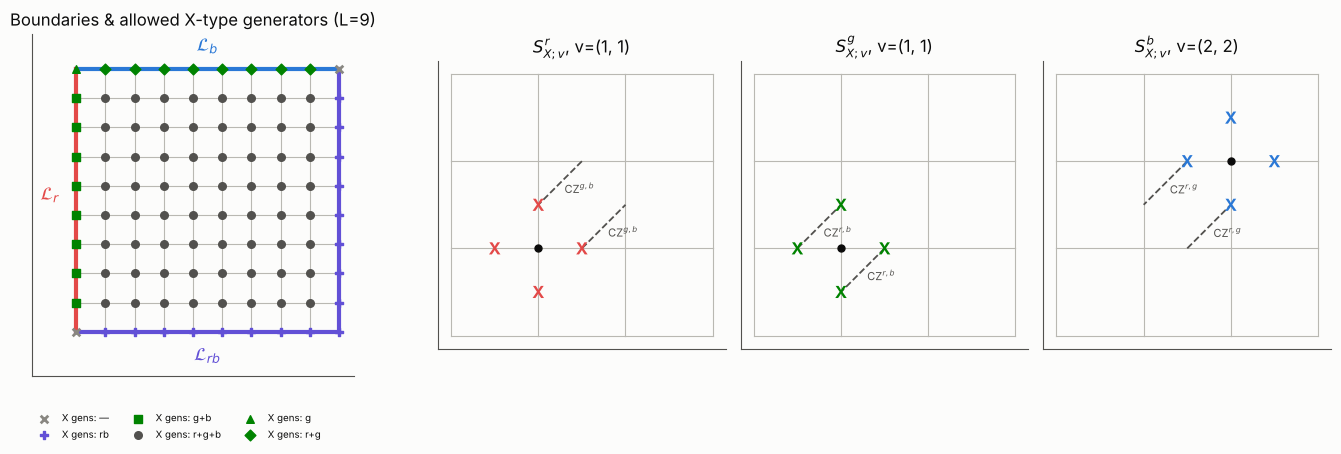

In [36]:
L_FIG = 9
lat = D4Lattice(L_FIG)
types = {}
for v in lat.vertices:
    types[v] = '+'.join(''.join(CNAME[c] for c in combo) for combo in lat.vertex_x_types(v)) or '—'
from collections import Counter as _C
print('X-generator types per vertex class (L=9):')
cls = {}
for v, t in types.items():
    x, y = v
    key = ('bulk' if 0 < x < L_FIG and 0 < y < L_FIG else
           'corner(0,0)' if v == (0, 0) else 'corner(0,L)' if v == (0, L_FIG) else
           'corner(L,L)' if v == (L_FIG, L_FIG) else 'corner(L,0)' if v == (L_FIG, 0) else
           'L_r (left)' if x == 0 else 'L_b (top)' if y == L_FIG else 'L_rb (bottom/right)')
    cls.setdefault(key, set()).add(t)
for k, v in cls.items():
    print(f'  {k:22s}: {sorted(v)}')

fig = plt.figure(figsize=(14, 4.6))
gsp = fig.add_gridspec(1, 4, width_ratios=[1.6, 1, 1, 1])
ax = fig.add_subplot(gsp[0]); ax.grid(False)
bcol = {'Lr': C_R, 'Lb': C_B, 'Lrb': '#6250d6', None: '#b9b8b2'}
for e in range(lat.E):
    (x0, y0), (x1, y1) = lat.endpoints(e)
    bd = lat.boundary_of_edge(e)
    ax.plot([x0, x1], [y0, y1], color=bcol[bd], lw=3 if bd else 0.8, zorder=1)
mk = {'r+g+b': ('o', '#52514e'), 'g+b': ('s', C_G), 'r+g': ('D', C_G), 'g': ('^', C_G), 'rb': ('P', '#6250d6'), '—': ('x', '#898781')}
seen = set()
for v, t in types.items():
    m, c = mk[t]
    ax.scatter(*v, marker=m, color=c, s=30, zorder=3, label=None if t in seen else f'X gens: {t}')
    seen.add(t)
ax.set_title('Boundaries & allowed X-type generators (L=9)')
ax.text(-0.9, L_FIG / 2, r'$\mathcal{L}_r$', color=C_R, fontsize=13, ha='center')
ax.text(L_FIG / 2, L_FIG + 0.6, r'$\mathcal{L}_b$', color=C_B, fontsize=13, ha='center')
ax.text(L_FIG / 2, -1.0, r'$\mathcal{L}_{rb}$', color='#6250d6', fontsize=13, ha='center')
ax.set_aspect('equal'); ax.legend(loc='upper left', bbox_to_anchor=(-0.02, -0.08), fontsize=7, ncol=3)
ax.set_xlim(-1.5, L_FIG + 0.5); ax.set_ylim(-1.5, L_FIG + 1.2); ax.set_xticks([]); ax.set_yticks([])
lat4 = D4Lattice(3)
def mid(q):
    (x0, y0), (x1, y1) = lat4.endpoints(q // 3)
    return (x0 + x1) / 2, (y0 + y1) / 2
for k, (c, col) in enumerate([(R, C_R), (G, C_G), (B, C_B)]):
    ax = fig.add_subplot(gsp[k + 1]); ax.grid(False)
    for e in range(lat4.E):
        (x0, y0), (x1, y1) = lat4.endpoints(e)
        ax.plot([x0, x1], [y0, y1], color='#b9b8b2', lw=0.8)
    v = (1, 1) if c != B else (2, 2)
    if c == G: v = (1, 1)
    op = lat4.SX(v, c)
    ax.scatter(*v, color='#0b0b0b', s=25, zorder=3)
    for qq in op.s:
        x, y = mid(qq); ax.text(x, y, 'X', color=col, ha='center', va='center', fontsize=12, weight='bold')
    for (i, j) in op.quad:
        (xa, ya), (xb, yb) = mid(i), mid(j)
        ax.plot([xa, xb], [ya, yb], ls='--', color='#52514e', lw=1.3)
        cols_ = ''.join(sorted([CNAME[i % 3], CNAME[j % 3]], key='rgb'.index))
        ax.text((xa + xb) / 2 + 0.05, (ya + yb) / 2 - 0.12, f'CZ$^{{{cols_[0]},{cols_[1]}}}$', fontsize=8, color='#52514e')
    ax.set_title(f'$S^{CNAME[c]}_{{X;v}}$, v={v}')
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(f'{FIGURES}/d4_lattice_and_stabilizers.png', dpi=150); plt.show()

右図：$S^r_X$ の CZ$^{g,b}$ は頂点の右上の plaquette（$v$ = 頂点0）、$S^g_X$ の CZ$^{r,b}$ は左上（$v$ = 頂点1）と右下（$v$ = 頂点2）、$S^b_X$ の CZ$^{r,g}$ は左下（$v$ = 頂点3）。これは [KZH] Fig. 4 の破線の位置と一致する。

## I-2. 符号データ：生成元数・論理量子ビット数・符号距離

* $k$：$\dim C_Z - \mathrm{rank}(\text{shifts})$（生成元の $C_Z$ 上での可換性・$S^2=1$ と併せて検証ノートで確認）。
* $d_Z$：論理 $Z$ 型 Pauli の最小重み。$d_X^{\rm shift}$：$C_Z$ に属し安定化子シフトの張る空間に属さない $X$ シフトの最小重み（D4相では CZ 修飾があるため、これは Knill–Laflamme 距離そのものではない。$L=2$ のみ KL 条件を直接検査）。
* いずれも厳密 MILP（HiGHS）。

In [37]:
import time
rows = []
for L in range(1, DIST_L_MAX + 1):
    t0 = time.time()
    lat = D4Lattice(L)
    d4 = CodeData(lat); fsc = CodeData(lat, (R, B), dressed=False)
    c4, cf = code_consistency(d4), code_consistency(fsc)
    dz4, dx4, _, _ = distances(d4); dzf, dxf, _, _ = distances(fsc)
    rows.append(dict(L=L, D4_qubits_incl_frozen=d4.lat.n, D4_xgens=len(d4.xgens), D4_k=c4['k'],
                     D4_commuting_on_CZ=not c4['noncommuting_pairs'], D4_dZ=dz4, D4_dX_shift=dx4,
                     FSC_k=cf['k'], FSC_dZ=dzf, FSC_dX=dxf, seconds=round(time.time() - t0, 2)))
code_df = pd.DataFrame(rows)
code_df.to_csv(f'{RESULTS}/d4_code_table.csv', index=False)
code_df

,L,D4_qubits_incl_frozen,D4_xgens,D4_k,D4_commuting_on_CZ,D4_dZ,D4_dX_shift,FSC_k,FSC_dZ,FSC_dX,seconds
0,1,12,2,1,True,1,4,1,1,4,0.32
1,2,36,11,1,True,2,5,1,2,5,0.06
2,3,72,26,1,True,3,6,1,3,6,0.16
3,4,120,47,1,True,4,7,1,4,7,0.39
4,5,180,74,1,True,5,8,1,5,8,1.16
5,6,252,107,1,True,6,9,1,6,9,2.35
6,7,336,146,1,True,7,10,1,7,10,5.79
7,8,432,191,1,True,8,11,1,8,11,22.46


**結果**：調べた全ての $L$ で $k=1$、$d_Z = L$、$X$ 型シフト距離 $= L+3$（D4・FSC とも）。
* FSC（CSS 符号）の符号距離は厳密に $\min(d_Z,d_X)=L$。
* D4 相（非 Pauli 符号）では $d_Z=L$ の論理 $Z$ があるので距離 $\le L$。下界は検証ノート V5b で、重み $\le L-1$ の全 Pauli が Knill–Laflamme 条件を満たすことを $L\le5$（`FULL_KL=True` で $L=6$）について厳密に示した（$=L$）。それより大きな $L$ では D4 相の距離は**未証明**（上界 $L$ のみ）。
* よって比較の横軸は **$L$（= FSC の距離 = 入出力符号の距離）** であり、「D4 相も距離 $L$」は $L\le5$（6）でのみ証明済みである。$X$ 方向には $3$ だけ余分な距離があり、正方形でない格子で量子ビット数を削れる可能性があるが、[KZH] の Fig. 4 の正方形配置に従う（最適化はしていない）。

## I-3. 段階別の資源計数

資源表（§0 で計算済み）の元になる `D4CostData(L)` は、明示的な格子上で、各段階の回路を**ゲート単位で構成**して数える：
* ラウンド回路：各生成元に測定補助1個。$X$ 型 Clifford 安定化子 $S = X(s)\prod CZ$ は「補助 $|+\rangle$ → CNOT（補助→データ） → CCZ（補助, $i$, $j$） → $X$ 測定」（制御-$S$ による標準的な測定。**この回路は [KZH] には書かれておらず本研究の構成**。正しさは検証ノートで密行列により確認）。
* frozen 量子ビット（境界の単一量子ビット $Z$ 安定化子で $|0\rangle$ に固定）は割り当てず、それに作用するゲート（恒等になる）も除く。$\mathcal L_{rb}$ の $g$ 量子ビットを除くため、そこでの $V$ の CNOT 対（$Z^rZ^b=+1$ 上で恒等）も除く。
* S3 の CZ 補正は最悪ケース（全頂点）で数える（期待値はその半分；$\kappa$ が一様であることは検証ノートで統計的に確認）。

### I-3.1 段階別の表（$d=9$、`FT_ref`、比較A、原始ゲートセット、データ＋測定補助）
`rounds` は符号ごとのラウンド数（S0, S4 は FSC のラウンド、S1 は D4 のラウンド）。`time_lb/ub` は物理時間（全ゲート1単位の仮定）の下界／上界。`source` は値の出所（文献／明示的回路からの計数／仮定パラメータ／未解決）。

In [38]:
d_show = 9 if 9 in D_LIST else D_LIST[-1]
view = d4st[(d4st.d == d_show) & (d4st.model == 'FT_ref') & (d4st.comparison == 'A') &
                (d4st.gateset == 'primitive') & (~d4st.data_only)]
view[['stage', 'qubits', 'rounds', 'time_lb', 'time_ub', 'gates', 'source']]

,stage,qubits,rounds,time_lb,time_ub,gates,source
288,S0 FSC |+_L> preparation,683,9,73.0,127,"{""INIT_X"": 1791.0, ""INIT_Z"": 1782.0, ""CNOT"": 1...",assumption (parameter)
289,S1 switch-in (gauging) to D4,1007,9,81.0,252,"{""INIT_X"": 2178.0, ""CNOT"": 17442.0, ""CCZ"": 345...",assumption (parameter)
290,S2 transversal U = W V (logical T^dag),504,0,5.0,5,"{""CNOT"": 306.0, ""CS"": 81.0, ""CSDG"": 64.0, ""TDG...",counted (explicit circuit)
291,S3 switch-out: Z^g meas + S^g correction,504,0,2.0,2,"{""MEAS_Z"": 162.0, ""CZ"": 128.0}",counted (explicit circuit)
292,S4 FSC error-correction rounds,683,9,72.0,126,"{""INIT_X"": 1449.0, ""CNOT"": 11934.0, ""MEAS_X"": ...",assumption (parameter)
293,S5 logical X frame: T^dag|+> -> T|+>,0,0,0.0,0,{},counted (explicit circuit)


### I-3.2 1ラウンドあたりのコストと定数深さ段階

In [39]:
rows = []
for d in D_LIST:
    b = blocks[f'{d}|primitive']; bd = blocks[f'{d}|clifford_t']
    rows.append(dict(d=d, FSC_round_lb=b['round']['FSC']['time_lb'], FSC_round_ub=b['round']['FSC']['time_ub'],
                     D4_round_lb=b['round']['D4']['time_lb'], D4_round_ub=b['round']['D4']['time_ub'],
                     D4_round_ub_cliffordT=bd['round']['D4']['time_ub'], D4g_round_ub=b['round']['D4g']['time_ub'],
                     CCZ_per_D4_round=b['round']['D4']['gates'].get('CCZ', 0),
                     CNOT_per_D4_round=b['round']['D4']['gates'].get('CNOT', 0),
                     U_depth_time=b['U_time'], switch_out_time=b['out_time'],
                     U_CS=b['U_gates'].get('CS', 0) + b['U_gates'].get('CSDG', 0), U_TDG=b['U_gates'].get('TDG', 0)))
per_round_df = pd.DataFrame(rows); per_round_df

,d,FSC_round_lb,FSC_round_ub,D4_round_lb,D4_round_ub,D4_round_ub_cliffordT,D4g_round_ub,CCZ_per_D4_round,CNOT_per_D4_round,U_depth_time,switch_out_time,U_CS,U_TDG
0,3,8.0,14,9.0,28,60,8,24,210,5,2,13,6
1,5,8.0,14,9.0,28,60,8,96,594,5,2,41,10
2,7,8.0,14,9.0,28,60,8,216,1170,5,2,85,14
3,9,8.0,14,9.0,28,60,8,384,1938,5,2,145,18
4,11,8.0,14,9.0,28,60,8,600,2898,5,2,221,22
5,13,8.0,14,9.0,28,60,8,864,4050,5,2,313,26
6,15,8.0,14,9.0,28,60,8,1176,5394,5,2,421,30


## I-4. 符号距離に対するスケーリング（厳密な多項式の同定）

数値はすべて明示的な格子上の計数なので、$L$ の多項式になることが期待される。最初の4点で補間した（高々3次の）多項式が**残りすべての点で厳密に一致するか**を確認する（一致しなければ「多項式ではない／境界の効果がまだある」と表示）。これは評価範囲の $L$ についての恒等式の確認であり、全ての $L$ についての証明ではない（ただし量子ビット数・ゲート数は格子の局所構造から $L$ の2次式、体積は $\lceil\kappa d\rceil$ ラウンドを掛けて3次式になる）。

In [40]:
import sympy
x = sympy.Symbol('d')
def identify(values):
    Ls = sorted(values)
    if len(Ls) < 5:
        return None, False
    p = sympy.interpolate([(L, values[L]) for L in Ls[:4]], x)      # cubic through 4 points
    ok = all(sympy.nsimplify(p.subs(x, L) - values[L]) == 0 for L in Ls)
    return sympy.expand(p), ok
quant = {
    'peak qubits (D4 phase: data+anc)': {d: blocks[f'{d}|primitive']['n_total'] for d in D_LIST},
    'FSC qubits (data+anc)': {d: blocks[f'{d}|primitive']['n']['fsc_data'] + blocks[f'{d}|primitive']['n']['fsc_anc'] for d in D_LIST},
    'D4 data qubits': {d: blocks[f'{d}|primitive']['n']['d4_data'] for d in D_LIST},
    'CCZ per D4 round': {d: blocks[f'{d}|primitive']['round']['D4']['gates'].get('CCZ', 0) for d in D_LIST},
    'CNOT per D4 round': {d: blocks[f'{d}|primitive']['round']['D4']['gates'].get('CNOT', 0) for d in D_LIST},
}
for comp in ['A']:
    for model in ['FT_ref', 'NL_min']:
        sel = d4s[(d4s.model == model) & (d4s.comparison == comp) & (d4s.gateset == 'primitive') & (~d4s.data_only)]
        quant[f'V [qubit*round] {model}'] = dict(zip(sel.d, sel.V_qubit_round))
        quant[f'V [qubit*time] lb {model}'] = dict(zip(sel.d, sel.V_qubit_time_lb))
        quant[f'V [qubit*time] ub {model}'] = dict(zip(sel.d, sel.V_qubit_time_ub))
        quant[f'rounds {model}'] = dict(zip(sel.d, sel.rounds))
poly_rows = []
for k, v in quant.items():
    p, ok = identify({d: int(round(val)) for d, val in v.items()})
    poly_rows.append(dict(quantity=k, polynomial_in_d=str(p), exact_on_all_points=ok))
poly_df = pd.DataFrame(poly_rows); poly_df.to_csv(f'{RESULTS}/d4_polynomials.csv', index=False); poly_df

,quantity,polynomial_in_d,exact_on_all_points
0,peak qubits (D4 phase: data+anc),12*d**2 + 4*d - 1,True
1,FSC qubits (data+anc),8*d**2 + 4*d - 1,True
2,D4 data qubits,6*d**2 + 2*d,True
3,CCZ per D4 round,6*d**2 - 12*d + 6,True
4,CNOT per D4 round,24*d**2 - 6,True
5,V [qubit*round] FT_ref,28*d**3 + 12*d**2 - 3*d,True
6,V [qubit*time] lb FT_ref,236*d**3 + 150*d**2 - 7*d - 1,True
7,V [qubit*time] ub FT_ref,560*d**3 + 274*d**2 - 38*d - 1,True
8,rounds FT_ref,3*d,True
9,V [qubit*round] NL_min,15*d**2 + 6*d - 1,True


`FT_ref` の体積の多項式は $\kappa_0=\kappa_{in}=\kappa_{out}=1$（**仮定**）に対するもの。一般の $\kappa$ では、主要項は
$$V_{\rm qubit\cdot round}\simeq \big(8\kappa_0 + 12\kappa_{in} + 8\kappa_{out}\big)\,d^3$$
（FSC 相の量子ビット数 $=8d^2+4d-1$、D4 相 $=12d^2+4d-1$、いずれもデータ＋測定補助）。

## I-5. 図：段階別の内訳と量子ビット数

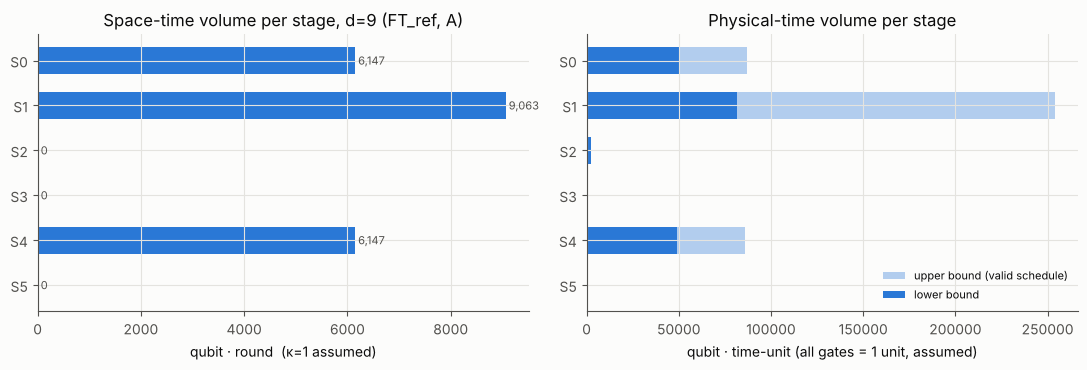

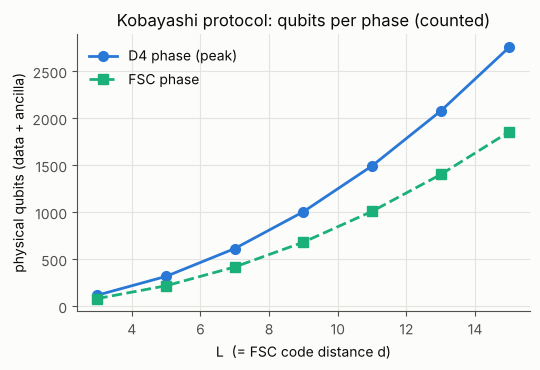

In [41]:
sel = d4st[(d4st.d == d_show) & (d4st.model == 'FT_ref') & (d4st.comparison == 'A') &
               (d4st.gateset == 'primitive') & (~d4st.data_only)].copy()
sel['V_round'] = sel.qubits * sel.rounds
sel['V_time_lb'] = sel.qubits * sel.time_lb
sel['V_time_ub'] = sel.qubits * sel.time_ub
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
lab = [s.split(' ')[0] for s in sel.stage]
axes[0].barh(lab, sel.V_round, color=C_KOB, height=0.6)
axes[0].invert_yaxis(); axes[0].set_xlabel('qubit · round  (κ=1 assumed)')
axes[0].set_title(f'Space-time volume per stage, d={d_show} (FT_ref, A)')
for i, v in enumerate(sel.V_round):
    axes[0].text(v, i, f' {int(v):,}', va='center', fontsize=8, color='#52514e')
axes[1].barh(lab, sel.V_time_ub, color=C_KOB, alpha=0.35, height=0.6, label='upper bound (valid schedule)')
axes[1].barh(lab, sel.V_time_lb, color=C_KOB, height=0.6, label='lower bound')
axes[1].invert_yaxis(); axes[1].set_xlabel('qubit · time-unit (all gates = 1 unit, assumed)')
axes[1].set_title('Physical-time volume per stage'); axes[1].legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIGURES}/d4_stage_breakdown.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ds = np.array(D_LIST)
ax.plot(ds, [blocks[f'{d}|primitive']['n_total'] for d in D_LIST], 'o-', color=C_KOB, label='D4 phase (peak)')
ax.plot(ds, [blocks[f'{d}|primitive']['n']['fsc_data'] + blocks[f'{d}|primitive']['n']['fsc_anc'] for d in D_LIST],
        's--', color=C_AUX, label='FSC phase')
ax.set_xlabel('L  (= FSC code distance d)'); ax.set_ylabel('physical qubits (data + ancilla)')
ax.set_title('Kobayashi protocol: qubits per phase (counted)'); ax.legend()
plt.tight_layout(); plt.savefig(f'{FIGURES}/d4_qubits_vs_d.png', dpi=150); plt.show()

## I-6. 解釈と注意

* **数えたもの**：明示的な格子・回路から数えた量子ビット数、ゲート数、ラウンドあたりの物理時間（下界・上界）。
* **仮定に依存するもの**：`FT_ref` のラウンド数（$\kappa$）。[KZH] は $O(d)$ としか述べておらず、JIT decoder の文献 [Dav] の全文は本環境から参照できなかった。ゲート所要時間（全て1単位）。
* **数えていないもの**：JIT decoder／matching・RG decoder の古典計算時間、制御系の遅延、FSC→通常パッチ変換（比較Bで未解決として扱う）。
* D4 相の 1 ラウンドは CCZ を含むため、FSC や回転表面符号の 1 ラウンドより深い（上の表）。**異なる符号のラウンド数を同一の時間単位とみなさない**ため、比較では物理時間でも示す。
* `FT_ref` では物理 CCZ が $6(d-1)^2$ 個／ラウンド × $\lceil\kappa_{in}d\rceil$ ラウンド $=\Theta(d^3)$ 必要になる。ノイズなしでは問題にならないが、ノイズありの拡張では重要な資源になる（比較Bで T 数としても表示）。

# 第II部 Litinski 方式：15-to-1 magic state distillation

**目的**：Litinski *A Game of Surface Codes* [Lit] Sec. 3 の 15-to-1 プロトコル（Fig. 15 の回路を Fig. 17c の 11 tiles 配置で実行）を、
1. **tile モデル**（[Lit] の計数：1 tile = $d^2$ データ量子ビット（測定量子ビット込みで $2d^2$）、1 time step (τ) = $d$ code cycles）、
2. **物理モデル**（11 回の多パッチ測定 $P\otimes Z_m$ を Fig. 17c の配置上で**検査レベルまで明示的に構成**し（正しさは検証ノート M9）、各回転の量子ビット数・CNOT 数・ラウンドの物理時間（D4 側と同じスケジューラ）を数える。$Z_m\otimes Y_0$ の twist 継ぎ目の検査だけは構成していない）
の2通りで計数する。正しさの検証は `MSD_15to1_validation.ipynb`。

**15-to-1 の抽象回路（Reed–Muller 符号上の回路）だけを数えて lattice surgery の物理コストと同一視することはしない**：ここで数えるのは Fig. 17c の配置上の操作である。

### 段階（Fig. 17c）
| 段階 | 内容 | 時間 | 出所 |
|---|---|---|---|
| L0 | （比較Bのみ）qubits 1–4 への $|m\rangle$ 注入（並列） | $t_{\rm inj}$ | [Lit] App. A（Li の方法、3+3 cycles、$d$ に依存しない） |
| L1 | qubit 5 を $|+\rangle$ に初期化 | 0τ | [Lit] Sec. 1 |
| L2.k | auto-corrected π/8 回転 k（k=1..11）：$P\otimes Z_m$ と $Z_m\otimes Y_0$ の格子手術 | 1τ = $d$ ラウンド | [Lit] Fig. 17b,c |
| L2.ka | （比較Bのみ）回転 k 用の $|m\rangle$ 注入（11-tile 配置では直列） | $t_{\rm inj}$ | [Lit] Sec. 3.3 "Caveat" |
| L2.kb | $|0\rangle$ の X/Z 測定、$|m\rangle$ の X 測定 | 0τ（測定1層） | [Lit] |
| L3 | qubits 1–4 の X 測定 | 0τ | [Lit] |
| L4 | 論理 $\bar X$（Pauli フレーム）で $T^\dagger|+\rangle\to T|+\rangle$ | 0 | 本研究（D4 側と同じ扱い） |

**比較A**：入力 $|m\rangle$ は供給済み（L0, L2.ka を含めない）。**比較B**：注入時間と物理 T ゲート（15個）を含める。古典処理時間は両比較とも 0（**仮定**）。

## II-1. 論理回路（式(1) → Fig. 15）
式(1)の行列 $M$ の列ごとに $Z$ 型 π/8 回転を置く。1列目〜4列目（重み1）は qubits 4,3,2,1 の初期状態 $|m\rangle$ に吸収され、残り 11 列が Fig. 15 の 11 回転になる（[Lit] Sec. 3.1）。

In [42]:
rots = fig15_rotations()
pd.DataFrame([{'rotation': k + 1, **{f'q{i + 1}': ('Z' if i in r else '1') for i in range(5)}} for k, r in enumerate(rots)])

,rotation,q1,q2,q3,q4,q5
0,1,1,1,Z,Z,Z
1,2,1,Z,1,Z,Z
2,3,1,Z,Z,1,Z
3,4,1,Z,Z,Z,1
4,5,Z,1,1,Z,Z
5,6,Z,1,Z,1,Z
6,7,Z,1,Z,Z,1
7,8,Z,Z,1,1,Z
8,9,Z,Z,1,Z,1
9,10,Z,Z,Z,1,1


## II-2. tile モデル（Fig. 17c の再計数）
配置を 3×5 の格子として転記した（`FIG17C_*`）。灰色の未使用 tile は数えない。

tiles used = 11, time steps = 11 tau, tile*tau = 121
leading-order space-time cost: 121 d^3 (data qubits x cycles; [Lit] 121 d^3) / 242 d^3 (incl. measurement qubits, 2d^2 per tile, [Lit] Sec. 4.3)


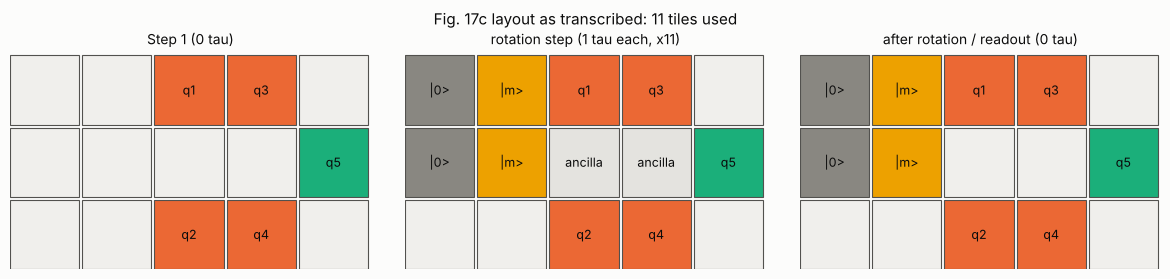

In [43]:
sched = tile_schedule()
used = tiles_used(sched)
n_tiles = len(used); n_tau = sum(t for _, t, _ in sched)
print(f'tiles used = {n_tiles}, time steps = {n_tau} tau, tile*tau = {n_tiles * n_tau}')
print(f'leading-order space-time cost: {n_tiles * n_tau} d^3 (data qubits x cycles; [Lit] 121 d^3)'
      f' / {2 * n_tiles * n_tau} d^3 (incl. measurement qubits, 2d^2 per tile, [Lit] Sec. 4.3)')
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
colors = {'q1': C_LIT, 'q2': C_LIT, 'q3': C_LIT, 'q4': C_LIT, 'q5': C_AUX, 'm': '#eda100', 'zero': '#898781', 'anc': '#e4e3df'}
for ax, (title, lay) in zip(axes, [('Step 1 (0 tau)', FIG17C_STEP1), ('rotation step (1 tau each, x11)', FIG17C_ROTATION),
                                   ('after rotation / readout (0 tau)', FIG17C_FINAL)]):
    for i, row in enumerate(lay):
        for j, lab in enumerate(row):
            fc = colors.get(lab, '#fcfcfb') if lab else '#f0efec'
            ax.add_patch(plt.Rectangle((j, 2 - i), 0.96, 0.96, fc=fc, ec='#52514e', lw=0.8))
            if lab: ax.text(j + 0.48, 2 - i + 0.48, {'zero': '|0>', 'm': '|m>', 'anc': 'ancilla'}.get(lab, lab), ha='center', va='center', fontsize=9)
    ax.set_xlim(0, 5); ax.set_ylim(0, 3); ax.set_aspect('equal'); ax.axis('off'); ax.set_title(title, fontsize=10)
plt.suptitle(f'Fig. 17c layout as transcribed: {n_tiles} tiles used', fontsize=11)
plt.tight_layout(); plt.savefig(f'{FIGURES}/msd_fig17c_layout.png', dpi=150); plt.show()

## II-3. tile → 物理量子ビット・cycle への対応

| 量 | tile モデル | 物理モデル（本研究、明示的構成） |
|---|---|---|
| 1 tile | $d^2$ データ（[Lit] Sec. 1）、$2d^2$ 測定込み（[Lit] Sec. 4.3） | $d\times d$ データ量子ビットの領域 |
| qubits 1–5 | 1 tile ずつ | 回転表面符号パッチ。補助帯に面する辺を「$Z$ 辺」（重み2 の $X$ 検査）にする |
| $|m\rangle$ | 2 tiles | 2 tile の縦長パッチ。角を移動（[Lit] Fig. 2b）し、右辺下半分（補助帯側）と左辺（$|0\rangle$ 側）を $Z$ 辺にする |
| $|0\rangle$ | 2 tiles | 縦長の回転表面符号パッチ |
| 補助帯 | 2 tiles | 全量子ビットを $|+\rangle$ に初期化し、補助帯に触れる plaquette（合併領域に制限）を新たに測る。参加しないパッチに面する辺・自由辺は「$X$ 辺」（重み2 の $Z$ 検査）、両側が自由な角の量子ビットは $Z$ 測定 |
| 合併中に測る検査 | — | 新しい検査 $N$ ＋ $N$ と可換な旧パッチ検査 ＋ 可換部分群を完成させる旧検査の積（すべて重み ≤ 4、$\mathbb F_2$ 計算で決定） |
| 1τ | $d$ code cycles | $d$ ラウンド（`FT_ref`）／1 ラウンド（`NL_min`） |
| 1 ラウンドの物理時間 | — | 各回転の検査集合を D4 側と同じ可換クラス・スケジューラで計算（下界・上界） |

**構成していない部分**：$|m\rangle$ と $|0\rangle$ の間の $Z_m\otimes Y_0$ 測定（twist 欠陥を含む継ぎ目、$O(d)$ 個の測定量子ビット）。`source` 列と第III部の「未計上コスト」に明記する。

In [44]:
msd_per_d    # per-d physical counts (computed in §0)

,d,rotation_qubits_min,rotation_qubits_max,idle_qubits,rotation_round_lb,rotation_round_ub,CNOT_per_round_max,tile_model_rotation_qubits,isolated_patch_round_lb,isolated_patch_round_ub
0,3,192,192,155,6.0,12,319,198,6.0,12
1,5,544,544,443,6.0,12,971,550,6.0,12
2,7,1072,1072,875,6.0,12,1975,1078,6.0,12
3,9,1776,1776,1451,6.0,12,3331,1782,6.0,12
4,11,2656,2656,2171,6.0,12,5039,2662,6.0,12
5,13,3712,3712,3035,6.0,12,7099,3718,6.0,12
6,15,4944,4944,4043,6.0,12,9511,4950,6.0,12


### II-3.1 要約（`FT_ref`、データ＋測定量子ビット）

In [45]:
cols = ['d', 'comparison', 'level', 'peak_qubits', 'rounds', 'time_lb', 'time_ub', 'V_qubit_round', 'V_qubit_time_lb', 'V_qubit_time_ub', 'nonclifford']
msds[(msds.model == 'FT_ref') & (~msds.data_only) & (msds.gateset == 'primitive')][cols]

,d,comparison,level,peak_qubits,rounds,time_lb,time_ub,V_qubit_round,V_qubit_time_lb,V_qubit_time_ub,nonclifford
0,3,A,tile,198,33,210.0,408,6534,41148.0,80352,{}
2,3,B,tile,198,105,642.0,1272,18198,111132.0,220320,"{""T"": 15.0}"
16,3,A,physical,192,33,210.0,408,6336,39876.0,77892,{}
18,3,B,physical,192,105,642.0,1272,17496,106836.0,211812,"{""T"": 15.0}"
32,5,A,tile,550,55,342.0,672,30250,186900.0,368400,{}
34,5,B,tile,550,127,774.0,1536,62650,381300.0,757200,"{""T"": 15.0}"
48,5,A,physical,544,55,342.0,672,29920,184836.0,364356,{}
50,5,B,physical,544,127,774.0,1536,61816,376212.0,747108,"{""T"": 15.0}"
64,7,A,tile,1078,77,474.0,936,83006,508620.0,1006656,{}
66,7,B,tile,1078,149,906.0,1800,146510,889644.0,1768704,"{""T"": 15.0}"


## II-4. スケーリング（厳密な多項式の同定）と [Lit] の値の再現

In [46]:
import sympy
x = sympy.Symbol('d')
def identify(values):
    Ls = sorted(values)
    p = sympy.interpolate([(L, values[L]) for L in Ls[:4]], x)
    return sympy.expand(p), all(sympy.nsimplify(p.subs(x, L) - values[L]) == 0 for L in Ls)
rows = []
for level in ['tile', 'physical']:
    for data_only in [True, False]:
        for comp in ['A', 'B']:
            for model in ['FT_ref', 'NL_min']:
                sel = msds[(msds.level == level) & (msds.data_only == data_only) & (msds.comparison == comp) &
                             (msds.model == model) & (msds.gateset == 'primitive')]
                for q in ['V_qubit_round', 'peak_qubits', 'rounds']:
                    p, ok = identify({int(dd): int(round(v)) for dd, v in zip(sel.d, sel[q])})
                    rows.append(dict(level=level, data_only=data_only, comparison=comp, model=model, quantity=q,
                                     polynomial=str(p), exact_on_all_points=ok))
poly = pd.DataFrame(rows); poly.to_csv(f'{RESULTS}/msd_polynomials.csv', index=False)
poly[(poly.model == 'FT_ref') & (poly.quantity == 'V_qubit_round')]

,level,data_only,comparison,model,quantity,polynomial,exact_on_all_points
0,tile,True,A,FT_ref,V_qubit_round,121*d**3,True
6,tile,True,B,FT_ref,V_qubit_round,121*d**3 + 648*d**2,True
12,tile,False,A,FT_ref,V_qubit_round,242*d**3,True
18,tile,False,B,FT_ref,V_qubit_round,242*d**3 + 1296*d**2,True
24,physical,True,A,FT_ref,V_qubit_round,121*d**3,True
30,physical,True,B,FT_ref,V_qubit_round,121*d**3 + 648*d**2,True
36,physical,False,A,FT_ref,V_qubit_round,242*d**3 - 66*d,True
42,physical,False,B,FT_ref,V_qubit_round,242*d**3 + 1296*d**2 - 66*d - 504,True


tile モデル・データのみ・比較A で $V = 121\,d^3$（[Lit] の値）、測定量子ビット込みで $242\,d^3$、物理モデル（明示的構成）では $242d^3-66d$（各回転の量子ビット数は $22d^2-6$）となる。旧版の近似（$22d^2-5$）との差は 1 量子ビット／回転で、ラウンドの物理時間も同じ（下界 6、上界 12）だった。比較Bでは注入時間 $12\,t_{\rm inj}$ cycles 分（$d$ に依存しない）が加わる。

## II-5. 図：時間に沿った量子ビット使用数（$d=9$、`FT_ref`、物理モデル、比較B）

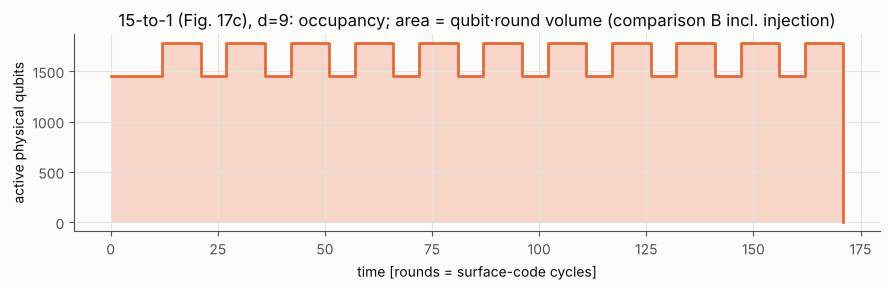

In [47]:
d_show = 9 if 9 in D_LIST else D_LIST[-1]
sel = msdst[(msdst.d == d_show) & (msdst.model == 'FT_ref') & (msdst.comparison == 'B') &
               (msdst.level == 'physical') & (~msdst.data_only) & (msdst.gateset == 'primitive')]
t, xs, ys = 0, [], []
for _, r in sel.iterrows():
    xs += [t, t + r.rounds]; ys += [r.qubits, r.qubits]; t += r.rounds
fig, ax = plt.subplots(figsize=(9, 3))
ax.fill_between(xs, ys, step=None, color=C_LIT, alpha=0.25, lw=0)
ax.plot(xs, ys, color=C_LIT)
ax.set_xlabel('time [rounds = surface-code cycles]'); ax.set_ylabel('active physical qubits')
ax.set_title(f'15-to-1 (Fig. 17c), d={d_show}: occupancy; area = qubit·round volume (comparison B incl. injection)')
plt.tight_layout(); plt.savefig(f'{FIGURES}/msd_occupancy_timeline.png', dpi=150); plt.show()

## II-6. 解釈と注意
* tile モデルは [Lit] の値（11 tiles, 11τ, $121d^3$）を再現する（検証ノートで確認）。
* 物理モデル（明示的構成）との差は $O(d)$ の下位項のみ。ただし $Z_m\otimes Y_0$ の twist 継ぎ目の検査（$O(d)$ 個）は未計上。
* **含めていない費用**：古典処理（デコード・測定結果に応じた基底選択）の時間、Fig. 18 の追加 2×2 ブロックによる注入の並列化（tile 数が増える代わりに注入待ちが消える）、$Z_m\otimes Y_0$ の twist 欠陥の詳細な安定化子配置。
* ノイズが無い場合は蒸留そのものが不要（理想入力 $|m\rangle$ がそのまま出力品質）であり、ここでの比較は**回路構造と資源の比較**である（冒頭「理想条件の限界」）。

# 第III部 比較（同じ計数ルール・同じ資源表）
以下はすべて §0 の資源表から計算する。

## III-1. 段階別の資源コスト一覧（$d=9$、`FT_ref`、比較A、データ＋測定量子ビット、原始ゲートセット）

In [48]:
d_show = 9 if 9 in D_LIST else D_LIST[len(D_LIST) // 2]
a = d4st[(d4st.d == d_show) & (d4st.model == 'FT_ref') & (d4st.comparison == 'A') & (d4st.gateset == 'primitive') & (~d4st.data_only)]
b = msdst[(msdst.d == d_show) & (msdst.model == 'FT_ref') & (msdst.comparison == 'A') & (msdst.gateset == 'primitive') &
          (~msdst.data_only) & (msdst.level == 'physical')]
# compress Litinski's 11 identical rotations into one row (x11)
def compress(df):
    out = []; rot = df[df.stage.str.contains('auto-corrected')]; rd = df[df.stage.str.contains('readout')]
    for _, r in df.iterrows():
        if 'auto-corrected' in r.stage or 'readout' in r.stage: continue
        out.append(r.to_dict())
    for sub, name in [(rot, 'L2 auto-corrected pi/8 rotation (x11)'), (rd, 'L2b readout |0>,|m> (x11)')]:
        if len(sub):
            r = sub.iloc[0].to_dict(); r.update(stage=name, rounds=sub.rounds.sum(), time_lb=sub.time_lb.sum(), time_ub=sub.time_ub.sum())
            out.append(r)
    return pd.DataFrame(out)
tab = pd.concat([a.assign(V_qubit_round=a.qubits * a.rounds), compress(b).assign(V_qubit_round=lambda x: x.qubits * x.rounds)])
tab = tab[['protocol', 'stage', 'qubits', 'rounds', 'time_lb', 'time_ub', 'V_qubit_round', 'source']]
tab.to_csv(f'{RESULTS}/comparison_stage_table_d{d_show}.csv', index=False)
tab

,protocol,stage,qubits,rounds,time_lb,time_ub,V_qubit_round,source
288,Kobayashi_D4,S0 FSC |+_L> preparation,683,9,73.0,127,6147,assumption (parameter)
289,Kobayashi_D4,S1 switch-in (gauging) to D4,1007,9,81.0,252,9063,assumption (parameter)
290,Kobayashi_D4,S2 transversal U = W V (logical T^dag),504,0,5.0,5,0,counted (explicit circuit)
291,Kobayashi_D4,S3 switch-out: Z^g meas + S^g correction,504,0,2.0,2,0,counted (explicit circuit)
292,Kobayashi_D4,S4 FSC error-correction rounds,683,9,72.0,126,6147,assumption (parameter)
293,Kobayashi_D4,S5 logical X frame: T^dag|+> -> T|+>,0,0,0.0,0,0,counted (explicit circuit)
0,Litinski_15to1,L1 init qubit 5 |+> (step 1),1451,0,0.0,0,0,literature
1,Litinski_15to1,L3 X measurement of qubits 1-4,1451,0,1.0,1,0,literature
2,Litinski_15to1,L4 logical X frame: T^dag|+> -> T|+>,0,0,0.0,0,0,counted (explicit circuit)
3,Litinski_15to1,L2 auto-corrected pi/8 rotation (x11),1776,99,594.0,1188,175824,counted (explicit circuit)


`rounds` は Kobayashi では FSC／D4 のラウンド、Litinski では回転表面符号のラウンド。単位が違うので、横並びにする量は物理時間（`time_lb/ub`、全ゲート1単位の仮定）である。

## III-2. 主比較：$d$ 依存性（`FT_ref`、比較A、データ＋測定量子ビット）

In [49]:
def pick(df, **kw):
    m = np.ones(len(df), bool)
    for k, v in kw.items(): m &= (df[k] == v).values
    return df[m].sort_values('d')
K = pick(d4s, model='FT_ref', comparison='A', gateset='primitive', data_only=False)
Lp = pick(msds, model='FT_ref', comparison='A', gateset='primitive', data_only=False, level='physical')
Lt = pick(msds, model='FT_ref', comparison='A', gateset='primitive', data_only=False, level='tile')
main = pd.DataFrame(dict(d=K.d.values,
    K_peak_qubits=K.peak_qubits.values, L_peak_qubits=Lp.peak_qubits.values,
    K_rounds=K.rounds.values, L_rounds=Lp.rounds.values,
    K_time_lb=K.time_lb.values, K_time_ub=K.time_ub.values, L_time_lb=Lp.time_lb.values, L_time_ub=Lp.time_ub.values,
    K_V_qr=K.V_qubit_round.values, L_V_qr=Lp.V_qubit_round.values, L_V_qr_tile_lit=Lt.V_qubit_round.values,
    K_V_t_lb=K.V_qubit_time_lb.values, K_V_t_ub=K.V_qubit_time_ub.values, L_V_t_lb=Lp.V_qubit_time_lb.values, L_V_t_ub=Lp.V_qubit_time_ub.values))
main['ratio_peak_qubits'] = main.K_peak_qubits / main.L_peak_qubits
main['ratio_V_qubit_round'] = main.K_V_qr / main.L_V_qr
main['ratio_V_time_lb'] = main.K_V_t_lb / main.L_V_t_lb
main['ratio_V_time_ub'] = main.K_V_t_ub / main.L_V_t_ub
main['ratio_V_time_range'] = [f'{min(x, y):.3f}–{max(x, y):.3f}' for x, y in
                              zip(main.K_V_t_lb / main.L_V_t_ub, main.K_V_t_ub / main.L_V_t_lb)]
main.to_csv(f'{RESULTS}/comparison_main_FT_ref_A.csv', index=False)
main.round(3)

,d,K_peak_qubits,L_peak_qubits,K_rounds,L_rounds,K_time_lb,K_time_ub,L_time_lb,L_time_ub,K_V_qr,...,L_V_qr_tile_lit,K_V_t_lb,K_V_t_ub,L_V_t_lb,L_V_t_ub,ratio_peak_qubits,ratio_V_qubit_round,ratio_V_time_lb,ratio_V_time_ub,ratio_V_time_range
0,3,119,192,9,33,83.0,176,210.0,408,855,...,6534,7700.0,17471,39876.0,77892,0.620,0.135,0.193,0.224,0.099–0.438
1,5,319,544,15,55,133.0,288,342.0,672,3785,...,30250,33214.0,76659,184836.0,364356,0.586,0.127,0.180,0.210,0.091–0.415
2,7,615,1072,21,77,183.0,400,474.0,936,10171,...,83006,88248.0,205239,505764.0,1001028,0.574,0.123,0.174,0.205,0.088–0.406
3,9,1007,1776,27,99,233.0,512,606.0,1200,21357,...,176418,184130.0,430091,1072356.0,2127300,0.567,0.121,0.172,0.202,0.087–0.401
4,11,1495,2656,33,121,283.0,624,738.0,1464,38687,...,322102,332188.0,778095,1954308.0,3882564,0.563,0.120,0.170,0.200,0.086–0.398
5,13,2079,3712,39,143,333.0,736,870.0,1728,63505,...,531674,543750.0,1276131,3221316.0,6406212,0.560,0.120,0.169,0.199,0.085–0.396
6,15,2759,4944,45,165,383.0,848,1002.0,1992,97155,...,816750,830144.0,1951079,4943076.0,9837636,0.558,0.119,0.168,0.198,0.084–0.395


* `ratio_V_time_lb` は両方式の下界同士、`ratio_V_time_ub` は上界同士の比。`ratio_V_time_range` は最も保守的な範囲（K下界/L上界 〜 K上界/L下界）。
* Kobayashi の値は $\kappa_0=\kappa_{in}=\kappa_{out}=1$（**仮定**）に依存する。下の III-4 で $\kappa$ 依存性を示す。

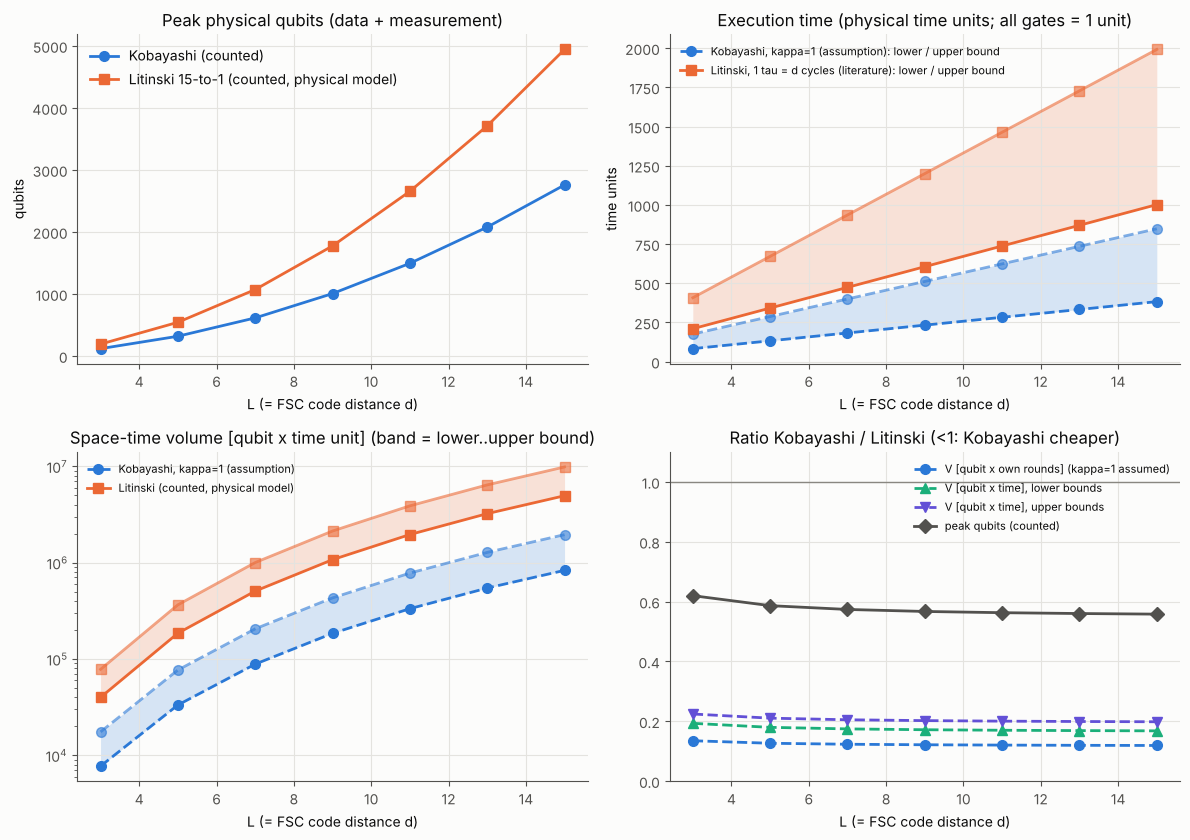

In [50]:
ds = main.d.values
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
ax = axes[0, 0]
ax.plot(ds, main.K_peak_qubits, 'o-', color=C_KOB, label='Kobayashi (counted)')
ax.plot(ds, main.L_peak_qubits, 's-', color=C_LIT, label='Litinski 15-to-1 (counted, physical model)')
ax.set_title('Peak physical qubits (data + measurement)'); ax.set_xlabel('L (= FSC code distance d)'); ax.set_ylabel('qubits'); ax.legend()
ax = axes[0, 1]
ax.fill_between(ds, main.K_time_lb, main.K_time_ub, color=C_KOB, alpha=0.18, lw=0)
ax.plot(ds, main.K_time_lb, 'o--', color=C_KOB, label='Kobayashi, kappa=1 (assumption): lower / upper bound')
ax.plot(ds, main.K_time_ub, 'o--', color=C_KOB, alpha=0.6)
ax.fill_between(ds, main.L_time_lb, main.L_time_ub, color=C_LIT, alpha=0.18, lw=0)
ax.plot(ds, main.L_time_lb, 's-', color=C_LIT, label='Litinski, 1 tau = d cycles (literature): lower / upper bound')
ax.plot(ds, main.L_time_ub, 's-', color=C_LIT, alpha=0.6)
ax.set_title('Execution time (physical time units; all gates = 1 unit)'); ax.set_xlabel('L (= FSC code distance d)'); ax.set_ylabel('time units'); ax.legend(fontsize=8)
ax = axes[1, 0]
ax.fill_between(ds, main.K_V_t_lb, main.K_V_t_ub, color=C_KOB, alpha=0.18, lw=0)
ax.plot(ds, main.K_V_t_lb, 'o--', color=C_KOB, label='Kobayashi, kappa=1 (assumption)')
ax.plot(ds, main.K_V_t_ub, 'o--', color=C_KOB, alpha=0.6)
ax.fill_between(ds, main.L_V_t_lb, main.L_V_t_ub, color=C_LIT, alpha=0.18, lw=0)
ax.plot(ds, main.L_V_t_lb, 's-', color=C_LIT, label='Litinski (counted, physical model)')
ax.plot(ds, main.L_V_t_ub, 's-', color=C_LIT, alpha=0.6)
ax.set_yscale('log'); ax.set_title('Space-time volume [qubit x time unit] (band = lower..upper bound)')
ax.set_xlabel('L (= FSC code distance d)'); ax.legend(fontsize=8)
ax = axes[1, 1]
ax.plot(ds, main.ratio_V_qubit_round, 'o--', color=C_KOB, label='V [qubit x own rounds] (kappa=1 assumed)')
ax.plot(ds, main.ratio_V_time_lb, '^--', color=C_AUX, label='V [qubit x time], lower bounds')
ax.plot(ds, main.ratio_V_time_ub, 'v--', color='#6250d6', label='V [qubit x time], upper bounds')
ax.plot(ds, main.ratio_peak_qubits, 'D-', color='#52514e', label='peak qubits (counted)')
ax.axhline(1, color='#898781', lw=1)
ax.set_ylim(0, max(1.1, main[['ratio_V_qubit_round', 'ratio_V_time_lb', 'ratio_V_time_ub', 'ratio_peak_qubits']].values.max() * 1.1))
ax.set_title('Ratio Kobayashi / Litinski (<1: Kobayashi cheaper)'); ax.set_xlabel('L (= FSC code distance d)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIGURES}/comparison_main_FT_ref_A.png', dpi=150); plt.show()

## III-3. 先頭係数（漸近的スケーリング）
最初の 4 点で補間した多項式が全ての点で厳密に一致するかを確認する（$\kappa=1$、`FT_ref`、比較A、データ＋測定量子ビット）。

In [51]:
rows = []
sel = {('Kobayashi', 'FT_ref'): K, ('Litinski physical', 'FT_ref'): Lp, ('Litinski tile', 'FT_ref'): Lt}
for (name, model), df in sel.items():
    for q in ['peak_qubits', 'rounds', 'V_qubit_round', 'V_qubit_time_lb', 'V_qubit_time_ub']:
        p, ok = identify_polynomial(dict(zip(df.d, df[q])))
        rows.append(dict(protocol=name, quantity=q, polynomial_in_d=str(p), exact_on_all_points=ok))
poly_df = pd.DataFrame(rows); poly_df.to_csv(f'{RESULTS}/comparison_polynomials.csv', index=False); poly_df

,protocol,quantity,polynomial_in_d,exact_on_all_points
0,Kobayashi,peak_qubits,12*d**2 + 4*d - 1,True
1,Kobayashi,rounds,3*d,True
2,Kobayashi,V_qubit_round,28*d**3 + 12*d**2 - 3*d,True
3,Kobayashi,V_qubit_time_lb,236*d**3 + 150*d**2 - 7*d - 1,True
4,Kobayashi,V_qubit_time_ub,560*d**3 + 274*d**2 - 38*d - 1,True
5,Litinski physical,peak_qubits,22*d**2 - 6,True
6,Litinski physical,rounds,11*d,True
7,Litinski physical,V_qubit_round,242*d**3 - 66*d,True
8,Litinski physical,V_qubit_time_lb,1452*d**3 + 216*d**2 - 396*d - 84,True
9,Litinski physical,V_qubit_time_ub,2904*d**3 + 216*d**2 - 792*d - 84,True


まとめると（データ＋測定量子ビット、`FT_ref`、比較A）：
* Kobayashi：$V_{\rm qubit\cdot round} = (8\kappa_0+12\kappa_{in}+8\kappa_{out})d^3 + O(d^2)$ → $\kappa=1$ で $28d^3+\dots$
* Litinski：$V_{\rm qubit\cdot round} = 242d^3 - 66d$（物理モデル＝明示的構成）、$242d^3$（tile モデル、測定量子ビット込み）、$121d^3$（tile、データのみ＝[Lit] の値）
* ピーク量子ビット：Kobayashi $12d^2+4d-1$、Litinski $22d^2-6$（物理モデル＝明示的構成）

ただし Kobayashi の 1 ラウンド（D4 相）は物理時間で回転表面符号の 1 ラウンドより長い（上界 28 vs 12、下界 9 vs 6、全ゲート1単位）。物理時間で測った体積の比は III-2 の表を参照。

## III-4. $\kappa$（$O(d)$ の定数）への依存性と損益分岐
[KZH] は switch-in／EC のラウンド数を $O(d)$ としか述べていないため、$\kappa$ を振る。D4 の構成要素（`blocks`）から体積を再構成する（$\kappa=1$ で資源表と一致することを確認）。

reconstruction from blocks reproduces the CSV at kappa=1: OK


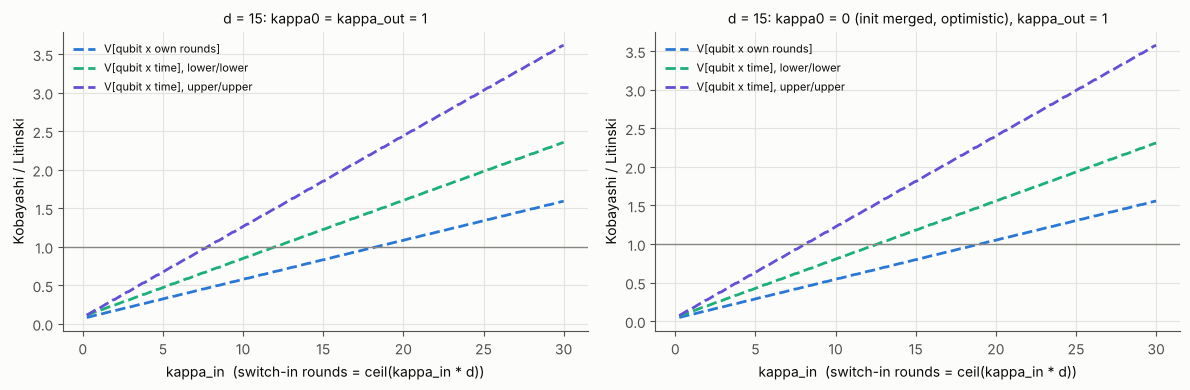

,d,kappa0,kappa_out,breakeven_kappa_in_Vqr,breakeven_kappa_in_Vtime_lb,breakeven_kappa_in_Vtime_ub
0,3,1,1,16.4,11.1,7.1
1,3,0,1,17.0,11.4,7.4
2,3,2,2,14.7,9.7,6.4
3,5,1,1,17.2,11.5,7.5
4,5,0,1,18.0,12.1,7.7
5,5,2,2,16.1,10.2,6.7
6,7,1,1,17.8,11.8,7.6
7,7,0,1,18.5,12.3,7.9
8,7,2,2,16.5,10.5,6.9
9,9,1,1,18.0,11.9,7.7


In [52]:
import math
def k_volume(d, k0, kin, kout, gs='primitive'):
    b = blocks[f'{d}|{gs}']; n = b['n']
    nf = n['fsc_data'] + n['fsc_anc']; n4 = n['d4_data'] + n['d4_anc']
    r0, r1, r4 = math.ceil(k0 * d), math.ceil(kin * d), math.ceil(kout * d)
    Rf, R4 = b['round']['FSC'], b['round']['D4']
    vqr = nf * r0 + n4 * r1 + nf * r4
    const = n['d4_data'] * (b['U_time'] + b['out_time']) + nf * b['xcorr_time']
    vlb = nf * (r0 + r4) * Rf['time_lb'] + n4 * r1 * R4['time_lb'] + const
    vub = nf * (r0 + r4) * Rf['time_ub'] + n4 * r1 * R4['time_ub'] + const
    return vqr, vlb, vub
for d in D_LIST:
    v = k_volume(d, 1, 1, 1); row = K[K.d == d].iloc[0]
    assert (v[0], v[1], v[2]) == (row.V_qubit_round, row.V_qubit_time_lb, row.V_qubit_time_ub), (d, v)
print('reconstruction from blocks reproduces the CSV at kappa=1: OK')
kins = np.linspace(0.25, 30, 240)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dd = D_LIST[-1]
Lrow = Lp[Lp.d == dd].iloc[0]
for ax, (k0, kout, title) in zip(axes, [(1, 1, 'kappa0 = kappa_out = 1'), (0, 1, 'kappa0 = 0 (init merged, optimistic), kappa_out = 1')]):
    vs = np.array([k_volume(dd, k0, k, kout) for k in kins])
    ax.plot(kins, vs[:, 0] / Lrow.V_qubit_round, '--', color=C_KOB, label='V[qubit x own rounds]')
    ax.plot(kins, vs[:, 1] / Lrow.V_qubit_time_lb, '--', color=C_AUX, label='V[qubit x time], lower/lower')
    ax.plot(kins, vs[:, 2] / Lrow.V_qubit_time_ub, '--', color='#6250d6', label='V[qubit x time], upper/upper')
    ax.axhline(1, color='#898781', lw=1)
    ax.set_xlabel('kappa_in  (switch-in rounds = ceil(kappa_in * d))'); ax.set_ylabel('Kobayashi / Litinski')
    ax.set_title(f'd = {dd}: {title}', fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIGURES}/comparison_kappa_sweep.png', dpi=150); plt.show()
rows = []
for d in D_LIST:
    Lr = Lp[Lp.d == d].iloc[0]
    for k0, kout in [(1, 1), (0, 1), (2, 2)]:
        be = {}
        for j, key in enumerate(['V_qubit_round', 'V_qubit_time_lb', 'V_qubit_time_ub']):
            ks = [k for k in np.arange(0.1, 200, 0.1) if k_volume(d, k0, k, kout)[j] >= Lr[key]]
            be[key] = round(ks[0], 1) if ks else None
        rows.append(dict(d=d, kappa0=k0, kappa_out=kout, breakeven_kappa_in_Vqr=be['V_qubit_round'],
                         breakeven_kappa_in_Vtime_lb=be['V_qubit_time_lb'], breakeven_kappa_in_Vtime_ub=be['V_qubit_time_ub']))
be_df = pd.DataFrame(rows); be_df.to_csv(f'{RESULTS}/comparison_breakeven_kappa.csv', index=False); be_df

損益分岐 $\kappa_{in}$：これより大きい定数で switch-in に $\kappa_{in}d$ ラウンドが必要なら、Kobayashi 方式の体積が Litinski 方式（比較A、物理モデル）を上回る。主要項だけで見ると $V_{\rm qubit\cdot round}$ では $8\kappa_0+12\kappa_{in}+8\kappa_{out}=242$ より $\kappa_{in}\approx 18.8$（$\kappa_0=\kappa_{out}=1$）。物理時間の体積では D4 ラウンドの方が深いので損益分岐はより小さい（表）。

## III-4b. ゲート所要時間（CCZ）への感度
III-2 の物理時間は全ゲート 1 単位という仮定に依存する。D4 側のラウンドは CCZ を含むので、CCZ の所要時間 $t_{\rm CCZ}$ を 1〜12 単位で変え、$\kappa_{in}$ と合わせて体積比（物理時間、上界同士・下界同士）がどう変わるかを示す（Litinski 側は CCZ を使わないので不変）。

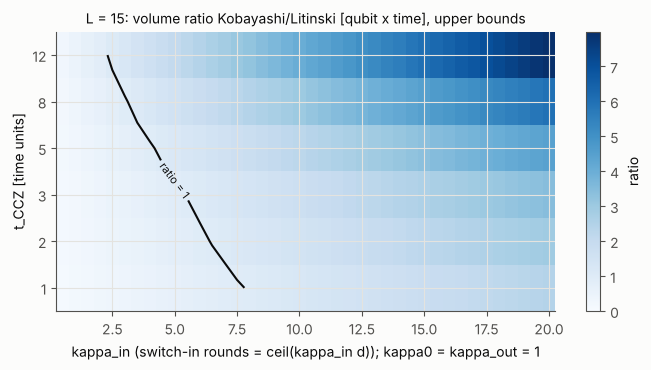

,d,t_CCZ,D4_round_lb,D4_round_ub,ratio_lb_kappa1,ratio_ub_kappa1,breakeven_kappa_in_lb,breakeven_kappa_in_ub
0,15,1,9.0,28,0.168,0.198,12.1,7.9
1,15,2,10.0,34,0.176,0.224,10.9,6.5
2,15,3,12.0,40,0.193,0.249,9.1,5.5
3,15,5,16.0,52,0.227,0.299,6.8,4.3
4,15,8,22.0,70,0.277,0.375,4.9,3.1
5,15,12,30.0,94,0.344,0.476,3.7,2.3


In [53]:
t_list = [1, 2, 3, 5, 8, 12]
d_s = D_LIST[-1]
Lrow_s = Lp[Lp.d == d_s].iloc[0]
cds = {}
for tc in t_list:
    dur_ = dict(DUR_UNIT); dur_['CCZ'] = tc
    cds[tc] = D4CostData(d_s, dur_)
def k_volume_cd(cd, k0, kin, kout):
    n = cd.n; nf = n['fsc_data'] + n['fsc_anc']; n4 = n['d4_data'] + n['d4_anc']; d = cd.L
    r0, r1, r4 = math.ceil(k0 * d), math.ceil(kin * d), math.ceil(kout * d)
    const = n['d4_data'] * (cd.U['time'] + cd.out['time']) + nf * cd.x_corr['time']
    lb = nf * (r0 + r4) * cd.round['FSC']['time_lb'] + n4 * r1 * cd.round['D4']['time_lb'] + const
    ub = nf * (r0 + r4) * cd.round['FSC']['time_ub'] + n4 * r1 * cd.round['D4']['time_ub'] + const
    return lb, ub
assert k_volume_cd(cds[1], 1, 1, 1) == (K[K.d == d_s].iloc[0].V_qubit_time_lb, K[K.d == d_s].iloc[0].V_qubit_time_ub)
rows = []
for tc in t_list:
    lb, ub = k_volume_cd(cds[tc], 1, 1, 1)
    be = {}
    for j, key in enumerate(['V_qubit_time_lb', 'V_qubit_time_ub']):
        ks = [k for k in np.arange(0.1, 60, 0.1) if k_volume_cd(cds[tc], 1, k, 1)[j] >= Lrow_s[key]]
        be[key] = round(ks[0], 1) if ks else None
    rows.append(dict(d=d_s, t_CCZ=tc, D4_round_lb=cds[tc].round['D4']['time_lb'], D4_round_ub=cds[tc].round['D4']['time_ub'],
                     ratio_lb_kappa1=lb / Lrow_s.V_qubit_time_lb, ratio_ub_kappa1=ub / Lrow_s.V_qubit_time_ub,
                     breakeven_kappa_in_lb=be['V_qubit_time_lb'], breakeven_kappa_in_ub=be['V_qubit_time_ub']))
sens_df = pd.DataFrame(rows); sens_df.to_csv(f'{RESULTS}/comparison_sensitivity_tCCZ.csv', index=False)
kgrid = np.linspace(0.5, 20, 40)
Rm = np.array([[k_volume_cd(cds[tc], 1, k, 1)[1] / Lrow_s.V_qubit_time_ub for k in kgrid] for tc in t_list])
fig, ax = plt.subplots(figsize=(7, 3.8))
im = ax.pcolormesh(kgrid, np.arange(len(t_list)), Rm, cmap='Blues', shading='nearest', vmin=0, vmax=max(2, Rm.max()))
cs = ax.contour(kgrid, np.arange(len(t_list)), Rm, levels=[1.0], colors='#0b0b0b', linewidths=1.5)
ax.clabel(cs, fmt='ratio = 1', fontsize=8)
ax.set_yticks(range(len(t_list))); ax.set_yticklabels([str(t) for t in t_list])
ax.set_xlabel('kappa_in (switch-in rounds = ceil(kappa_in d)); kappa0 = kappa_out = 1')
ax.set_ylabel('t_CCZ [time units]')
ax.set_title(f'L = {d_s}: volume ratio Kobayashi/Litinski [qubit x time], upper bounds', fontsize=10)
plt.colorbar(im, ax=ax, label='ratio'); plt.tight_layout(); plt.savefig(f'{FIGURES}/comparison_sensitivity_kappa_tCCZ.png', dpi=150); plt.show()
sens_df.round(3)

CCZ が遅いほど D4 のラウンドが長くなり、損益分岐の $\kappa_{in}$ は小さくなる。比 1 の等高線より左下が「Kobayashi 方式の体積が小さい」領域である（他の仮定はすべて既定値）。

## III-5. ノイズなし最小モデル（`NL_min`）
繰り返し測定を一切しない論理的最小。**耐故障性の主張ではない**（冒頭「理想条件の限界」）。

In [54]:
Kn = pick(d4s, model='NL_min', comparison='A', gateset='primitive', data_only=False)
Ln = pick(msds, model='NL_min', comparison='A', gateset='primitive', data_only=False, level='physical')
nl = pd.DataFrame(dict(d=Kn.d.values, K_peak=Kn.peak_qubits.values, L_peak=Ln.peak_qubits.values,
                       K_rounds=Kn.rounds.values, L_rounds=Ln.rounds.values, K_time_lb=Kn.time_lb.values, K_time_ub=Kn.time_ub.values,
                       L_time_lb=Ln.time_lb.values, L_time_ub=Ln.time_ub.values,
                       K_V_qr=Kn.V_qubit_round.values, L_V_qr=Ln.V_qubit_round.values,
                       ratio_V_time_lb=Kn.V_qubit_time_lb.values / Ln.V_qubit_time_lb.values,
                       ratio_V_time_ub=Kn.V_qubit_time_ub.values / Ln.V_qubit_time_ub.values))
nl.to_csv(f'{RESULTS}/comparison_NL_min_A.csv', index=False); nl.round(3)

,d,K_peak,L_peak,K_rounds,L_rounds,K_time_lb,K_time_ub,L_time_lb,L_time_ub,K_V_qr,L_V_qr,ratio_V_time_lb,ratio_V_time_ub
0,3,83,192,2,11,24.0,30,78.0,144,152,2112,0.118,0.081
1,5,219,544,2,11,24.0,30,78.0,144,404,5984,0.111,0.076
2,7,419,1072,2,11,24.0,30,78.0,144,776,11792,0.108,0.074
3,9,683,1776,2,11,24.0,30,78.0,144,1268,19536,0.107,0.073
4,11,1011,2656,2,11,24.0,30,78.0,144,1880,29216,0.106,0.073
5,13,1403,3712,2,11,24.0,30,78.0,144,2612,40832,0.105,0.072
6,15,1859,4944,2,11,24.0,30,78.0,144,3464,54384,0.105,0.072


## III-6. 比較B：可能な範囲での完全な資源比較

追加で計上するもの
* Litinski：$|m\rangle$ 注入 15 回（各 $t_{\rm inj}=6$ cycles、[Lit] App. A の記述；11-tile 配置では回転ごとに直列）、物理 $T$ ゲート 15 個。
* Kobayashi：物理非 Clifford ゲート（CCZ：測定ガジェット、CS/CS$^\dagger$/$T^\dagger$：$U$）。Clifford+T 分解時の T 数と、分解でラウンドが深くなる効果。
* **FSC → 通常の回転表面符号パッチ変換：未解決**。これは**合計に 0 として含めず**、下の「未計上コスト」の表に分けて示す。したがって比較Bの Kobayashi の合計は変換を含まない**下界**である。参考として「1τ の格子手術（FSC＋2 tiles）」という**例示的仮定**を加えた値も別列に示す（検証された手順ではない）。

In [55]:
unc = pd.DataFrame([dict(protocol=p, comparison=c, uncounted_cost=a, status=b)
                    for p in ['Kobayashi_D4', 'Litinski_15to1'] for c in ['A', 'B'] for a, b in uncounted_costs(p, c)])
unc.to_csv(f'{RESULTS}/uncounted_costs.csv', index=False); unc

,protocol,comparison,uncounted_cost,status
0,Kobayashi_D4,A,classical decoding / control latency,"both comparisons, both protocols"
1,Kobayashi_D4,A,JIT-decoder classical processing,not modelled
2,Kobayashi_D4,B,classical decoding / control latency,"both comparisons, both protocols"
3,Kobayashi_D4,B,JIT-decoder classical processing,not modelled
4,Kobayashi_D4,B,FSC -> standard rotated surface-code patch con...,UNRESOLVED: no protocol constructed
5,Litinski_15to1,A,classical decoding / control latency,"both comparisons, both protocols"
6,Litinski_15to1,A,twist-based Z_m (x) Y_0 seam checks between |m...,"O(d) measurement qubits, not constructed"
7,Litinski_15to1,B,classical decoding / control latency,"both comparisons, both protocols"
8,Litinski_15to1,B,twist-based Z_m (x) Y_0 seam checks between |m...,"O(d) measurement qubits, not constructed"


In [56]:
rows = []
for d in D_LIST:
    for gs in ['primitive', 'clifford_t']:
        k = pick(d4s, model='FT_ref', comparison='B', gateset=gs, data_only=False); k = k[k.d == d].iloc[0]
        l = pick(msds, model='FT_ref', comparison='B', gateset=gs, data_only=False, level='physical'); l = l[l.d == d].iloc[0]
        nf = blocks[f'{d}|{gs}']['n']; conv_q = nf['fsc_data'] + nf['fsc_anc'] + 4 * d * d
        rows.append(dict(d=d, gateset=gs, K_peak=k.peak_qubits, L_peak=l.peak_qubits,
                         K_time_lb=k.time_lb, K_time_ub=k.time_ub, L_time_lb=l.time_lb, L_time_ub=l.time_ub,
                         K_V_time_lb=k.V_qubit_time_lb, K_V_time_ub=k.V_qubit_time_ub,
                         L_V_time_lb=l.V_qubit_time_lb, L_V_time_ub=l.V_qubit_time_ub,
                         K_V_qr=k.V_qubit_round, K_V_qr_with_illustrative_conversion=k.V_qubit_round + conv_q * d,
                         L_V_qr=l.V_qubit_round,
                         K_nonclifford=k.nonclifford, L_nonclifford=l.nonclifford,
                         K_Tcount_if_decomposed=k.T_count_if_decomposed, L_Tcount=l.T_count_if_decomposed))
Bdf = pd.DataFrame(rows); Bdf.to_csv(f'{RESULTS}/comparison_B_FT_ref.csv', index=False)
Bdf[Bdf.gateset == 'primitive'][['d', 'K_peak', 'L_peak', 'K_V_qr', 'K_V_qr_with_illustrative_conversion', 'L_V_qr', 'K_nonclifford', 'L_nonclifford', 'K_Tcount_if_decomposed', 'L_Tcount']]

,d,K_peak,L_peak,K_V_qr,K_V_qr_with_illustrative_conversion,L_V_qr,K_nonclifford,L_nonclifford,K_Tcount_if_decomposed,L_Tcount
0,3,119,192,855,1212,17496,"{""CCZ"": 72.0, ""CS"": 9.0, ""CSDG"": 4.0, ""TDG"": 6.0}","{""T"": 15.0}",549,15
2,5,319,544,3785,5380,61816,"{""CCZ"": 480.0, ""CS"": 25.0, ""CSDG"": 16.0, ""TDG""...","{""T"": 15.0}",3493,15
4,7,615,1072,10171,14476,145544,"{""CCZ"": 1512.0, ""CS"": 49.0, ""CSDG"": 36.0, ""TDG...","{""T"": 15.0}",10853,15
6,9,1007,1776,21357,30420,280296,"{""CCZ"": 3456.0, ""CS"": 81.0, ""CSDG"": 64.0, ""TDG...","{""T"": 15.0}",24645,15
8,11,1495,2656,38687,55132,477688,"{""CCZ"": 6600.0, ""CS"": 121.0, ""CSDG"": 100.0, ""T...","{""T"": 15.0}",46885,15
10,13,2079,3712,63505,90532,749336,"{""CCZ"": 11232.0, ""CS"": 169.0, ""CSDG"": 144.0, ""...","{""T"": 15.0}",79589,15
12,15,2759,4944,97155,138540,1106856,"{""CCZ"": 17640.0, ""CS"": 225.0, ""CSDG"": 196.0, ""...","{""T"": 15.0}",124773,15


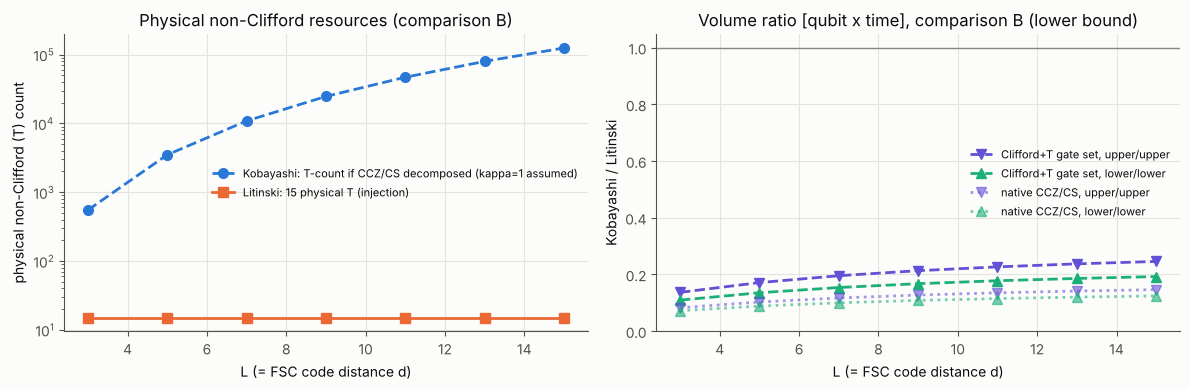

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
Bp = Bdf[Bdf.gateset == 'primitive']; Bc = Bdf[Bdf.gateset == 'clifford_t']
ax = axes[0]
ax.plot(Bp.d, Bp.K_Tcount_if_decomposed, 'o--', color=C_KOB, label='Kobayashi: T-count if CCZ/CS decomposed (kappa=1 assumed)')
ax.plot(Bp.d, Bp.L_Tcount, 's-', color=C_LIT, label='Litinski: 15 physical T (injection)')
ax.set_yscale('log'); ax.set_xlabel('L (= FSC code distance d)'); ax.set_ylabel('physical non-Clifford (T) count')
ax.set_title('Physical non-Clifford resources (comparison B)'); ax.legend(fontsize=8)
ax = axes[1]
ax.plot(Bc.d, Bc.K_V_time_ub / Bc.L_V_time_ub, 'v--', color='#6250d6', label='Clifford+T gate set, upper/upper')
ax.plot(Bc.d, Bc.K_V_time_lb / Bc.L_V_time_lb, '^--', color=C_AUX, label='Clifford+T gate set, lower/lower')
ax.plot(Bp.d, Bp.K_V_time_ub / Bp.L_V_time_ub, 'v:', color='#6250d6', alpha=0.6, label='native CCZ/CS, upper/upper')
ax.plot(Bp.d, Bp.K_V_time_lb / Bp.L_V_time_lb, '^:', color=C_AUX, alpha=0.6, label='native CCZ/CS, lower/lower')
ax.axhline(1, color='#898781', lw=1); ax.set_ylim(0, None)
ax.set_xlabel('L (= FSC code distance d)'); ax.set_ylabel('Kobayashi / Litinski')
ax.set_title('Volume ratio [qubit x time], comparison B (lower bound)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIGURES}/comparison_B.png', dpi=150); plt.show()

## III-7. 仮定・未確定事項の一覧（表）
詳細な説明は `docs/02_assumptions_and_open_issues.md`。

In [58]:
assump = pd.DataFrame([
    ('A1', 'Kobayashi switch-in rounds = ceil(kappa_in d), kappa_in=1', 'assumption', '[KZH] states only O(d); [Dav] full text not accessible here'),
    ('A2', 'Kobayashi FSC EC rounds after return = ceil(kappa_out d), kappa_out=1', 'assumption', '[KZH] O(d)'),
    ('A3', 'FSC |+_L> preparation rounds = ceil(kappa0 d), kappa0=1', 'assumption', 'not specified in [KZH]; Litinski counts patch init as 0 tau'),
    ('A4', 'Litinski 1 tau = d code cycles', 'literature', '[Lit] Sec. 1'),
    ('A5', 'Every primitive gate / init / measurement = 1 time unit', 'assumption', 'parametrised (DUR)'),
    ('A6', 'Clifford stabilizers measured by ancilla-controlled-S (CNOT + CCZ) gadgets', 'our construction (validated)', 'circuit not given in [KZH]; V9'),
    ('A7', 'Round schedule: commuting-class upper bound / busiest-qubit lower bound', 'our construction (validated)', 'V10; optimised interleavings could be shorter'),
    ('A8', 'Frozen boundary qubits not allocated; gates on them dropped', 'counting rule', 'same rule for both codes'),
    ('A9', 'Litinski multi-patch P(x)Z_m surgeries constructed explicitly (M9); Z_m(x)Y_0 twist seam not constructed', 'counted / partly uncounted', 'M9; O(d) twist-seam checks uncounted'),
    ('A10', 'Injection: 3+3 cycles per |m>, serial in the 11-tile layout', 'literature', '[Lit] App. A, Sec. 3.3 Caveat'),
    ('A11', 'Classical processing / decoding latency = 0', 'assumption', 'both protocols'),
    ('U1', 'FSC -> standard rotated patch conversion', 'UNRESOLVED', 'excluded in B (lower bound); illustrative 1-tau value shown separately'),
    ('U2', 'D4-phase Knill-Laflamme distance for L >= 6 (7 with FULL_KL)', 'UNVERIFIED', 'proven = L for L <= 5 (V5b), L = 6 with FULL_KL'),
    ('U3', 'Fault tolerance of the switching (JIT decoder) and value of kappa', 'UNRESOLVED', 'requires noisy simulation (next stage)'),
], columns=['id', 'item', 'status', 'basis / note'])
assump.to_csv(f'{RESULTS}/assumptions_table.csv', index=False); assump

,id,item,status,basis / note
0,A1,"Kobayashi switch-in rounds = ceil(kappa_in d),...",assumption,[KZH] states only O(d); [Dav] full text not ac...
1,A2,Kobayashi FSC EC rounds after return = ceil(ka...,assumption,[KZH] O(d)
2,A3,"FSC |+_L> preparation rounds = ceil(kappa0 d),...",assumption,not specified in [KZH]; Litinski counts patch ...
3,A4,Litinski 1 tau = d code cycles,literature,[Lit] Sec. 1
4,A5,Every primitive gate / init / measurement = 1 ...,assumption,parametrised (DUR)
5,A6,Clifford stabilizers measured by ancilla-contr...,our construction (validated),circuit not given in [KZH]; V9
6,A7,Round schedule: commuting-class upper bound / ...,our construction (validated),V10; optimised interleavings could be shorter
7,A8,Frozen boundary qubits not allocated; gates on...,counting rule,same rule for both codes
8,A9,Litinski multi-patch P(x)Z_m surgeries constru...,counted / partly uncounted,M9; O(d) twist-seam checks uncounted
9,A10,"Injection: 3+3 cycles per |m>, serial in the 1...",literature,"[Lit] App. A, Sec. 3.3 Caveat"


## III-8. 結論（理想条件下、指定した 2 プロトコルの回路構造に関する**予備的**評価）

1. **正しさ**：Kobayashi 方式は、境界付き D4 符号（Fig. 4）上で $U=WV$ が論理 $T^\dagger$ を実装し、ランダムな測定結果に対する補正（$Z^rZ^b$ の Pauli フレーム補正と $S^g_X$ の CZ 補正）を含めて FSC 上に $T^\dagger|+\rangle$ を生成する。根拠は、$L\le2$ の符号状態の厳密シミュレーション、$L\le4$ での回路と位相公式の照合、$L\le 8$ の位相公式の局所厳密証明（それぞれ意味の異なる検証）。D4 相の距離が $L$ であることは $L\le5$（6）で証明済み。Litinski 方式は 15-to-1 の論理動作・誤り検出・auto-corrected π/8・11 tiles × 11τ・$121d^3$ を再現し、11 回の多パッチ測定を物理レベルで明示的に構成・検証した（$Z_m\otimes Y_0$ の twist 継ぎ目を除く）。
2. **量子ビット数**（計数）：ピークで Kobayashi $12L^2+4L-1$ に対し Litinski $22d^2-6$（データ＋測定量子ビット、$L=d$）。
3. **時間・体積**（仮定に依存）：$\kappa=1$・全ゲート 1 単位では、Kobayashi は $3d$ ラウンド＋定数深さ、Litinski は $11d$ ラウンドで、体積比は約 0.1〜0.2。しかしこれは仮定に強く依存する：損益分岐 $\kappa_{in}$ は qubit·round 体積で約 15〜19、物理時間体積で約 6〜13（III-4）、さらに CCZ が遅いと小さくなる（III-4b）。**$O(d)$ の定数とゲート時間が確定するまで、優劣は確定しない**。
4. **比較B**：Kobayashi 方式は $\Theta(d^3)$ 個の物理 CCZ（Clifford+T 分解で $\approx 42d^3$ 個の T）を使うのに対し、Litinski 方式の物理非 Clifford 資源は T 15 個。FSC→通常パッチ変換は未解決で、合計には含めず「未計上コスト」として分離した。比較Bは**共通のスタートとゴールからの完全な比較としては未完成**である。
5. **限界**：ノイズ0では蒸留は本来不要であり、本比較は最適な T ゲート実装法を決めるものではない。論文の主張として使うには、ノイズ下での $\kappa$ の決定、変換回路の構成、ハードウェアに即したゲート時間が必要である。